# GLayout — Combined Tutorials (Google Colab edition)

This notebook bundles the gLayout tutorial notebooks from
[ReaLLMASIC/gLayout](https://github.com/ReaLLMASIC/gLayout) into a single
notebook that runs **entirely in the cloud on Google Colab** — no local EDA
setup required.

## How to run

1. Run **Setup Cell 1/2** below (one-time installs, ~10–15 min). At the end the
   runtime **restarts itself** — the *"Your session crashed"* banner is
   **expected and harmless**.
2. After the restart, run **Setup Cell 2/2** (per-session environment). Re-run
   it at the start of every new session.
3. Run any Part you like, top to bottom. (Or *Runtime ▸ Run all* — Cell 1/2
   detects the finished install and skips itself.)

## Contents

| Part | Topic | Needs |
|---|---|---|
| 1 | GLayout introduction (glayers, primitives, routing) | base setup |
| 2 | Via creation (glayers & grules) | base setup |
| 3 | Built-in cells (primitives → full op-amp) | base setup |
| 4 | Current mirror | base setup |
| 5 | Two-stage op-amp (sky130) | base setup |
| 6–7 | 5T OTA: layout, then DRC + LVS | EDA tools (magic, netgen) |
| 8–9 | Flipped Voltage Follower: layout + DRC, then LVS + PEX + ngspice | EDA tools (klayout, magic, netgen, ngspice) |
| 10–11 | CMOS inverter: layout + DRC, then LVS + PEX | EDA tools (klayout, magic, netgen) |
| 12–14 | BJT tutorials (glayout, custom-pattern routing, raw gdsfactory) | EDA tools (magic) for extraction cells |
| 15 | Dataset generation (`dataset_total`) | base setup |

Ordering rules: run Part 6 before 7, Part 8 before 9, and Part 10 before 11
(the part-1 notebooks generate helper modules that part 2 imports).

> **Note** — each Part re-defines its own `display_gds` / `display_component`
> helpers (with slightly different signatures), so always run a Part's cells
> top-to-bottom rather than jumping between Parts.

```
SPDX-License-Identifier: Apache-2.0 (tutorial content, OpenFASOC / gLayout Team)
```


***
# Part 0 — Environment Setup (run this first!)

**What gets installed** (all inside the Colab VM, ~5 GB disk total):

| What | How | Why |
|---|---|---|
| `gdsfactory 7.7.0`, `numpy 1.26.4`, `gdstk`, `svgutils`, … | `pip` (pinned) | the exact known-good combination gLayout 0.2 is written against (gdsfactory 8/9 and numpy 2 are **not** compatible) |
| `glayout` | `git clone` + `pip install -e --no-deps` | the tutorials' import layout (`glayout.primitives…`, `glayout.cells…`) matches this repo, not the older PyPI `glayout` package |
| sky130A + gf180mcuD PDKs | [`volare`](https://github.com/efabless/volare) | PDK files under one `PDK_ROOT`; gLayout reads `PDK_ROOT` **at import time** |
| `magic`, `netgen`, `ngspice`, `klayout` | `micromamba` (litex-hub / conda-forge channels) into `/content/eda` | CLI tools used by the DRC / LVS / PEX / simulation cells; installed apart from the Python env so they can't break the pinned pip packages |

The environment variables the notebooks rely on (see `tutorial/HOW_TO_RUN.md`
in the repo):

- `PDK_ROOT` — directory that contains `sky130A/` and `gf180mcuD/`
- `PDK` — active PDK variant (`gf180mcuD` by default here)
- `PDKPATH` — `$PDK_ROOT/$PDK`, used by the magic/netgen/ngspice cells


In [ ]:
# ╔════════════════════════════════════════════════════════════════════╗
# ║ ENVIRONMENT SETUP — CELL 1/2 : one-time installs (~10–15 min)      ║
# ║                                                                    ║
# ║ The runtime RESTARTS ITSELF at the end — this is EXPECTED, and the ║
# ║ "Your session crashed" banner is normal. After the restart, do NOT ║
# ║ re-run this cell: continue with CELL 2/2 below.                    ║
# ╚════════════════════════════════════════════════════════════════════╝
import os, sys, pathlib

IN_COLAB = "google.colab" in sys.modules
WORKDIR = "/content" if IN_COLAB else os.path.expanduser("~/glayout_colab")
PDK_ROOT = f"{WORKDIR}/pdk"
GLAYOUT_REPO = "https://github.com/ReaLLMASIC/gLayout.git"
# open_pdks build these tutorials were tested against (same as the local setup)
OPEN_PDKS_VERSION = "0fe599b2afb6708d281543108caf8310912f54af"

DONE_FLAG = pathlib.Path(WORKDIR) / ".glayout_env_ready"

if not IN_COLAB:
    print("Not running in Google Colab — skipping installs.")
    print("For a local setup, follow tutorial/HOW_TO_RUN.md from the repo instead.")
elif DONE_FLAG.exists():
    print("Environment already installed — continue with Setup Cell 2/2.")
else:
    print(">>> [1/4] Installing pinned Python packages (gdsfactory 7.7.0 / numpy 1.26.4) ...")
    !pip install -q "gdsfactory==7.7.0" "numpy==1.26.4" gdstk svgutils prettyprint PrettyPrintTree nltk ipywidgets docopt volare

    print(">>> [2/4] Cloning + installing gLayout ...")
    if not pathlib.Path(f"{WORKDIR}/gLayout").exists():
        !git clone --depth 1 {GLAYOUT_REPO} {WORKDIR}/gLayout
    !pip install -q --no-deps -e {WORKDIR}/gLayout

    print(">>> [3/4] Downloading PDKs with volare (sky130 + gf180mcu, ~3 GB) ...")
    os.makedirs(PDK_ROOT, exist_ok=True)
    !volare enable --pdk sky130 --pdk-root {PDK_ROOT} {OPEN_PDKS_VERSION}
    !volare enable --pdk gf180mcu --pdk-root {PDK_ROOT} {OPEN_PDKS_VERSION}

    print(">>> [4/4] Installing EDA tools (magic / netgen / ngspice / klayout) ...")
    !curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj -C {WORKDIR} bin/micromamba
    !MAMBA_ROOT_PREFIX={WORKDIR}/mamba {WORKDIR}/bin/micromamba create -yq -p {WORKDIR}/eda -c litex-hub -c conda-forge magic netgen ngspice
    _rc = os.system(f"MAMBA_ROOT_PREFIX={WORKDIR}/mamba {WORKDIR}/bin/micromamba install -yq -p {WORKDIR}/eda -c litex-hub -c conda-forge klayout")
    if _rc != 0:
        print("klayout not available via conda here — falling back to the Ubuntu package ...")
        !apt-get -qq update && apt-get -qq install -y klayout

    DONE_FLAG.touch()
    print("=" * 72)
    print("Setup finished. The runtime will now RESTART ITSELF — this is expected!")
    print("('Your session crashed' banner = normal.)")
    print("After the restart, skip this cell and run Setup Cell 2/2.")
    print("=" * 72)
    os.kill(os.getpid(), 9)  # hard restart so the pinned numpy is loaded cleanly


In [ ]:
# ╔════════════════════════════════════════════════════════════════════╗
# ║ ENVIRONMENT SETUP — CELL 2/2 : per-session environment             ║
# ║ Run this at the start of EVERY session (incl. right after the      ║
# ║ automatic restart triggered by Cell 1/2).                          ║
# ╚════════════════════════════════════════════════════════════════════╝
import os, sys, shutil, pathlib

IN_COLAB = "google.colab" in sys.modules
WORKDIR = "/content" if IN_COLAB else os.path.expanduser("~/glayout_colab")

# ---- PDK env vars: MUST be set before the first `import glayout` ----------
# (glayout's sky130/gf180 modules read PDK_ROOT at import time; if it is
#  missing they silently become None and later calls fail with AttributeError)
os.environ.setdefault("PDK_ROOT", f"{WORKDIR}/pdk")
os.environ.setdefault("PDK", "gf180mcuD")
os.environ.setdefault("PDKPATH", os.path.join(os.environ["PDK_ROOT"], os.environ["PDK"]))

# ---- EDA tools (magic / netgen / ngspice / klayout) on PATH ----------------
_eda_bin = f"{WORKDIR}/eda/bin"
if os.path.isdir(_eda_bin) and _eda_bin not in os.environ["PATH"].split(os.pathsep):
    os.environ["PATH"] = _eda_bin + os.pathsep + os.environ["PATH"]

# ---- stable working directory (the tutorials use relative paths) ----------
if IN_COLAB:
    _run_dir = pathlib.Path(WORKDIR) / "glayout_run"
    _run_dir.mkdir(exist_ok=True)
    os.chdir(_run_dir)

# ---- sanity checks ---------------------------------------------------------
import numpy, gdsfactory
from glayout import gf180, sky130
assert gf180 is not None and sky130 is not None, (
    "glayout PDK objects are None. Usual cause: PDK_ROOT was not set before "
    "importing glayout. Fix: Runtime > Restart session, then run THIS cell first."
)
print("python      :", sys.version.split()[0])
print("numpy       :", numpy.__version__)
print("gdsfactory  :", gdsfactory.__version__)
print("PDK_ROOT    :", os.environ["PDK_ROOT"])
print("PDKPATH     :", os.environ["PDKPATH"])
for _t in ("klayout", "magic", "netgen", "ngspice"):
    print(f"{_t:12s}:", shutil.which(_t) or "not found (only needed for DRC/LVS/PEX/simulation cells)")

# ---- inline GDS viewer + headless Component.show() -------------------------
import gdstk, IPython.display
import svgutils.transform as sg

def display_gds(gds_file, scale=3):
    top = gdstk.read_gds(gds_file).top_level()[0]
    top.write_svg("out.svg")
    fig = sg.fromfile("out.svg")
    fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
    fig.save("out.svg")
    IPython.display.display(IPython.display.SVG("out.svg"))

def display_component(component, scale=3):
    component.write_gds("out.gds")
    display_gds("out.gds", scale)

if IN_COLAB:
    # No klayout GUI in Colab: render Component.show() inline instead.
    gdsfactory.Component.show = lambda self, *a, **k: display_component(self)

print()
print("Environment ready ✔")


***
# Part 1 — GLayout Introduction

*Source: `notebook/GLayout_Introduction.ipynb`* · **Needs:** base setup only (layout-only).

# GLayout Quick Start Guide

```
OpenFASOC Team, Feb 2024
SPDX-License-Identifier: Apache-2.0
```

## Introduction
Welcome!
This notebook serves as an introduction to the GDSFactory-based layout automation tool **GLayout** and a demonstration of the functions and classes you will primarily be using.

In [ ]:
from glayout import gf180, sky130
import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Redirect all outputs here
hide = widgets.Output()

def display_gds(gds_file, scale = 3):
  # Generate an SVG image
  top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
  top_level_cell.write_svg('out.svg')
  # Scale the image for displaying
  fig = sg.fromfile('out.svg')
  fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
  fig.save('out.svg')

  # Display the image
  IPython.display.display(IPython.display.SVG('out.svg'))

def display_component(component, scale = 3):
  # Save to a GDS file
  with hide:
    component.write_gds("out.gds")
  display_gds('out.gds', scale)



# Introduction to GLayout

## Overview

This document provides a detailed tutorial on using the GLayout API.

## Prerequisites

Ensure that you have the following installed:
- Python environment with access to GLayout API.
- GDSFactory package for handling generic layout components.
- A PDK (Process Design Kit) appropriate for the technology node you're working on

## GLayers
Processes often have a shared set of layers. We access these layers using generic layers.
We support
1. n well
2. n/p select
3. diffusion
4. poly
5. metal 1
6. metal 2
7. metal 3
8. Mcon
9. via 1
10. via 2

As you can see in the following code examples we use `pdk.get_glayer(<layer name>)` in order to get a tuple associated with a layer.

This tuple associated the generic layer with a PDK's layer.

In [ ]:
gf180_met1 = gf180.get_glayer("met1")
gf180_met1 = gf180.get_glayer("met1")
print(gf180_met1)
print(gf180_met1)

## GRules
GRules is how you access layout rules for a layer.

### Examples
1. Remember the via example? In that example we wanted to access the minimum width of a via
2. In the via example we want to find the minimum enclosure of a via inside of a metal contact.
3. When you want to space two metal tracks


In [ ]:
# Minimum width for a via example
min_width_via1 = gf180.get_grule('via1')['width']
print(f"min width for via: {min_width_via1}")

Minimum Enclosure Example
Lets do it for gf180

In [ ]:
min_enc_met1 = gf180.get_grule('via1','met1')['min_enclosure']
min_enc_met2 = gf180.get_grule('via1','met2')['min_enclosure']
print("gf180")
print(f"min enclosure metal1 and via: {min_enc_met1}")
print(f"min enclosure metal2 and via: {min_enc_met2}")

# Lets do the same for gf180
min_enc_met1 = gf180.get_grule('via1','met1')['min_enclosure']
min_enc_met2 = gf180.get_grule('via1','met2')['min_enclosure']
print("Gf180")
print(f"min enclosure metal1 and via: {min_enc_met1}")
print(f"min enclosure metal1 and via: {min_enc_met2}")

In [ ]:
# Minimum Spacing Example
min_met1_spacing = gf180.get_grule('met1','met1')['min_separation']
print(f"min spacing between metal: {min_met1_spacing}")

## Drawing layouts
We draw rectangles for layers using gdsfactory
For now, lets use the rules we just used to make a very simple metal rectangle. Here we have an example where we draw a simple metal track.

In [ ]:
from gdsfactory import Component
from gdsfactory.components import rectangle

def makeMet1Rectangle(pdk, length):
  met1 = pdk.get_glayer("met1")
  met1_width = pdk.get_grule("met1")["min_width"]
  top_level = Component(name="metal_track")
  top_level << rectangle(size=(length, met1_width), layer=met1)
  return top_level

metalTrack = makeMet1Rectangle(gf180,3)
metalTrack.write_gds('metaltrack.gds')
display_gds('metaltrack.gds',scale=20)

## Using and Manipulating Components
In the previous section, we made a component that just consists of a metal track. Now lets use this component to make other components. This is called hierarchal design. Here we introduce the `evaluate_bbox` and `movey`

In [ ]:
from glayout.util.comp_utils import evaluate_bbox

def makeAdjacentMetal1Tracks(pdk, length):
  track1 = makeMet1Rectangle(pdk, length)
  track2 = makeMet1Rectangle(pdk, length)
  top_level = Component(name="adjacent_metal_tracks")
  track1_ref = top_level << track1
  track2_ref = top_level << track2
  width = evaluate_bbox(track1)[1] # gets the dimension on the y axis
  track2_ref.movey(width + pdk.get_grule('met1','met1')['min_separation'])
  return top_level

adjMetalTrack = makeAdjacentMetal1Tracks(gf180,3)
adjMetalTrack.write_gds('adjmetaltrack.gds')
display_gds('adjmetaltrack.gds',scale=20)


# ## Primitives
# GLayout provides many primitives that you can use instead of doing everything from the bottom up. You can find all of the primitives [here](https://github.com/idea-fasoc/OpenFASOC/tree/main/openfasoc/generators/glayout/glayout/flow/primitives)
# I will place a pmos and a nmos side by side in the example below:

In [ ]:
from glayout import pmos,nmos

def placeTwoTrasistors(pdk):
  pfet = pmos(pdk)
  nfet = nmos(pdk,with_dnwell=False)
  top_level = Component()
  pfet_ref = top_level << pfet
  nfet_ref = top_level << nfet
  compSep = pdk.util_max_metal_seperation()
  nfet_ref.movex(compSep + evaluate_bbox(pfet)[0])
  return top_level

twoTransistors = placeTwoTrasistors(gf180)
twoTransistors.write_gds('twotransistors.gds')
display_gds('twotransistors.gds',scale=2)

## Routing and Ports
How do we connect the ports of transistors. In this section we'll make a current mirror

In [ ]:
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route

def currentMirror(pdk):
  currMirrComp = Component()
  pfet_ref = pmos(pdk, with_substrate_tap=False, with_dummy=(False, True))
  pfet_mir = pmos(pdk, with_substrate_tap=False, with_dummy=(True, False))
  cref_ref = currMirrComp << pfet_ref
  cmir_ref = currMirrComp << pfet_mir
  cref_ref.movex(evaluate_bbox(pfet_mir)[0] + pdk.util_max_metal_seperation())
  currMirrComp << straight_route(pdk, cref_ref.ports["multiplier_0_source_E"], cmir_ref.ports["multiplier_0_source_E"])
  currMirrComp << straight_route(pdk, cref_ref.ports["multiplier_0_gate_E"], cmir_ref.ports["multiplier_0_gate_E"])
  currMirrComp << c_route(pdk, cref_ref.ports["multiplier_0_drain_E"], cref_ref.ports["multiplier_0_gate_E"])
  return currMirrComp

currentMirror(gf180).write_gds("cmirror_example.gds")
display_gds("cmirror_example.gds")

In [ ]:
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route


def Inverter(pdk):
  inverter = Component()
  pfet_ref = pmos(pdk, with_substrate_tap=False, with_dummy=(False, True), fingers=3)
  nfet_ref = nmos(pdk, with_substrate_tap=False, with_dummy=(True, False), fingers=2)
  _1 = inverter << pfet_ref
  _2 = inverter << nfet_ref
  # move nfet to the right of pfet
  _1.movex(evaluate_bbox(nfet_ref)[0] + pdk.util_max_metal_seperation())

  inverter << c_route(pdk, _1.ports["multiplier_0_source_E"], _2.ports["multiplier_0_drain_E"])
  inverter << straight_route(pdk, _1.ports["multiplier_0_gate_E"], _2.ports["multiplier_0_gate_E"])
  
  return inverter


Inverter(gf180).write_gds("inverter_example.gds")
display_gds("inverter_example.gds")

***
# Part 2 — Simple Via Creation (glayers & grules)

*Source: `notebook/GLayout_Via.ipynb`* · **Needs:** base setup only (layout-only).

# GLayout Simple Via Creation Tutorial

```
OpenFASOC Team, June 2025
SPDX-License-Identifier: Apache-2.0
```


## Introduction
Welcome!
This notebook serves as an introduction to the GDSFactory-based layout automation tool **GLayout** and an example producing a VIA to explain grules and glayers, as a part of [OpenFASoC](https://github.com/idea-fasoc/OpenFASOC).  

## Tool requirements
### All the requirements are contained in OSIC-IIC-TOOLS
**Python Dependencies**
* [`gdsfactory`](https://github.com/gdsfactory/gdsfactory): Provides the backend for GDS manipulation.
* [`sky130`](https://github.com/gdsfactory/skywater130): The Skywater 130nm PDK Python package for GDSFactory to use in this demo.
* [`gf180`](https://github.com/gdsfactory/gf180): The GF 180nm PDK Python package for GDSFactory to use in this demo.
* [`gdstk`](https://heitzmann.github.io/gdstk/): (installed as a part of gdsfactory) Used for converting GDS files into SVG images for viewing.
* [`svgutils`](https://svgutils.readthedocs.io/en/latest/): To scale the SVG image.

**System Dependencies**
* [`klayout`](https://klayout.de/): For DRC (Design Rule Checking).



#### 1.1. Importing Libraries and Utility Functions

In [ ]:
import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Redirect all outputs here
hide = widgets.Output()

def display_gds(gds_file, scale = 3):
  # Generate an SVG image
  top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
  top_level_cell.write_svg('out.svg')
  # Scale the image for displaying
  fig = sg.fromfile('out.svg')
  fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
  fig.save('out.svg')

  # Display the image
  IPython.display.display(IPython.display.SVG('out.svg'))

def display_component(component, scale = 3):
  # Save to a GDS file
  with hide:
    component.write_gds("out.gds")
  display_gds('out.gds', scale)

**1. Import Required Modules**

The via function will use several imports:

* a pdk from glayout: PDK for GF180/SKY130 (180-nanometer technology node) provided by the glayout package. The PDK contains technology-specific information including rules and layers.

* Component from gdsfactory: This is a class representing a layout component, which includes polygons, paths, etc.

* rectangle from gdsfactory.components: This function creates a rectangle polygon.

In [ ]:
from glayout import sky130, gf180
from gdsfactory import Component
from gdsfactory.components import rectangle

**2. Define the Via Function**

The function create_via which takes a single argument which is the PDK. Inside the function, the following steps are executed:

* Via Dimensions: Using the get_grule method of the PDK object, the width of the via is retrieved from the technology's design rules. This rule specifies the minimum size that the via can be. This dimension is set as both the length and width for a via.

* Metal Dimensions: The dimensions of the metal layers above and below the via are determined. These dimensions must accommodate the via and any required enclosure space as mandated by the PDK. Enclosure space refers to the required minimum spacing between the edge of the via and the edge of the surrounding metal layer.

* Layer Retrieval: The get_glayer method retrieves the specific layer numbers or names from the PDK. These are then used to assign the correct graphical layers to the shapes that will be generated.

* Shape Creation and Placement: An empty Component instance named top_level is created, representing the top component in which all shapes will be placed. Using the insertion operator (<<), rectangles representing the metal layers and via are added to the top_level component with their specified sizes and layers.

* Return Value: The top_level component, now containing the layout shapes for the metals and via, is the return value of the function. This component can be written out as a GDSII file.

In [ ]:
def create_via(pdk):
  # Define the via dimensions and rules
  via_dimension = pdk.get_grule('via1')['width']
  metal1_dimension = via_dimension + 2 * pdk.get_grule('via1','met1')['min_enclosure']
  metal2_dimension = via_dimension + 2 * pdk.get_grule('via1','met2')['min_enclosure']

  # Get the layers for via and metals
  via_layer = pdk.get_glayer('via1')
  metal1_layer = pdk.get_glayer('met1')
  metal2_layer = pdk.get_glayer('met2')

  # Create the component and add the layers
  top_level = Component(name='via_example')
  top_level << rectangle(size=(via_dimension, via_dimension), layer=via_layer)
  top_level << rectangle(size=(metal1_dimension, metal1_dimension), layer=metal1_layer)
  top_level << rectangle(size=(metal2_dimension, metal2_dimension), layer=metal2_layer)

  return top_level

**4. Run the Via Function and Generate Layout**

In [ ]:
create_via(pdk=gf180).write_gds("via_example_gf180.gds")

**5. View the Generated Layout**
- Open KLayout and load the generated GDS file to view your layout.
- Or view in notebook with the following code block.

In [ ]:
display_gds('via_example_gf180.gds',scale=20)

By concluding these steps, you will have downloaded Glayout, installed the necessary dependencies, and completed the construction of a simple via using Glayout.

***
# Part 3 — Built-in Cells (primitives → full op-amp)

*Source: `notebook/GLayout_Cells.ipynb`* · **Needs:** base setup only (layout-only).

# GLayout: List of Built-in Cells
```
OpenFASOC Team, Feb 2024
SPDX-License-Identifier: Apache-2.0
```

## Introduction
Welcome!
This notebook serves as an introduction to the GDSFactory-based layout automation tool **GLayout** and an example two-stage Operational Amplifier (Op-Amp) generator, as a part of [OpenFASoC](https://github.com/idea-fasoc/OpenFASOC).  

### List of Generators

**Utility Generators**
- Via
- Guardring
- Routing (Straight, L, and C)

**PCell Generators**
1. Primitive Cells / `glayout.primitives`
  - FET (NMOS, PMOS)
  - MIM Capacitor
  - Guard Rings with Metalization
  - Via


2. Intermediate PCells / `glayout.components`
  - Differential Pair
  - Differential to Single-Ended Converter


3. WIP PCells (The cells can be used inside other PCells, but are not available as standalone PCells yet)
  - Current Mirror

**High-Level Design Examples**
- OPAMP / `glayout.components.opamp`

In [ ]:
from glayout import gf180, sky130
import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Redirect all outputs here
hide = widgets.Output()

def display_gds(gds_file, scale = 3):
  # Generate an SVG image
  top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
  top_level_cell.write_svg('out.svg')
  # Scale the image for displaying
  fig = sg.fromfile('out.svg')
  fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
  fig.save('out.svg')

  # Display the image
  IPython.display.display(IPython.display.SVG('out.svg'))

def display_component(component, scale = 3):
  # Save to a GDS file
  with hide:
    component.write_gds("out.gds")
  display_gds('out.gds', scale)

## List of Built-in Cells

### 1. Primitives
#### MOSFET (nmos/pmos)

**Parameters:**
- **pdk:** Which PDK to use
- **width:** Width of one finger (um)
- **length:** Length of one finger (um). The default value is the minimum channel length available
- **fingers:** Number of fingers per transistor
- **multipliers:** Number of transistors in this cell
- **with_tie:** bool
- **with_dummy:** tuple of 2 bools
- **with_dnwell:** bool
- **with_substrate_tap:** bool
- **sd_route_topmet:** Expose the S/D connection on which metal layer
- **gate_route_topmet:** Expose the Gate connection on which metal layer
- **sd_route_left:** Choose which direction the S/D connection goes to
- **rmult:** Integer multipler of routing width
- **sd_rmult:** Same as above
- **gate_rmult:** Same as above
- **interfinger_rmult:** Same as above
- **tie_layers:** Run the body tie metal on which layer. This entry is a tuple with 2 elements
    - X metal
    - Y metal
- **substrate_tap_layers:** Run the substrate tie metal on which layer. This entry is a tuple with 2 elements
    - X metal
    - Y metal
- **dummy_routes:** Enable routing to the dummy transistors

Note that most of the parameters have a default value. The user usually doesn't need to populate all of them.

In [ ]:
from glayout.primitives.fet import nmos
# Used to display the results in a grid (notebook only)
left = widgets.Output()
leftSPICE = widgets.Output()
grid = widgets.GridspecLayout(1, 2)
grid[0, 0] = left
grid[0, 1] = leftSPICE
display(grid)

comp = nmos(pdk = gf180, fingers=10, with_dnwell=False)
# Display the components' GDS and SPICE netlists
with left:
    print('GlobalFoundaries 180nm N-MOSFET (fingers = 5)')
    display_component(comp, scale=2.5)
with leftSPICE:
    print('GlobalFoundaries 180nm SPICE Netlist')
    print(comp.info['netlist'].generate_netlist())

#### MIM Capacitor
**Parameters:**
- **pdk:** Which PDK to use
- **Size:** A tuple of 2 values
    - X Size: um
    - Y Size: um

In [ ]:
from glayout.primitives.mimcap import mimcap
# Used to display the results in a grid (notebook only)
left = widgets.Output()
leftSPICE = widgets.Output()
grid = widgets.GridspecLayout(1, 2)
grid[0, 0] = left
grid[0, 1] = leftSPICE
display(grid)

comp = mimcap(pdk=gf180, size=[20.0,5.0])
# Display the components' GDS and SPICE netlists
with left:
    print('GlobalFoundaries 180nm MIM Capacitor (10.0 x 5.0)')
    display_component(comp, scale=2.5)
with leftSPICE:
    print('GlobalFoundaries 180nm SPICE Netlist')
    print(comp.info['netlist'].generate_netlist())

#### Guard Ring

**Parameters:**
- **pdk:** Which PDK to use
- **enclosed_rectangle:** A tuple of 2 values
    - X Size (um)
    - Y Size (um)
- **sdlayer:** Which diffusion layer?
- **horizontal_glayer:** Which metal layer to use for the X routing
- **vertical_glayer:** Which metal layer to use for the Y routing
- **sides：** A tuple of 4 bools

In [ ]:
from glayout.primitives.guardring import tapring
# Used to display the results in a grid (notebook only)
left = widgets.Output()
leftSPICE = widgets.Output()
grid = widgets.GridspecLayout(1, 2)
grid[0, 0] = left
grid[0, 1] = leftSPICE
display(grid)

comp = tapring(pdk=gf180, enclosed_rectangle=[10.0, 5.0])
# Display the components' GDS and SPICE netlists
with left:
    print('GlobalFoundaries 180nm MIM Capacitor (10.0 x 5.0)')
    display_component(comp, scale=2.5)

This cell does not have LVS netlist

## WIP

### Intermediate PClls

#### Diff Pair
create a diffpair with 2 transistors placed in two rows with common centroid place. Sources are shorted

**Parameters:**
- **pdk:** Which PDK to use
- **width:** Width of the transistors (um)
- **length:** Length of the transistors, None or 0 means use min length (um)
- **fingers:** Number of fingers in the transistors (must be 2 or more)
- **short_source:** If true connects source of both transistors. Otherwise they will be exposed as routing terminals.
- **n_or_p_fet:** If true the diffpair is made of nfets else it is made of pfets
- **substrate_tap:** if true place a tapring around the diffpair (connects on met1)

In [ ]:
from glayout.cells.elementary.diff_pair.diff_pair import diff_pair
# Used to display the results in a grid (notebook only)
left = widgets.Output()
leftSPICE = widgets.Output()
grid = widgets.GridspecLayout(1, 2)
grid[0, 0] = left
grid[0, 1] = leftSPICE
display(grid)

comp = diff_pair(pdk=gf180)
# Display the components' GDS and SPICE netlists
with left:
    print('GF180 Differential Pair')
    display_component(comp, scale=2.5)
with leftSPICE:
    print('GF180 SPICE Netlist')
    print(comp.info['netlist'].generate_netlist())

#### Cascode load of the OPAMP
(aka. Differential to Single Ended Converter)

**Parameters:**
- **pdk:** Which PDK to use
- **rmult:** Routing Width Multiplier
- **half_pload:** a 3-element tuple describing the PMOS inside
    - Transistor Width (um)
    - Transistor Length (um)
    - Transistor Multiplier
- **via_xlocation:** X position delta of the two staggered vias (um)

In [ ]:
from glayout.cells.composite.differential_to_single_ended_converter.differential_to_single_ended_converter import differential_to_single_ended_converter
# Used to display the results in a grid (notebook only)
left = widgets.Output()
leftSPICE = widgets.Output()
grid = widgets.GridspecLayout(1, 2)
grid[0, 0] = left
grid[0, 1] = leftSPICE
display(grid)

comp = differential_to_single_ended_converter(pdk=gf180, rmult=1, half_pload=[2,0.5,1], via_xlocation=0)
# Display the components' GDS and SPICE netlists
with left:
    print('GF180 Cascode Active Load')
    display_component(comp, scale=2.5)
with leftSPICE:
    print('GF180 SPICE Netlist')
    print(comp.info['netlist'].generate_netlist())

# Complex Circuit Example: Op-Amp
Using the above generators, complex circuit designs can be created by connecting the components. The function for creating such a design would itself be a generator. For example, differential pair generator uses the FET, Via, and routing generators.

### Design
One such example circuit is the [Operational Amplifier](https://en.wikipedia.org/wiki/Operational_amplifier) (Op-Amp) defined in the `opamp.py` file. This design consists of a differential pair (input stage), a differential to single-ended converter (load), a common source (CS) gain stage, and an output buffer (for testing, it's not a part of the feedback loop), with an improved split-stage feedback  created using a capacitor. The differential pair and the gain and output stages are biased using current mirrors.

Each of the stages, the feedback capacitor, and the biasing circuitry were generated using the exported generators. See the schematic in Fig. 4 for an overview of the circuit. The PCells used (Differential Pair, Current Mirror, etc.) are highlighted with the dotted border.

In Fig. 5(a), a Skywater 130nm layout for the Op-Amp is shown with the different components annotated. The annotated components are marked in the circuit schematic in Fig. 5(b) for the first two stages of the Op-Amp.

![schematic](https://i.imgur.com/PUEPdXE.png)

(Fig. 4: Example Op-Amp Circuit Schematic)

![schemlayout](https://i.imgur.com/W2askiz.png)

(Fig. 5: (a) gf180 Op-Amp Layout and (b) the Corresponding Circuit Schematic for the First Two Stages of the Op-Amp)

### Parameters
The Op-Amp generator accepts the following optional parameters:
- `half_diffpair_params`: A tuple of (width, length, fingers) for the differential pair.
- `diffpair_bias`: A tuple of (width, length, fingers) for the differential pair bias transistors.
- `half_common_source_params`: A tuple of (width, length, fingers, multipliers) for the common source PMOS transistor.
- `half_common_source_bias`: A tuple of (width, length, fingers, multipliers) for the common source bias transistors. The `multipliers` only apply to the mirror transistor, reference transistor has a multiplier of 1.
- `output_stage_params`: A tuple of (width, length, fingers) for the output stage NMOS transistor.
- `output_stage_bias`: A tuple of (width, length, fingers) for the output stage bias transistors.
- `half_pload`: A tuple of (width, length, fingers) for the load (differential to single-ended converter). The `fingers` only apply to the bottom two transistors.
- `mim_cap_size`: A tuple of (width, length) for individual MIM capacitors.
- `mim_cap_rows`: The number of rows in the MIM capacitor array.
- `rmult`: The multiplier for the width of the routes.

These parameters can be changed to generate a very wide range of Op-Amp designs.


### 1. Generating the Op-Amp
The cell below generates the Op-Amp with a particular set of parameters and a PDK (gf180 by default). Change any of the parameters or the PDK set at the beginning of the cell to generate different variations of the Op-Amp.

In [ ]:
from glayout.cells.composite.opamp.opamp import opamp

# Select which PDK to use
pdk = gf180
# pdk = gf180

# Op-Amp Parameters
half_diffpair_params = (6, 1, 4)
diffpair_bias = (6, 2, 4)
half_common_source_params = (7, 1, 10, 3)
half_common_source_bias  = (6, 2, 8, 2)
output_stage_params = (5, 1, 16)
output_stage_bias = (6, 2, 4)
half_pload = (6,1,6)
mim_cap_size = (12, 12)
mim_cap_rows = 3
rmult = 2

hide = widgets.Output()

# Generate the Op-Amp
print('Generating Op-Amp...')
with hide:
  component = opamp(pdk, half_diffpair_params, diffpair_bias, half_common_source_params, half_common_source_bias, output_stage_params, output_stage_bias, half_pload,  mim_cap_size, mim_cap_rows, rmult)

# Display the Op-Amp
clear_output()
display_component(component, 0.5)

***
# Part 4 — Current Mirror

*Source: `tutorial/GLayout_Cmirror.ipynb`* · **Needs:** base setup only (layout-only).

# GLayout Current Mirror Tutorial
```
OpenFASOC Team, June 2025
SPDX-License-Identifier: Apache-2.0
```


## Introduction
Welcome!
This notebook serves as an introduction to the GDSFactory-based layout automation tool **GLayout** and an example producing a VIA to explain grules and glayers, as a part of [OpenFASoC](https://github.com/idea-fasoc/OpenFASOC).  

In [ ]:
from glayout import sky130, gf180
from glayout.primitives.via_gen import via_stack, via_array
from glayout.primitives.fet import nmos, pmos, multiplier
from glayout.primitives.guardring import tapring
from glayout.util.port_utils import PortTree, rename_ports_by_orientation
from glayout.util.comp_utils import move, movex, movey, align_comp_to_port, evaluate_bbox, prec_center
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route
from gdsfactory import Component
import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Redirect all outputs here
hide = widgets.Output()

def display_gds(gds_file, scale = 3):
  # Generate an SVG image
  top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
  top_level_cell.write_svg('out.svg')
  # Scale the image for displaying
  fig = sg.fromfile('out.svg')
  fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
  fig.save('out.svg')

  # Display the image
  IPython.display.display(IPython.display.SVG('out.svg'))

def display_component(component, scale = 3):
  # Save to a GDS file
  with hide:
    component.write_gds("out.gds")
  display_gds('out.gds', scale)

# Current Mirror Layout Design using GLayout API
 
## Overview
This document provides a detailed tutorial on using the GLayout API to design and generate a layout for a PMOS current mirror circuit. It outlines the steps to initialize the layout components, place the devices, make necessary adjustments, route the connections, and generate the final layout for visualization.

## Prerequisites

Ensure that you have the following installed:
- Python environment with access to GLayout API.
- GDSFactory package for handling generic layout components.
- A PDK (Process Design Kit) appropriate for the technology node you're working on (e.g., `gf180` in this example).

## Step-by-Step Guide

### Step 1: Setting up the Environment

**1.1 Import Required Modules**
Begin by importing the necessary classes and functions from the GLayout and GDSFactory packages:


In [ ]:
from glayout.primitives.guardring import tapring
from glayout.primitives.fet import pmos
from glayout.util.comp_utils import evaluate_bbox, prec_center
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route
from gdsfactory import Component


### Step 2: Define the Current Mirror Function

**2.1 Initialize the Current Mirror Component**
Within your Python script, start by defining the `currentMirror` function that takes in a `MappedPDK` object:
```python
def currentMirror(pdk: MappedPDK):
    currMirrComp = Component()
```

**2.2 Create the Transistor Instances**
Use the PDK to instantiate two PMOS transistors, a reference and a mirror, with specified modifications:
```python
    pfet_ref = pmos(with_substrate_tap=False, with_dummy=(False, True))
    pfet_mir = pmos(with_substrate_tap=False, with_dummy=(True, False))
```

**2.3 Add Transistors to the Component**
Insert the transistors into the current mirror component and position them:
```python
    cref_ref = currMirrComp << pfet_ref
    cmir_ref = currMirrComp << pfet_mir
    cref_ref.movex(evaluate_bbox(pfet_mir)[0] + max_metal_separation(pdk))
```

**2.4 Add and Position the Tap Ring**
Incorporate a tap ring and ensure it encloses the transistors with additional padding to satisfy design rules:
```python
    tap_ring = tapring(pdk, enclosed_rectangle=evaluate_bbox(currMirrComp.flatten(), padding=pdk.get_grule("nwell", "active_diff")["min_enclosure"]))
    shift_amount = -prec_center(currMirrComp.flatten())[0]
    tring_ref = currMirrComp << tap_ring
    tring_ref.movex(destination=shift_amount)
```

**2.5 Route the Connections**
Create routes between the ports:
```python
    currMirrComp << straight_route(pdk, cref_ref.ports["multiplier_0_source_E"], cmir_ref.ports["multiplier_0_source_E"])
    currMirrComp << straight_route(pdk, cref_ref.ports["multiplier_0_gate_E"], cmir_ref.ports["multiplier_0_gate_E"])
    currMirrComp << c_route(pdk, cref_ref.ports["multiplier_0_gate_E"], cref_ref.ports["multiplier_0_drain_E"])

    return currMirrComp
```

### Step 3: Visualizing the Layout

**3.1 Generate and View the Layout**
Finally, visualize the generated layout by calling the `currentMirror` function and using the `.show()` method:
```python
# To visualize the layout
currentMirror(gf180).show()
```

Create the final design cell with the following code block:

In [ ]:
def currentMirror(pdk):
  currMirrComp = Component()
  pfet_ref = pmos(pdk, with_substrate_tap=False, with_dummy=(False, True))
  pfet_mir = pmos(pdk, with_substrate_tap=False, with_dummy=(True, False))
  cref_ref = currMirrComp << pfet_ref
  cmir_ref = currMirrComp << pfet_mir
  pdk.util_max_metal_seperation()
  cref_ref.movex(evaluate_bbox(pfet_mir)[0] + pdk.util_max_metal_seperation())
  tap_ring = tapring(pdk, enclosed_rectangle=evaluate_bbox(currMirrComp.flatten(), padding=pdk.get_grule("nwell", "active_diff")["min_enclosure"]))
  shift_amount = -prec_center(currMirrComp.flatten())[0]
  tring_ref = currMirrComp << tap_ring
  tring_ref.movex(destination=shift_amount)
  currMirrComp << straight_route(pdk, cref_ref.ports["multiplier_0_source_E"], cmir_ref.ports["multiplier_0_source_E"])
  currMirrComp << straight_route(pdk, cref_ref.ports["multiplier_0_gate_E"], cmir_ref.ports["multiplier_0_gate_E"])
  currMirrComp << c_route(pdk, cref_ref.ports["multiplier_0_gate_E"], cref_ref.ports["multiplier_0_drain_E"])
  return currMirrComp

currentMirror(gf180).write_gds("cmirror_example.gds")
display_gds("cmirror_example.gds")

## Conclusion

Following these steps results in a PMOS current mirror layout being composed and visualized. The tap ring encloses the transistors and the routing utilities are used to create the required connections respecting the design rules specified by the PDK.

Each function call and module used here directly corresponds to a specific structure or operation within the context of the PDK and the layout process. This example provides a foundation upon which more complex circuits can be designed using the powerful features of the GLayout API.

***
# Part 5 — Two-Stage Op-Amp (sky130)

*Source: `tutorial/glayout_opamp.ipynb`* · **Needs:** base setup only (layout-only).

# GLayout: PDK-Agnostic P-Cell Based Chip Layout Generation With Reinforcement Learning Optimization

```
OpenFASOC Team, June 2025
SPDX-License-Identifier: Apache-2.0
```


|Name|Affiliation| IEEE Member | SSCS Member |
|:-----------------:|:----------:|:----------:|:----------:|
| Harsh Khandeparkar| University of Michigan + Indian Institute of Technology Kharagpur               | No  | No  |
| Anhang Li         | University of Michigan | Yes | No  |
| Ali Hammoud       | University of Michigan | Yes | No  |
| Ayushman Tripathi | University of Michigan | No  | No  |
| Wen Tian          | University of Michigan | Yes | No  |
| Mehdi Saligane (Advisor)    | University of Michigan | Yes | Yes |


# Introduction
Welcome!
This notebook serves as an introduction to the GDSFactory-based layout automation tool **GLayout** and an example two-stage Operational Amplifier (Op-Amp) generator, as a part of [OpenFASoC](https://github.com/idea-fasoc/OpenFASOC).  

This Notebook will run as-is on Google Collab, or you can run locally by using the install steps in [this document](https://docs.google.com/document/d/e/2PACX-1vRL8ksIvB-fHaqWgkgBPDUznOcDmmFhNrvzPNx9GSSkZyfhJYexEI9gBZCJ0SNNnHdUrAf1EBOeU182/pub). If you choose a local install, skip part 1 of this notebook.

## GDSFactory
[GDSFactory](https://gdsfactory.github.io/gdsfactory/index.html) is a Python library for designing integrated circuit layouts in Python and save it directly in the [GDSII](https://en.wikipedia.org/wiki/GDSII) format, and run DRC (Design Rule Checking) and LVS (Layout v/s Schematic) verification, or simulation.

## GLayout
[GLayout](https://github.com/idea-fasoc/OpenFASOC/blob/main/openfasoc/generators/gdsfactory-gen/glayout/) is a layout automation python package which generates _DRC clean_ circuit layouts and SPICE netlists for any PDK (Process Design Kit). It is composed of two main parts: the _generic PDK framework_, and the _circuit generators_.

The generic PDK framework allows for describing any PDK in a standardized format, defined by the `MappedPDK` class. The generators are Python functions that take as arguments a `MappedPDK` object, and a set of optional layout parameters to produce a DRC (Design Rule Checking) clean layout of a particular circuit design and the pre-PEX (Parasitic Extraction) SPICE netlist, for LVS (Layout v/s Extraction).

The post-PEX netlist can be used for simulating a circuit. The simulation and performance evaluation of multiple design variations can be parallelized on a cloud platform for fast design space exploration. Fig. 1 describes the GLayout workflow.

![workflow](https://i.imgur.com/BA7gY81.png)

(Fig. 1: GLayout Workflow)

### Generators
Generators in GLayout are Python functions that generate the layout and SPICE netlist for a circuit component. This allows for describing hierarchical and parameterized circuits, or PCells (Parameterized Cells), in Python.

A generator can be a utility generator such as a Via, a primitive PCell such as a MOSFET, or a complex circuit as an Op-Amp.

Generators are PDK-agnostic and hierarchical, and may call other generators. This allows complex components to be composed of simpler components hierarchically. Fig. 2 shows the hierarchical usage of generators in an example Op-Amp design, and Fig. 3 shows the creation of a high-level PCell from a primitive PCell.

The SPICE netlist for a component is also generated hierarchically along with the layout.

![hierarchy](https://i.imgur.com/YC4CXrp.png)

(Fig. 2: Hierarchy of PCells in the Example Op-Amp Design)

![high level pcell construction](https://i.imgur.com/KSgSHla.png)

(Fig. 3: Creation of High-Level PCells from Primitive PCells)

#### List of Generators
##### Utility Generators
- Via
- Guardring
- Routing (Straight, L, and C)

##### PCell Generators
- Primitive Cells
  - FET (NMOS, PMOS)
  - MIM Capacitor
- Intermediate PCells
  - Differential Pair
  - Current Mirror
  - Differential to Single Ended Converter

##### Example Designs
- Two Stage Operational Amplifier

### 2. Basic Usage of the GLayout Framework
Each generator is a Python function that takes a `MappedPDK` object as a parameter and generates a DRC clean layout for the given PDK. The generator may also accept a set of optional layout parameters such as the width or length of a MOSFET. All parameters are normal Python function arguments.

The generator returns a `GDSFactory.Component` object that can be written to a `.gds` file and viewed using a tool such as Klayout. In this example, the `gdstk` library is used to convert the `.gds` file to an SVG image for viewing.

The pre-PEX SPICE netlist for the component can be viewed using `component.info['netlist'].generate_netlist()`.

In the following example the FET generator `glayout.primitives.fet` is imported and run with both the [Skywater 130](https://skywater-pdk.readthedocs.io/en/main/) and [GF180](https://gf180mcu-pdk.readthedocs.io/en/latest/) PDKs.

#### Demonstration of Basic Layout / Netlist Generation in SKY130 & GF180

In [ ]:
from glayout.primitives.fet import nmos
from glayout import gf180, sky130
import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Used to display the results in a grid (notebook only)
left = widgets.Output()
leftSPICE = widgets.Output()
right = widgets.Output()
rightSPICE = widgets.Output()
hide = widgets.Output()

grid = widgets.GridspecLayout(1, 4)
grid[0, 0] = left
grid[0, 1] = leftSPICE
grid[0, 2] = right
grid[0, 3] = rightSPICE
display(grid)

def display_gds(gds_file, scale = 3):
  # Generate an SVG image
  top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
  top_level_cell.write_svg('out.svg')

  # Scale the image for displaying
  fig = sg.fromfile('out.svg')
  fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
  fig.save('out.svg')

  # Display the image
  IPython.display.display(IPython.display.SVG('out.svg'))

def display_component(component, scale = 3):
  # Save to a GDS file
  with hide:
    component.write_gds("out.gds")

  display_gds('out.gds', scale)

with hide:
  # Generate the sky130 component
  component_sky130 = nmos(pdk = sky130, fingers=5)
  # Generate the gf180 component
  component_gf180 = nmos(pdk = gf180, fingers=5)

# Display the components' GDS and SPICE netlists
with left:
  print('Skywater 130nm N-MOSFET (fingers = 5)')
  display_component(component_sky130, scale=2.5)
with leftSPICE:
  print('Skywater 130nm SPICE Netlist')
  print(component_sky130.info['netlist'].generate_netlist())

with right:
  print('GF 180nm N-MOSFET (fingers = 5)')
  display_component(component_gf180, scale=2)
with rightSPICE:
  print('GF 180nm SPICE Netlist')
  print(component_gf180.info['netlist'].generate_netlist())


#### Interactive Primitive Generation in SKY130
The following cell demonstrates the different PCell and Utility generators on the Sky130 PDK.

In [ ]:
from glayout.primitives import fet, mimcap, guardring
# WIP no glayout.blocks found
from glayout.blocks import diff_pair
import ipywidgets as widgets

selection_button = widgets.RadioButtons(
  options=['NMOS', 'PMOS', 'MIM Capacitor', 'Differential Pair', 'Guardring'],
  orientation='horizontal',
  description='Generator:',
  layout=widgets.Layout(position='right')
)
generate_button = widgets.Button(description='Generate', disabled=False)
output = widgets.Output(layout = widgets.Layout(position='left', overflow='visible'))
hide = widgets.Output()

grid = widgets.GridspecLayout(1, 2)
grid[0, 0] = widgets.VBox([selection_button, generate_button])
grid[0, 1] = output

display(grid)

with hide:
  component = fet.nmos(pdk = sky130)
with output:
  print('NMOS')
  display_component(component)

def generate_component(_):
  selected_comp = selection_button.value

  with output:
    clear_output()
    print(f"Generating {selected_comp}...")
  with hide:
    match selected_comp:
      case 'NMOS':
        component = fet.nmos(pdk = sky130)
      case 'PMOS':
        component = fet.pmos(pdk = sky130)
      case 'MIM Capacitor':
        component = mimcap.mimcap(pdk = sky130)
      case 'Differential Pair':
        component = diff_pair.diff_pair(pdk = sky130)
      case 'Guardring':
        component = guardring.tapring(pdk = sky130)
  with output:
    clear_output()
    print(selected_comp)
    display_component(component, 3)

generate_button.on_click(generate_component)


### 3. Tweak the Parameters
These are some of the parameters the NMOS FET generator accepts:
* `width`: The gate width of the FET.
* `length`: The gate length of the FET.
* `fingers`: The number of fingers. Each finger shares the same source/drain.
* `multipliers`: Number of multipliers (a multiplier is a row of fingers).

Run the below cell and use the sliders to adjust the parameters.

In [ ]:
# Default Values
width=3
length=0.2
fingers=4
multipliers=1

# Create sliders
width_slider = widgets.FloatSlider(description = 'Width:', min = 1, max = 5, step = 0.5, value = width)
length_slider = widgets.FloatSlider(description = 'Length:', min = 0.2, max = 1, step = 0.1, value = length)
fingers_slider = widgets.IntSlider(description = 'Fingers:', min = 1, max = 10, value = fingers)
multipliers_slider = widgets.IntSlider(description = 'Multipliers:', min = 1, max = 5, value = multipliers)
generate_button = widgets.Button(description='Generate', disabled=False)

inputs_box = widgets.VBox([width_slider, length_slider, fingers_slider, multipliers_slider, generate_button])

output = widgets.Output(layout = widgets.Layout(position='left', overflow='visible'))
hide = widgets.Output()

grid = widgets.GridspecLayout(1, 2)
grid[0, 0] = inputs_box
grid[0, 1] = output

display(grid)

def generate_component(_):
  width = width_slider.value
  length = length_slider.value
  fingers = fingers_slider.value
  multipliers = multipliers_slider.value

  with output:
    clear_output()
    print(f"Generating with width={width}, length={length}, fingers={fingers}, multipliers={multipliers}...")
  with hide:
    component = component = fet.nmos(pdk = sky130, width = width, length=length, fingers = fingers, multipliers = multipliers)
  with output:
    clear_output()
    print(f"N-MOSFET with width={width}, length={length}, fingers={fingers}, multipliers={multipliers}:")
    display_component(component)

generate_component(None)

# Regenerate upon change in value
generate_button.on_click(generate_component)



### 4. DRC Checking Using External Tools (KLayout)
Design Rule Check (DRC) is the process of ensuring that a particular layout does not violate the constraints or _design rules_ imposed by the PDK.

[Klayout](https://klayout.de/) is a GDSII viewer and editor that also has a DRC feature. The design rules for the PDK, in this case the Skywater 130 PDK, are described in a `.lydrc` file.

The following cell runs DRC on the component generated in the previous cell. The number of DRC errors reported will be displayed at the end of the output.

In [ ]:
# WIP klayout no such file, since sky130/gf180 are not installed as python modules
get_ipython().system('klayout out.gds -zz -r glayout/pdk/sky130_mapped/sky130.lydrc')
get_ipython().system('echo -e "\\n$(grep -c "<value>" sky130_drc.txt) DRC Errors Found"')

# Complex Circuit Example: Op-Amp
Using the above generators, complex circuit designs can be created by connecting the components. The function for creating such a design would itself be a generator. For example, differential pair generator uses the FET, Via, and routing generators.

### Design
One such example circuit is the [Operational Amplifier](https://en.wikipedia.org/wiki/Operational_amplifier) (Op-Amp) defined in the `opamp.py` file. This design consists of a differential pair (input stage), a differential to single-ended converter (load), a common source (CS) gain stage, and an output buffer (for testing, it's not a part of the feedback loop), with an improved split-stage feedback  created using a capacitor. The differential pair and the gain and output stages are biased using current mirrors.

Each of the stages, the feedback capacitor, and the biasing circuitry were generated using the exported generators. See the schematic in Fig. 4 for an overview of the circuit. The PCells used (Differential Pair, Current Mirror, etc.) are highlighted with the dotted border.

In Fig. 5(a), a Skywater 130nm layout for the Op-Amp is shown with the different components annotated. The annotated components are marked in the circuit schematic in Fig. 5(b) for the first two stages of the Op-Amp.

![schematic](https://i.imgur.com/PUEPdXE.png)

(Fig. 4: Example Op-Amp Circuit Schematic)

![schemlayout](https://i.imgur.com/W2askiz.png)

(Fig. 5: (a) Sky130 Op-Amp Layout and (b) the Corresponding Circuit Schematic for the First Two Stages of the Op-Amp)

### Parameters
The Op-Amp generator accepts the following optional arguments:
- `half_diffpair_params`: A tuple of (width, length, fingers) for the differential pair. (3 values)
- `diffpair_bias`: A tuple of (width, length, fingers) for the differential pair bias transistors. (3)
- `half_common_source_params`: A tuple of (width, length, fingers, multipliers) for the common source PMOS transistor. (4)
- `half_common_source_bias`: A tuple of (width, length, fingers, multipliers) for the common source bias transistors. The `multipliers` only apply to the mirror transistor, reference transistor has a multiplier of 1. (4)
- `output_stage_params`: A tuple of (width, length, fingers) for the output stage NMOS transistor. (3)
- `output_stage_bias`: A tuple of (width, length, fingers) for the output stage bias transistors. (3)
- `half_pload`: A tuple of (width, length, fingers) for the load (differential to single-ended converter). The `fingers` only apply to the bottom two transistors. (3)
- `mim_cap_size`: A tuple of (width, length) for individual MIM capacitors. (2)
- `mim_cap_rows`: The number of rows in the MIM capacitor array (columns are fixed at 2). (1)
- `rmult`: The multiplier for the width of the routes. (1)

The above arguments account for a total of 27 individual parameter values. These parameters can be changed to generate a very wide range of Op-Amp designs.

### 1. Generating the Op-Amp
The cell below generates the Op-Amp with a particular set of parameters and a PDK (Sky130 by default). Change any of the parameters or the PDK set at the beginning of the cell to generate different variations of the Op-Amp.

In [ ]:


from glayout.cells.composite.opamp.opamp import opamp

# Select which PDK to use
pdk = sky130
# pdk = gf180

# Op-Amp Parameters
half_diffpair_params = (6, 1, 4)
diffpair_bias = (6, 2, 4)
half_common_source_params = (7, 1, 10, 3)
half_common_source_bias  = (6, 2, 8, 2)
output_stage_params = (5, 1, 16)
output_stage_bias = (6, 2, 4)
half_pload = (6, 1, 6)
mim_cap_size = (12, 12)
mim_cap_rows = 3
rmult = 2

hide = widgets.Output()

# Generate the Op-Amp
print('Generating Op-Amp...')
with hide:
  component = opamp(pdk, half_diffpair_params, diffpair_bias, half_common_source_params, half_common_source_bias, output_stage_params, output_stage_bias, half_pload,  mim_cap_size, mim_cap_rows, rmult)

# Display the Op-Amp
clear_output()
display_component(component, 0.5)


### 2. Sweeping Variations
The [`sky130_nist_tapeout.py`](https://github.com/idea-fasoc/OpenFASOC/blob/main/openfasoc/generators/gdsfactory-gen/tapeout_and_RL/sky130_nist_tapeout.py) file contains utilities for generating a matrix of Op-Amps with different parameters in the Sky130 PDK, running simulations, and generating statistics. This Python file is documented [here](https://github.com/idea-fasoc/OpenFASOC/blob/main/openfasoc/generators/gdsfactory-gen/tapeout_and_RL/README.md).

In the cell below, an array of different Op-Amp parameters will be generated and a matrix of all the different variations will be created and displayed. Probe pads and "Nanofab" micropads are added for layout (See Fig. 6).

The `get_small_parameter_list()` function is used to generate a small list of parameters. The function varies 7 out of the 27 parameters possible. A value is picked from a list for each of the 7 parameters while keeping the other values constant and returns a list of all possible combinations (1700+).

The `create_opamp_matrix()` function generates Op-Amps from a given list of parameter values and appends them to a single GDS file for display. The function also adds "pads" to the Op-Amp that are used for probing on the physical layout. (See Fig. 6)

![pads](https://i.imgur.com/5YIsYSY.png)

(Fig 6. Pads Added to the Op-Amps in the Matrix)

In test mode (default), only the first 2 Op-Amp varations will be used. Set the `TEST_MODE` variable to `False` to use all the generated variations. NOTE: This may take a very long time to run.

## RL-Based Parameter Optimization (external)

The original tutorial continued with a reinforcement-learning loop that
generated thousands of opamp variants, simulated them with `sky130_nist_tapeout`,
and trained a policy with `gen_spec` / `model` / `eval`. Those scripts live in
the OpenFASOC repo, not in `gLayout`:

- Simulation harness: `OpenFASOC/openfasoc/generators/glayout/tapeout/tapeout_and_RL/sky130_nist_tapeout.py`
- ML driver:        `OpenFASOC/openfasoc/MLoptimization/{gen_spec,model,eval}.py`

To run those cells, clone OpenFASOC and follow its README — the dependencies
(`ray`, `torch`, `gymnasium`, …) are heavy and out of scope for this tutorial,
which focuses on the layout-generation half of the flow.


### 3. PEX and Spice Simulation
**Parasitic Extraction** (PEX) is the process of calculating the parasitic capacitive, resistive, and inductive effects of an electronic circuit layout to create an accurate analog model for simulation. In this Op-Amp example, parasitic extraction is done using the open-source tool [Magic](http://opencircuitdesign.com/magic/) and a SPICE netlist is generated for simulation using [this](https://github.com/idea-fasoc/OpenFASOC/blob/main/openfasoc/generators/glayout/tapeout/tapeout_and_RL/extract.bash.template) script.

[This](https://github.com/idea-fasoc/OpenFASOC/blob/main/openfasoc/generators/glayout/tapeout/tapeout_and_RL/opamp_perf_eval.sp) SPICE testbench is used to run simulations on the post-PEX Op-Amp netlist. The testbench calculates the DC Gain, Unity Gain Bandwidth (UGB), Phase Margin, and 3dB Bandwidth at different values of the bias currents within a range. The best values of these metrics and the values of bias current at which they are achieved are written to `result_ac.txt`. The average total power consumption, and the estimated power consumption for the first two stages of the Op-Amp is written to `result_power.txt`.

The `brute_force_full_layout_and_PEXsim()` function generates the full layouts for a given list of parameters, runs the post-PEX simulations, and returns an array with the simulation results corresponding to each set of parameters.

In test mode, only the first 8 sets of parameters are simulated. Set `TEST_MODE` to `False` to run simulations on the whole range. NOTE: This may take a very long time to run.

### 4. Finding The Best Op-Amp (Shotgun Approach)
The below cell generates a DC Gain v/s Unity Gain Bandwidth (UGB) plot from the results generated above.

Based on these results, the best variation of the Op-Amp can be chosen for a given user specification. Specifications such as the highest gain or the least power consumption can be targeted.

## Reinforcement Learning Optimization
Reinforcement Learning (RL) is a field of machine learning and optimal control about finding the most effective behavior of an agent in a dynamic environment to maximize rewards. The focus in RL is finding a balance between exploration and exploitation. The agent learns to perturb the state of the environment to derive maximum reward.

### RL Optimization in GLayout
Here, an RL framework is used to derive the most optimal parameters for a GLayout circuit to maximize the reward derived from the results of the simulation testbench. At each step, the RL agent decides an action (increase/decrease) for each of the parameters based on the specifications observed from the simulation environment. A new set of parameters are generated and fed to the simulation environment, completing the loop. Fig. 6 shows an overview of the framework.

Each specification is a set of minimum DC Gain and a figure of merit (FoM). The FoM, "Unity Gain Bandwidth (UGB) efficiency", is defined as the ratio of UGB to the average power consumption ($FoM=UGB/power$).

In this process, two types of specifications are used: Optimized Specifications (oS), with the aim of maximizing their growth, and Capped Specifications (cS), with the aim of reaching the target and stop. As illustrated in Fig. 6, the *cS* reach the target specification, and from that point forward, the *oS* continues to grow as much as possible.

![rl-framework](https://i.imgur.com/uHdfs44.png)

(Fig. 6: Overview of the RL Framework)

The reward, $r$, is calculated as follows:

$r_{cS} = \mathrm{min}(\frac{cS-cS*}{cS+cS*}, 0), \hspace{0.5cm} r_{oS} = (\frac{oS-oS*}{oS+oS*})$

$r = \sum r_{cS} + \sum r_{oS}$

The example in the following cells demonstrates the training and validation of an RL model for the Op-Amp generated above.

### 1. Install Dependencies
The following libraries are used for the RL optimization:
1. [OpenAI Gym](https://github.com/openai/gym)
2. [Ray](https://github.com/ray-project/ray)
3. [PyTorch](https://github.com/pytorch/pytorch)

The following cell install all of these libraries and their dependencies.

### 2. Train the Model
During training, the _hyperparameters_ (the parameters that define the behaviour of the agent) are tuned. We generate 100 different target specifications within a reasonable range for the training process, to comprehensively cover various regions of the design space.

The specifications are generated using the `generate_random_specs()` which generates a random set of 100 specifications in a given range. These specifications are saved to `train.yaml`, which is read by `train_model()`. The trained model checkpoint is saved to the `./checkpoint_save` directory.

NOTE: This will take a very long time.

### 3. Validation
Given a specification to achieve, the trained model will iterate until the best set of parameters to achieve that specification are found. To validate the training, we generate another set of 100 random specifications. The `evaluate_model()` loads the previously trained checkpoint `./checkpoint_save`, and reports how many of these specifications are achieved with the parameters generated by the trained model within a finite number of iterations.

An ideal model would be able to achieve all of the generated specifications and within the least possible number of steps. The output of the cell below reports the number of specs tested and the number of specs achieved, as well as logs the reward and action taken at each iteration.

NOTE: This will take a very long time. This time can be reduced if it is run in parallel.

***
# Part 6 — 5T OTA · part 1: layout

*Source: `tutorial/glayout_tutorial_5T_OTA_part1.ipynb`* · **Needs:** EDA tools (`magic`) for the final DRC cells.

# Tutorial: 5-Transistor OTA Layout Generation using gLayout

**By gLayout Team**

**Content creators:** Adrian Sami Pratama, Dharma Anargya Jowandy

___
## 1. Introduction

### Tutorial Objectives

This notebook is a tutorial on:

- **Importing** and **Placement** of FETs and other macros/Pcells with relative coordinates, placing and connecting `via_stack` on the ports of the FETs, and encircling them with taprings.
- **Routing** between the placed vias using `straight_route`, `c_route`, and `L_route`, and understanding when to use each strategy based on port orientations.
- **Placing and connecting PINs** for future LVS runs.

### What is a 5T OTA?

A 5-Transistor Operational Transconductance Amplifier (5T OTA) is one of the most fundamental analog circuit building blocks. It converts a differential input voltage into an output current. The circuit consists of:

- **M1, M2** — Differential input pair (NMOS)
- **M3, M4** — Current mirror load (PMOS)
- **M5** — Tail current source (NMOS)

### Schematic Reference

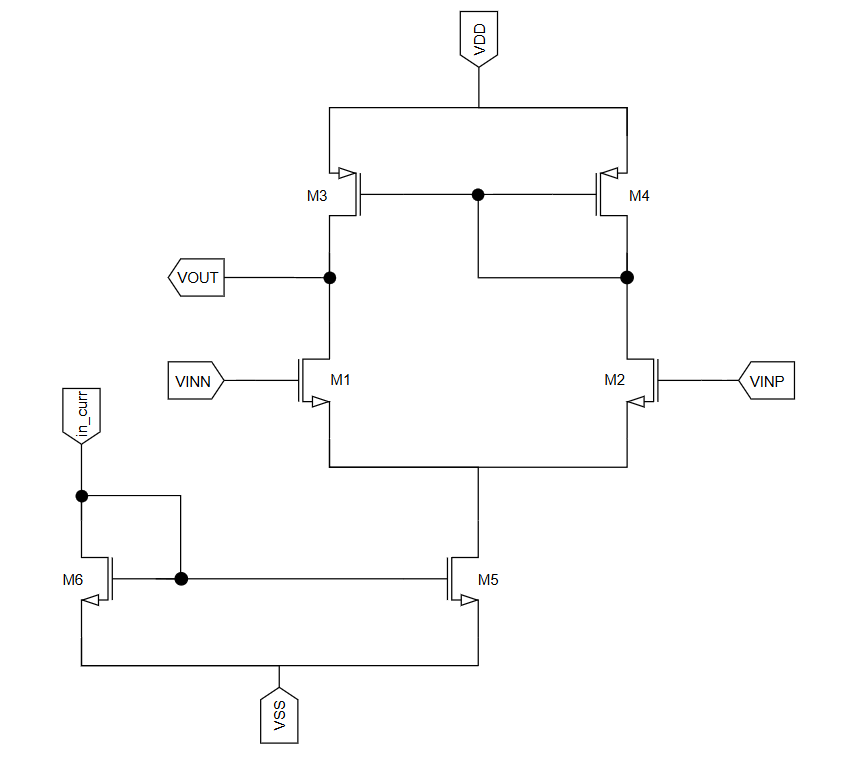


## 2. Environment Setup

### Setting Up the Live GDSII Viewer

We first source the shell environment to ensure all PDK-related environment variables are properly loaded into the Python session.

We define two helper functions for displaying GDS output inline in the notebook. display_gds reads a GDS file and renders it as an SVG, while display_component wraps it to accept a gdsfactory Component object directly.

In [ ]:
import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

hide = widgets.Output()

def display_gds(gds_file, path, scale=3):
    top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
    top_level_cell.write_svg(os.path.join(path, 'out.svg'))

    fig = sg.fromfile(os.path.join(path, 'out.svg'))
    fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
    fig.save(os.path.join(path, 'out.svg'))

    IPython.display.display(IPython.display.SVG(os.path.join(path, 'out.svg')))
    os.remove(os.path.join(path, 'out.gds'))

def display_component(component, path, scale=3):
    with hide:
        component.write_gds(os.path.join(path, 'out.gds'))
    display_gds(os.path.join(path, 'out.gds'), path, scale)

### Importing gLayout Libraries

In [ ]:
from glayout import MappedPDK, sky130, gf180
from gdsfactory import Component
from gdsfactory.components import text_freetype, rectangle

from glayout import nmos, pmos
from glayout import via_stack
from glayout import rename_ports_by_orientation
from glayout import tapring

from glayout.util.comp_utils import evaluate_bbox, prec_center, prec_ref_center, align_comp_to_port
from glayout.util.port_utils import add_ports_perimeter, print_ports
from glayout.util.snap_to_grid import component_snap_to_grid
from glayout.spice.netlist import Netlist

from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route
from glayout.routing.L_route import L_route

## 3. Design Parameters & Configuration

### Transistor Kwargs

nmos_kwargs and pmos_kwargs are Python dictionaries that store a shared set of physical layout parameters for the transistors. Instead of repeating the same parameters in every nmos() or pmos() call, we define them once here and pass them using the kwargs syntax.

In [ ]:
nmos_kwargs = {
    "with_tie": False,                        # add tie layer for bulk connection
    "with_dnwell": False,                     # deep n-well for substrate isolation
    "sd_route_topmet": "met2",                # top metal layer for source/drain routing
    "gate_route_topmet": "met2",              # top metal layer for gate routing
    "sd_route_left": True,                    # route source/drain to the left
    "rmult": None,                            # metal width multiplier for source/drain (None = default)
    "gate_rmult": 1,                          # metal width multiplier for gate
    "interfinger_rmult": 1,                   # metal width multiplier between fingers
    "substrate_tap_layers": ("met2", "met1"), # layers for substrate tap
    "dummy_routes": True                      # add routing to dummy fets
}

pmos_kwargs = {
    "with_tie": False,
    "dnwell": False,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2", "met1"),
    "dummy_routes": True
}

### Top-Level Configuration Dictionary

All sizing and layout rule parameters are centralized in a single configuration dictionary fivet_ota_config. This makes it easy to adjust the design without modifying function internals. The dictionary is organized into nested sub-dictionaries, one per sub-circuit.

In [ ]:
fivet_ota_config = {
    "pdk": gf180,

    # Differential Input Pair (M1, M2) — NMOS
    "input_pair": {
        "width": 5.75,
        "length": 0.4,
        "fingers": 2,
        "multipliers": 1,
        "device_type": "nmos",
    },

    # Current Mirror Load (M3, M4) — PMOS
    "current_mirror": {
        "width": 8.45,
        "length": 0.4,
        "fingers": 5,
        "multipliers": 1,
        "device_type": "pmos",
    },

    # Tail Current Source (M5) — NMOS
    "tail_source": {
        "width": 9.55,
        "length": 0.7,
        "fingers": 5,
        "multipliers": 1,
        "device_type": "nmos",
    },

    # Layout and routing rules
    "layout_rules": {
        "spacing": 2.0,
        "routing_metal": "met2",
        "dummy_devices": True,
        "tie_layers": ("met2", "met1"),   # tapring metal layers
        "sd_rmult": 1,                    # source/drain metal width multiplier
    }
}

### Creating the Top-Level Component

In [ ]:
top_level = Component(name="fivet_ota")
pdk = fivet_ota_config["pdk"]

## 4. Sub-circuit Layout: Current Mirror Load (M3 & M4)

The current mirror load consists of two PMOS transistors: a reference device (M4) with a diode connection, and a mirror device (M3) whose drain provides the output current.

### nwell Padding

- Each PMOS transistor has its own nwell region. A gap between them violates PDK spacing rules.
- `cm_comp.add_padding(layers=(pdk.get_glayer("nwell"),), default=1)` merges both regions into one continuous nwell.

### Tapring Layer Selection

- PMOS bulk is the nwell, so the tapring uses `sdlayer="n+s/d"` to tie it to VDD.
- NMOS sub-cells use `sdlayer="p+s/d"` instead, as their bulk is the p-substrate.



In [ ]:
def current_mirror(pdk, config):
    cm_comp = Component(name="current_mirror")
    
    # Extract parameters from config
    width       = config["current_mirror"]["width"]
    length      = config["current_mirror"]["length"]
    fingers     = config["current_mirror"]["fingers"]
    multipliers = config["current_mirror"]["multipliers"]
    tie_layers  = config["layout_rules"]["tie_layers"]
    sd_rmult    = config["layout_rules"]["sd_rmult"]
    
    # Instantiate two PMOS transistors
    pfet_m4 = pmos(pdk, width=width, length=length, fingers=fingers,
                    multipliers=multipliers,
                    with_substrate_tap=False,
                    with_dummy=(False, True),
                    tie_layers=tie_layers,
                    sd_rmult=sd_rmult,
                    **pmos_kwargs)
    
    pfet_m3 = pmos(pdk, width=width, length=length, fingers=fingers,
                    multipliers=multipliers,
                    with_substrate_tap=False,
                    with_dummy=(True, False),
                    tie_layers=tie_layers,
                    sd_rmult=sd_rmult,
                    **pmos_kwargs)
    
    cm4_ref = cm_comp << pfet_m4
    cm3_ref = cm_comp << pfet_m3
    cm4_ref.name = "pfet_m4"
    cm3_ref.name = "pfet_m3"
    
    # Placement: move pfet_m4 to the right of pfet_m3
    cm4_ref.movex(evaluate_bbox(pfet_m3)[0] + pdk.util_max_metal_seperation())
    
    # Tapring enclosure
    tap_ring = tapring(pdk,
        enclosed_rectangle=evaluate_bbox(
            cm_comp.flatten(),
            padding=pdk.get_grule("nwell", "active_diff")["min_enclosure"]),
        sdlayer="n+s/d",
        horizontal_glayer=tie_layers[0],
        vertical_glayer=tie_layers[1])
    shift_amount = -prec_center(cm_comp.flatten())[0]
    tring_ref = cm_comp << tap_ring
    tring_ref.movex(destination=shift_amount)
    
    # nwell padding to merge the two separate nwell regions
    cm_comp.add_padding(layers=(pdk.get_glayer("nwell"),), default=1)
    
    # Internal routing
    cm_comp << straight_route(pdk, cm4_ref.ports["multiplier_0_source_E"],
                                   cm3_ref.ports["multiplier_0_source_E"])
    cm_comp << straight_route(pdk, cm4_ref.ports["multiplier_0_gate_E"],
                                   cm3_ref.ports["multiplier_0_gate_E"])

    # Route dummy to tapring (We have to route it manually since we generated the tapring manually)
    cm_comp << straight_route(pdk, cm3_ref.ports["multiplier_0_dummy_L_gsdcon_top_met_E"],
                                   tring_ref.ports["W_top_met_W"])
    cm_comp << straight_route(pdk, cm4_ref.ports["multiplier_0_dummy_R_gsdcon_top_met_W"],
                                   tring_ref.ports["E_top_met_E"])
    
    # Expose ports
    cm_comp.add_ports(cm4_ref.get_ports_list(), prefix="M4_")
    cm_comp.add_ports(cm3_ref.get_ports_list(), prefix="M3_")
    cm_comp.add_ports(tring_ref.get_ports_list(), prefix="TRING_")
    
    return cm_comp

In [ ]:
cm = current_mirror(pdk, fivet_ota_config)
cm_ref = top_level << cm
cm_ref.name = "current_mirror"

display_component(top_level, scale=1, path="../../")
# top_level.show()

## 5. Sub-circuit Layout: Differential Input Pair (M1 & M2)

The differential pair consists of two matched NMOS transistors. M1 is the negative input and M2 is the positive input. Their sources are shorted together and connected to the tail current source.


In [ ]:
def diff_pair(pdk, config):
    dp_comp = Component(name="diff_pair")

    # Extract parameters from config
    width       = config["input_pair"]["width"]
    length      = config["input_pair"]["length"]
    fingers     = config["input_pair"]["fingers"]
    multipliers = config["input_pair"]["multipliers"]
    tie_layers  = config["layout_rules"]["tie_layers"]
    sd_rmult    = config["layout_rules"]["sd_rmult"]

    # Instantiate two NMOS transistors
    m1 = nmos(pdk, width=width, length=length, fingers=fingers,
              multipliers=multipliers,
              with_substrate_tap=False,
              with_dummy=(True, False),
              tie_layers=tie_layers,
              sd_rmult=sd_rmult,
              **nmos_kwargs)
    m2 = nmos(pdk, width=width, length=length, fingers=fingers,
              multipliers=multipliers,
              with_substrate_tap=False,
              with_dummy=(False, True),
              tie_layers=tie_layers,
              sd_rmult=sd_rmult,
              **nmos_kwargs)

    m1_ref = dp_comp << m1
    m2_ref = dp_comp << m2
    m1_ref.name = "M1"  # negative input
    m2_ref.name = "M2"  # positive input

    # Placement
    ref_dimensions = evaluate_bbox(m1)
    m2_ref.movex(m1_ref.xmax)
    m2_ref.movex(ref_dimensions[0] / 2)
    m2_ref.movex(pdk.util_max_metal_seperation())

    # Connect sources together
    dp_comp << straight_route(pdk,
        m1_ref.ports["multiplier_0_source_E"],
        m2_ref.ports["multiplier_0_source_W"])

    # Tapring enclosure
    tap_ring = tapring(pdk, enclosed_rectangle=evaluate_bbox(
        dp_comp.flatten(),
        padding=pdk.get_grule("nwell", "active_diff")["min_enclosure"]))
    shift_amount = -prec_center(dp_comp.flatten())[0]
    tring_ref = dp_comp << tap_ring
    tring_ref.movex(destination=shift_amount)

    # Route dummy to tapring (We have to route it manually since we generated the tapring manually)
    dp_comp << straight_route(pdk, m1_ref.ports["multiplier_0_dummy_L_gsdcon_top_met_E"],
                                   tring_ref.ports["W_top_met_W"])
    dp_comp << straight_route(pdk, m2_ref.ports["multiplier_0_dummy_R_gsdcon_top_met_W"],
                                   tring_ref.ports["E_top_met_E"])

    # Expose ports
    dp_comp.add_ports(m1_ref.get_ports_list(), prefix="M1_")
    dp_comp.add_ports(m2_ref.get_ports_list(), prefix="M2_")
    dp_comp.add_ports(tring_ref.get_ports_list(), prefix="TRING_")

    return dp_comp

In [ ]:
dp = diff_pair(pdk, fivet_ota_config)
dp_ref = top_level << dp
dp_ref.name = "diff_pair"

display_component(top_level, scale=1, path="../../")

## 6. Sub-circuit Layout: Tail Current Source (M5)

The tail current source consists of two NMOS transistors: a reference device with a diode connection (M6), and a mirror device that sinks the tail current for the differential pair (M5). The layout follows the same structure as the current mirror load — both devices share their source and gate connections, with a c_route shorting the gate to drain on the reference side.

In [ ]:
def tail_current(pdk, config):
    tail_comp = Component(name="tail_current")
    
    # Extract parameters from config
    width       = config["tail_source"]["width"]
    length      = config["tail_source"]["length"]
    fingers     = config["tail_source"]["fingers"]
    multipliers = config["tail_source"]["multipliers"]
    tie_layers  = config["layout_rules"]["tie_layers"]
    sd_rmult    = config["layout_rules"]["sd_rmult"]
    
    # Instantiate two NMOS transistors
    nfet_m6 = nmos(pdk, width=width, length=length, fingers=fingers,
                    multipliers=multipliers,
                    with_substrate_tap=False,
                    with_dummy=(False, True),
                    tie_layers=tie_layers,
                    sd_rmult=sd_rmult,
                    **nmos_kwargs)
    
    nfet_m5 = nmos(pdk, width=width, length=length, fingers=fingers,
                    multipliers=multipliers,
                    with_substrate_tap=False,
                    with_dummy=(True, False),
                    tie_layers=tie_layers,
                    sd_rmult=sd_rmult,
                    **nmos_kwargs)
    
    m6 = tail_comp << nfet_m6
    m5 = tail_comp << nfet_m5
    m6.name = "nfet_m6"
    m5.name = "nfet_m5"
    
    # Placement
    m6.movex(evaluate_bbox(nfet_m5)[0] + pdk.util_max_metal_seperation())
    
    # Tapring enclosure
    tap_ring = tapring(pdk, enclosed_rectangle=evaluate_bbox(
        tail_comp.flatten(),
        padding=pdk.get_grule("nwell", "active_diff")["min_enclosure"]))
    shift_amount = -prec_center(tail_comp.flatten())[0]
    tring_ref = tail_comp << tap_ring
    tring_ref.movex(destination=shift_amount)
    
    # Internal routing
    tail_comp << straight_route(pdk, m6.ports["multiplier_0_source_E"],
                                     m5.ports["multiplier_0_source_E"])
    tail_comp << straight_route(pdk, m6.ports["multiplier_0_gate_E"],
                                     m5.ports["multiplier_0_gate_E"])
    tail_comp << c_route(pdk, m6.ports["multiplier_0_gate_E"],
                              m6.ports["multiplier_0_drain_E"])

    # Route dummy to tapring (We have to route it manually since we generated the tapring manually)
    tail_comp << straight_route(pdk, m5.ports["multiplier_0_dummy_L_gsdcon_top_met_E"],
                                   tring_ref.ports["W_top_met_W"])
    tail_comp << straight_route(pdk, m6.ports["multiplier_0_dummy_R_gsdcon_top_met_W"],
                                   tring_ref.ports["E_top_met_E"])
    
    # Expose ports
    tail_comp.add_ports(m6.get_ports_list(), prefix="M6_")
    tail_comp.add_ports(m5.get_ports_list(), prefix="M5_")
    tail_comp.add_ports(tring_ref.get_ports_list(), prefix="TRING_")
    return tail_comp

In [ ]:
tail = tail_current(pdk, fivet_ota_config)
tail_ref = top_level << tail
tail_ref.name = "tail_current"

display_component(top_level, scale=1, path="../../")

## 7. Placement

### Vertical Stacking and Center Alignment

The three sub-circuits are stacked vertically: current mirror on top, differential pair in the middle, and tail current source at the bottom. Each block is moved downward relative to the one above it using `ymin` of the upper block as the reference. After vertical placement, all three blocks are horizontally aligned to the center of the current mirror using their absolute center coordinates.

In [ ]:
dp_dimensions   = evaluate_bbox(dp)
tail_dimensions = evaluate_bbox(tail)

# Place diff_pair below current_mirror
dp_ref.movey(cm_ref.ymin - dp_dimensions[1] / 2 - pdk.util_max_metal_seperation())

display_component(top_level, scale=1, path="../../")

# Place tail_current below diff_pair
tail_ref.movey(dp_ref.ymin - tail_dimensions[1] / 2 - pdk.util_max_metal_seperation())

display_component(top_level, scale=1, path="../../")

# Align all blocks to the horizontal center of the current mirror
dp_ref.movex(cm_ref.center[0] - dp_ref.center[0])
tail_ref.movex(cm_ref.center[0] - tail_ref.center[0])

display_component(top_level, scale=1, path="../../")

## 8. Routing

### Via Stack Placement

Before routing, all required via stacks are placed first. The center coordinate of a port can be accessed using cell_name.ports["port_name"].center, which is used alongside other placement techniques to position each via accurately.

In [ ]:
viam2m3 = via_stack(pdk, "met2", "met3", centered=True)
viam1m2 = via_stack(pdk, "met1", "met2", centered=True)

# Via for left drain of current mirror (MIR side)
drain_m3_via = top_level << viam2m3
drain_m3_via.move(cm_ref.ports["M3_multiplier_0_drain_W"].center).movex(-5)

# Via for right drain of current mirror (REF side)
drain_m4_via = top_level << viam2m3
drain_m4_via.move(cm_ref.ports["M4_multiplier_0_drain_E"].center).movex(5)

# Via for left drain of diff pair (M1)
drain_m1_via = top_level << viam2m3
drain_m1_via.move(dp_ref.ports["M1_multiplier_0_drain_W"].center).movex(-5)
drain_m1_via.movex(drain_m4_via.x - drain_m1_via.x)

# Via for right drain of diff pair (M2)
drain_m2_via = top_level << viam2m3
drain_m2_via.move(dp_ref.ports["M2_multiplier_0_drain_E"].center).movex(5)
drain_m2_via.movex(drain_m3_via.x - drain_m2_via.x)

# Via for common source of diff pair
source_m1_via = top_level << viam2m3
source_m1_via.move(dp_ref.ports["M1_multiplier_0_source_W"].center)

# Via for drain of tail current sink
drain_m5_via = top_level << viam2m3
drain_m5_via.move(tail_ref.ports["M5_multiplier_0_drain_W"].center)
source_m1_via.movex(drain_m5_via.x - source_m1_via.x)

display_component(top_level, scale=1, path="../../")

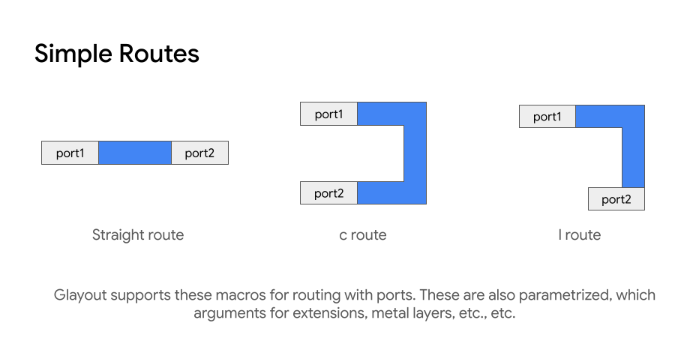

Now that the vias are placed, time to make metal routing.
There are three basic types of routing available:

- `straight_route` - the ports must be straight to each other, i.e, opposite direction and same x or y coordinate.
- `L_route` - has a 90&deg; bend, ports must be perpendicular to each other.
- `c_route` -  has two 90&deg; bends(c shaped), ports must have same direction.

Each routing function has multiple parameters. See [here](https://github.com/idea-fasoc/OpenFASOC/tree/main/openfasoc/generators/glayout/glayout/flow/routing)



### Port Routing Convention

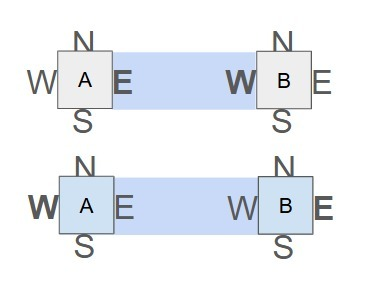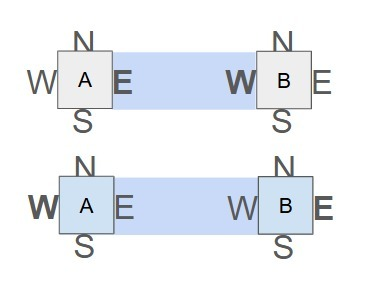
 
- The top diagram shows a connection from A's East port to B's West port — this routes metal through the narrow gap between the two components, which risks DRC violations due to spacing constraints.
- The bottom diagram shows the preferred approach: connecting A's West port to B's East port instead, routing the metal around the outside and keeping the space between components clear.

### Vertical Routes: Connecting Drain Nodes Through Vias

In [ ]:
# CM MIR drain → M1 diff pair drain
top_level << straight_route(pdk,
    drain_m3_via.ports["top_met_N"],
    drain_m1_via.ports["top_met_S"])

# CM REF drain → M2 diff pair drain
top_level << straight_route(pdk,
    drain_m4_via.ports["top_met_N"],
    drain_m2_via.ports["top_met_S"])

# Diff pair common source → tail drain
top_level << straight_route(pdk,
    source_m1_via.ports["top_met_N"],
    drain_m5_via.ports["top_met_S"])

display_component(top_level, scale=1, path="../../")

### Horizontal Routes: Connecting Sub-circuit Ports to Vias

In [ ]:
# Current mirror MIR drain → left via
top_level << straight_route(pdk,
    cm_ref.ports["M3_multiplier_0_drain_E"],
    drain_m3_via.ports["bottom_met_W"])

# Current mirror REF drain → right via
top_level << straight_route(pdk,
    cm_ref.ports["M4_multiplier_0_drain_W"],
    drain_m4_via.ports["bottom_met_E"])

# M1 drain → left via
top_level << straight_route(pdk,
    dp_ref.ports["M1_multiplier_0_drain_E"],
    drain_m1_via.ports["bottom_met_W"])

# M2 drain → right via
top_level << straight_route(pdk,
    dp_ref.ports["M2_multiplier_0_drain_W"],
    drain_m2_via.ports["bottom_met_E"])

# M2 source → tail drain via
top_level << straight_route(pdk,
    dp_ref.ports["M2_multiplier_0_source_E"],
    drain_m5_via.ports["bottom_met_W"])

# VDD: CM source to N+ tapring
top_level << straight_route(pdk,
    cm_ref.ports["M3_multiplier_0_source_E"],
    cm_ref.ports["TRING_W_top_met_W"])

# VSS: Tail source to P+ tapring
top_level << straight_route(pdk,
    tail_ref.ports["M6_multiplier_0_source_E"],
    tail_ref.ports["TRING_W_top_met_W"])

# Connect tail tapring to diff pair tapring
top_level << straight_route(pdk,
    dp_ref.ports["TRING_S_top_met_N"],
    tail_ref.ports["TRING_N_top_met_S"])

display_component(top_level, scale=1, path="../../")

## 9. Add Outermost Tapring

We add a final tapring that encloses the entire layout. This connects to the inner taprings of the sub-cells to form a continuous VSS guard ring.


In [ ]:
flat = top_level.flatten()
cx, cy = prec_center(flat)
actual_cx = -cx
actual_cy = -cy

tap_ring = tapring(pdk, enclosed_rectangle=evaluate_bbox(
    flat,
    padding=pdk.get_grule("nwell", "active_diff")["min_enclosure"]))

tring_ref = top_level << tap_ring
tring_ref.movex(destination=actual_cx)
tring_ref.movey(destination=actual_cy)

# Connect outer P+ tapring to inner P+ tapring
top_level << straight_route(pdk,
    tail_ref.ports["TRING_W_top_met_E"],
    tring_ref.ports["W_top_met_W"])

# Snap to grid and rename ports by orientation
component = component_snap_to_grid(rename_ports_by_orientation(top_level))
display_component(component, scale=2, path="../../")

## 10. I/O Port Vias & Pin Labeling

### Adding Via Stacks for I/O Signals

We place via stacks at each I/O port location, stepping up from metal 2 to metal 3. These vias serve as accessible landing pads for the top-level signals: VINP, VINN, VOUT, IN_CUR, VDD, and VSS.

In [ ]:
viam2m3 = via_stack(pdk, "met2", "met3", centered=True)

vinp_via   = top_level << viam2m3
vinn_via   = top_level << viam2m3
in_cur_via = top_level << viam2m3
vout_via   = top_level << viam2m3
vdd_via    = top_level << viam2m3
vss_via    = top_level << viam2m3

# Position each via at the corresponding port
vinn_via.move(dp_ref.ports["M1_multiplier_0_gate_W"].center)
vinp_via.move(dp_ref.ports["M2_multiplier_0_gate_E"].center)
in_cur_via.move(tail_ref.ports["M6_multiplier_0_drain_W"].center)
vout_via.move(dp_ref.ports["M1_multiplier_0_drain_W"].center)
vdd_via.move(cm_ref.ports["M3_multiplier_0_source_W"].center)
vss_via.move(tail_ref.ports["M5_multiplier_0_source_W"].center)

display_component(top_level, scale=2, path="../../")

### Exposing Ports to the Top Level

In [ ]:
# Add ports from sub-circuits
top_level.add_ports(cm_ref.get_ports_list(),   prefix="CM_")
top_level.add_ports(dp_ref.get_ports_list(),   prefix="DP_")
top_level.add_ports(tail_ref.get_ports_list(), prefix="TAIL_")

# Add ports from I/O vias
top_level.add_ports(vinp_via.get_ports_list(),   prefix="VINP_")
top_level.add_ports(vinn_via.get_ports_list(),   prefix="VINN_")
top_level.add_ports(in_cur_via.get_ports_list(), prefix="INCUR_")
top_level.add_ports(vout_via.get_ports_list(),   prefix="VOUT_")
top_level.add_ports(vdd_via.get_ports_list(),    prefix="VDD_")
top_level.add_ports(vss_via.get_ports_list(),    prefix="VSS_")

component = component_snap_to_grid(rename_ports_by_orientation(top_level))
display_component(component, scale=2, path="../../")

### Adding Pin Labels

We need to add I/O pins, power supply pins, and bias pins to the layout. These labels are required for LVS (Layout vs. Schematic) verification and parasitic extraction (PEX). 

In [ ]:
psize = (0.5, 0.5)
move_info = list()

# VSS
vsslabel = rectangle(layer=pdk.get_glayer("met2_pin"), size=psize, centered=True).copy()
vsslabel.add_label(text="VSS", layer=pdk.get_glayer("met2_label"))
move_info.append((vsslabel, component.ports["VSS_bottom_met_E"], None))

# VDD
vddlabel = rectangle(layer=pdk.get_glayer("met2_pin"), size=psize, centered=True).copy()
vddlabel.add_label(text="VDD", layer=pdk.get_glayer("met2_label"))
move_info.append((vddlabel, component.ports["VDD_bottom_met_E"], None))

# VINP
vinplabel = rectangle(layer=pdk.get_glayer("met2_pin"), size=psize, centered=True).copy()
vinplabel.add_label(text="VINP", layer=pdk.get_glayer("met2_label"))
move_info.append((vinplabel, component.ports["VINP_bottom_met_E"], None))

# VINN
vinnlabel = rectangle(layer=pdk.get_glayer("met2_pin"), size=psize, centered=True).copy()
vinnlabel.add_label(text="VINN", layer=pdk.get_glayer("met2_label"))
move_info.append((vinnlabel, component.ports["VINN_bottom_met_W"], None))

# VOUT
voutlabel = rectangle(layer=pdk.get_glayer("met2_pin"), size=psize, centered=True).copy()
voutlabel.add_label(text="VOUT", layer=pdk.get_glayer("met2_label"))
move_info.append((voutlabel, component.ports["VOUT_bottom_met_W"], None))

# IN_CUR
in_curlabel = rectangle(layer=pdk.get_glayer("met2_pin"), size=psize, centered=True).copy()
in_curlabel.add_label(text="IN_CUR", layer=pdk.get_glayer("met2_label"))
move_info.append((in_curlabel, component.ports["INCUR_bottom_met_W"], None))

for comp, prt, alignment in move_info:
    alignment = ('c', 'b') if alignment is None else alignment
    compref = align_comp_to_port(comp, prt, alignment=alignment)
    top_level.add(compref)

component = top_level.flatten()
display_component(top_level, scale=2, path="../../")
# top_level.show()

## 11. DRC Verification

The final step is to run a Design Rule Check (DRC) using Magic. The `drc_magic` function runs Magic's DRC engine on the component and returns a report of any violations.

A clean DRC result confirms that all spacing, enclosure, and width rules defined by the GF180 PDK are satisfied.

In [ ]:
component.name = "5T_OTA"
drc_result = gf180.drc_magic(component, component.name)

***
# Part 7 — 5T OTA · part 2: DRC + LVS

*Source: `tutorial/glayout_tutorial_5T_OTA_part2.ipynb`* · **Needs:** EDA tools (`magic`, `netgen`). **Run Part 6 first.**

# Tutorial 2: 5-Transistor OTA LVS, PEX, and simulation using gLayout

**By gLayout Team**

**Content creators:** Adrian Sami Pratama, Dharma Anargya Jowandy

___
# Tutorial Objectives

This notebook is a tutorial on-

- **LVS (Layout Versus Schematic):**  
  You will learn how to compare your physical layout with the original schematic to ensure they are functionally identical. This process helps catch connectivity or device mismatches before fabrication.

- **Extraction and Simulation:**  
  The tutorial will guide you through extracting parasitic elements from your layout, such as capacitance and resistance, to create a more accurate circuit model. You will then simulate the extracted netlist to analyze and verify the real-world performance of your design.

## What is a 5T OTA?

A 5-Transistor Operational Transconductance Amplifier (5T OTA) is one of the most fundamental analog circuit building blocks. It converts a differential input voltage into an output current. The circuit consists of:

- **M1, M2** — Differential input pair (NMOS)
- **M3, M4** — Current mirror load (PMOS)
- **M5** — Tail current source (NMOS)

Note that the sixth transistor (M6) is used for reference current input

### Schematic Reference

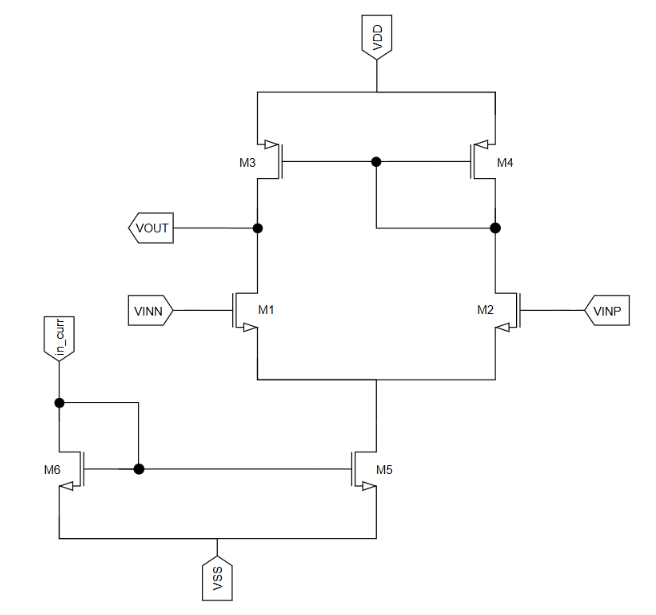

# **NetList generation and LVS**
let's go through the step by step procedure to generate LVS and DRC clean layout of a 5T OTA cell.

In [ ]:
from glayout import MappedPDK, sky130 , gf180
#from gdsfactory.cell import cell
from gdsfactory import Component
from gdsfactory.components import text_freetype, rectangle

In [ ]:
from glayout import nmos, pmos
from glayout import via_stack
from glayout import rename_ports_by_orientation
from glayout import tapring

In [ ]:
from glayout.util.comp_utils import evaluate_bbox, prec_center, prec_ref_center, align_comp_to_port
from glayout.util.port_utils import add_ports_perimeter,print_ports
from glayout.util.snap_to_grid import component_snap_to_grid
from glayout.spice.netlist import Netlist

In [ ]:
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route
from glayout.routing.L_route import L_route

## Demonstration of Basic Layout / Netlist Generation in SKY130 & GF180

The code below is an example of basic layout / netlist generation for primitive cells. We also define some of the function below that we will use for viewing our netlist-generated layout (for comparison purposes)

In [ ]:
import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Used to display the results in a grid (notebook only)
left = widgets.Output()
leftSPICE = widgets.Output()
right = widgets.Output()
rightSPICE = widgets.Output()
hide = widgets.Output()

grid = widgets.GridspecLayout(1, 4)
grid[0, 0] = left
grid[0, 1] = leftSPICE
grid[0, 2] = right
grid[0, 3] = rightSPICE
display(grid)

def display_gds(gds_file, scale = 3):
  # Generate an SVG image
  top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
  top_level_cell.write_svg('../../out.svg')

  # Scale the image for displaying
  fig = sg.fromfile('../../out.svg')
  fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
  fig.save('../../out.svg')

  # Display the image
  IPython.display.display(IPython.display.SVG('../../out.svg'))

def display_component(component, scale = 3):
  # Save to a GDS file
  with hide:
    component.write_gds("../../out.gds")

  display_gds('../../out.gds', scale)

with hide:
  # Generate the sky130 component
  component_sky130 = nmos(pdk = sky130, fingers=5)
  # Generate the gf180 component
  component_gf180 = nmos(pdk = gf180, fingers=5,with_dnwell=False)

# Display the components' GDS and SPICE netlists
with left:
  print('Skywater 130nm N-MOSFET (fingers = 5)')
  display_component(component_sky130, scale=2)
with leftSPICE:
  print('Skywater 130nm SPICE Netlist')
  print(component_sky130.info['netlist'].generate_netlist())

with right:
  print('GF 180nm N-MOSFET (fingers = 5)')
  display_component(component_gf180, scale=2)
with rightSPICE:
  print('GF 180nm SPICE Netlist')
  print(component_gf180.info['netlist'].generate_netlist())

## Python Code for 5T OTA

Below is the python code for generating 5T OTA. We will need this to generate the spice netlist. This code is similar to the part 1 notebook of this tutorial, where we generated the layout of this cell. It only has some minor syntax changes.

Import the python code to this notebook

In [ ]:
import sys
import os
from pathlib import Path
sys.path.append(os.path.abspath("../../FIVET_OTA"))
from my_fivet_ota import fivet_ota, add_fivet_ota_labels

## Spice Netlist Generation

We generate spice netlist (schematic) with the code below. First, we have to access the sub cells (the nfets and pfets) with `.info` method. After that, we define the input and output pins with `Netlist()` function. We connect the fets with `.connect_netlist()` method. Note that what we mean by spice netlist is the schematic netlist (we will use these words interchangeably)

In [ ]:
def fivet_ota_netlist(ota_in: Component) -> Component:
    m1        = ota_in.info["m1"]
    m2        = ota_in.info["m2"]
    pfet_ref  = ota_in.info["pfet_ref"]
    pfet_mir  = ota_in.info["pfet_mir"]
    nfet_tail_ref = ota_in.info["nfet_tail_ref"]
    nfet_tail_mir = ota_in.info["nfet_tail_mir"]

    # Define the top netlist, also the input and output ports
    netlist = Netlist(
        circuit_name='FIVET_OTA_1',
        nodes=['VINP', 'VINN', 'VOUT', 'VDD', 'VSS', 'IN_CUR']
    )

    # Connect the netlist
    netlist.connect_netlist(m1.info['netlist'],        [('D', 'VOUT'),  ('G', 'VINN'),   ('S', 'VTAIL'), ('B', 'VSS')])
    netlist.connect_netlist(m2.info['netlist'],        [('D', 'VMID'),  ('G', 'VINP'),   ('S', 'VTAIL'), ('B', 'VSS')])
    netlist.connect_netlist(pfet_ref.info['netlist'],  [('D', 'VMID'),  ('G', 'VMID'),   ('S', 'VDD'),   ('B', 'VDD')])
    netlist.connect_netlist(pfet_mir.info['netlist'],  [('D', 'VOUT'),  ('G', 'VMID'),   ('S', 'VDD'),   ('B', 'VDD')])
    netlist.connect_netlist(nfet_tail_ref.info['netlist'], [('D','IN_CUR'), ('G','IN_CUR'), ('S','VSS'), ('B','VSS')])
    netlist.connect_netlist(nfet_tail_mir.info['netlist'], [('D','VTAIL'), ('G','IN_CUR'), ('S','VSS'), ('B','VSS')])

    ota_in.info['netlist'] = netlist
    return ota_in

# This is an example of using the function to generate our spice netlist with specified properties
# Notice that we flattened the multi finger into one finger. Use the total width of the finger for the schematic netlist
my_ota = fivet_ota_netlist(fivet_ota((gf180),
                          input_pair = {
                            "width": 11.5,
                            "length": 0.4,
                            "fingers": 1,
                            "multipliers": 1
                          },
                          current_mirror = {
                            "width": 42.25,
                            "length": 0.4,
                            "fingers": 1,
                            "multipliers": 1
                          },
                          tail_source = {
                            "width": 47.75,
                            "length": 0.7,
                            "fingers": 1,
                            "multipliers": 1
                          })
                          )
my_ota = add_fivet_ota_labels(my_ota, gf180)
my_ota.name = "FIVET_OTA_1"
my_ota.write_gds('out_OTA.gds') # For writing the generated schematic netlist into gds layout
my_ota.show()
print(my_ota.info['netlist'].generate_netlist())

Print port list

In [ ]:
# Check port list
comp = fivet_ota(gf180)
print_ports(comp)

## Run LVS

Below is the example of how to run the LVS. There were property errors when using multi fingers for schematic netlist, so better just make it into one finger and use the total width for your schematic netlist.

In [ ]:
# Generate the schematic netlist, just as the previous step
ota = fivet_ota_netlist(add_fivet_ota_labels(fivet_ota((gf180),
                          input_pair = {
                            "width": 11.5,
                            "length": 0.4,
                            "fingers": 1,
                            "multipliers": 1
                          },
                          current_mirror = {
                            "width": 42.25,
                            "length": 0.4,
                            "fingers": 1,
                            "multipliers": 1
                          },
                          tail_source = {
                            "width": 47.75,
                            "length": 0.7,
                            "fingers": 1,
                            "multipliers": 1
                          }), gf180))
ota.name = "fivet_OTA"
ota_gds = ota.write_gds("fivet_OTA.gds") # For writing the generated schematic netlist into gds layout
display_gds(ota_gds)
ota.show()
netgen_lvs_result = gf180.lvs_netgen(ota, ota.name)

# PEX and Post Layout Simulation

> 🚧 **Under Construction**

***
# Part 8 — Flipped Voltage Follower · part 1: layout + DRC

*Source: `tutorial/glayout_tutorial_FVF_part1.ipynb`* · **Needs:** EDA tools (`klayout`, `magic`) for the DRC cells.

# Tutorial 1: **Notebook** - *FVF*

**By 
gLayout Team**

__Content creators:__ Subham Pal, Saptarshi Ghosh

__Content reviewers:__ Mehedi Saligne

___
# Tutorial Objectives

This notebook is a tutorial on-

- **Importing** and **Placement** of FETs and other macros/Pcells with relative coordinates + Placing (and connecting) Via_stack on the ports of the FETs + encircling them with padrings.
- **Routing** between the placed *Vias* with *C_*, *L_*, *Straight_* and *smart* Routes and explaining the differences between these strategies. Particularly explaning the East/West/North/South angles, (For Example, why C has to parallel but L has to be perpendicular sides) and *Placing and connecting PINs for future LVS runs

## **Target** **Block** : **Flipped Voltage Follwer Cell**

A **voltage follower**—also known as a unity-gain buffer or buffer amplifier—is an electronic circuit in which the output voltage precisely follows the input voltage, providing a voltage gain of one. Typically implemented using an operational amplifier (op-amp) with negative feedback, the voltage follower features extremely high input impedance and very low output impedance. This configuration allows it to isolate circuit stages, preventing the loading of the input source and enabling the circuit to drive low-impedance loads without signal degradation.

The voltage follower is fundamental in analog circuit design, ensuring signal fidelity and stability across a wide range of electronic applications. The **Flipped Voltage Follower (FVF)** is an advanced analog circuit topology derived from the conventional source follower, optimized for low-voltage, low-power applications. Unlike the standard voltage follower, the FVF employs a feedback structure that forces the input transistor to operate at a constant drain current, independent of variations in input voltage or load current. This is achieved using shunt negative feedback and ancillary biasing circuitry, resulting in improved linearity and significantly reduced output impedance compared to traditional designs.

**Key Features:**
- **Low Output Impedance:** The FVF provides much lower output impedance than conventional voltage followers, making it highly effective as a voltage buffer in demanding analog applications[9][11].
- **High Linearity:** Maintains a consistent voltage transfer characteristic across a wide range of operating conditions[5][9].
- **Large Output Current Capability:** Able to source or sink larger currents, supporting class-AB operation and driving heavier loads[4][7][10].
- **Low-Voltage Operation:** Well-suited for modern low-supply-voltage and low-power integrated circuit designs[4][5][7][10].
- **Applications:** Commonly found in output stages, current mirrors, voltage buffers, gain-boosting circuits, OTAs, filters, and VCOs[4][5][7][10][11].

The FVF is a versatile and robust building block in analog and mixed-signal circuit design, offering superior performance for buffering, level shifting, and driving loads in advanced CMOS technologies.

(a) Conventional Voltage follower (common Drain); (b) Flipped voltage follower (FVF).

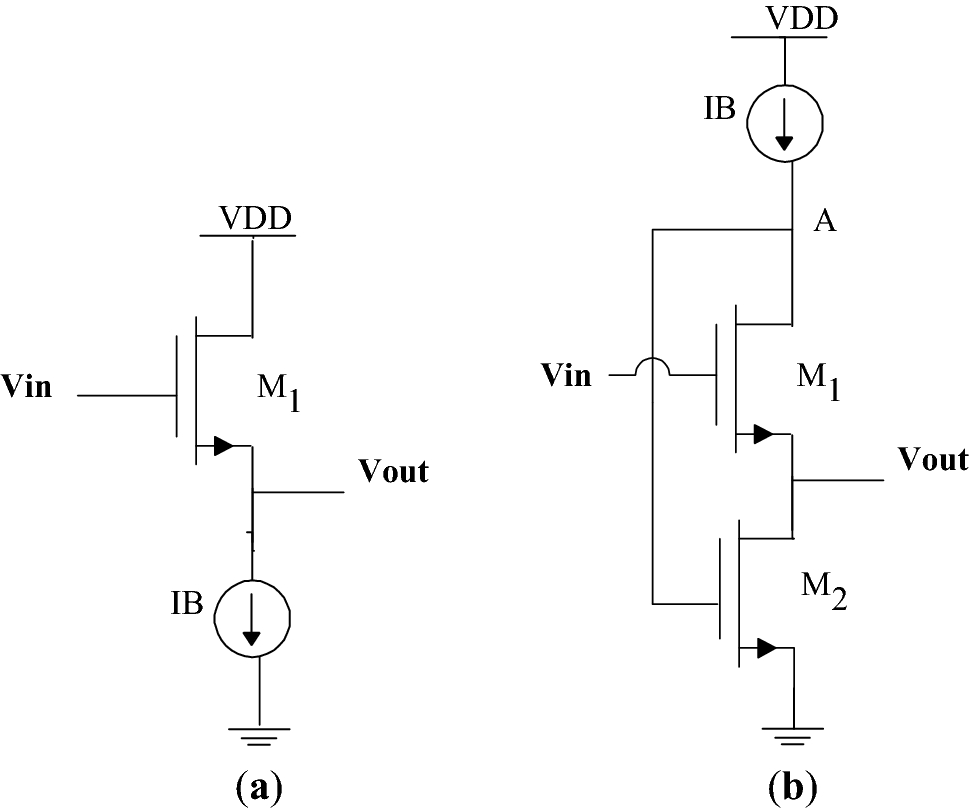

```bibtex
Domala, N., Sasikala, G. Low power flipped voltage follower current mirror with improved input output impedances. Sādhanā 46, 142 (2021). https://doi.org/10.1007/s12046-021-01665-6
```

## **Layout generation**
let's go through the step by step procedure to generate LVS and DRC clean layout of a FVF cell.


### *Creating environment for live GDSII viewer*
You can see the generated GDSII file immediately inside this notebook. You can also view it in Klayout for better understanding. Code for viewing it in Klayout is added but commented out.

In [ ]:
## Activate if necessary to install following packages

# !pip install svgutils
# !pip install ipywidgets

This cell only required for [IIC-OSIC Docker](https://github.com/iic-jku/IIC-OSIC-TOOLS). It imports all neceaasry environment varriable to current session

In [ ]:
import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Redirect all outputs here
hide = widgets.Output()

def display_gds(gds_file,path,scale = 3):
  
  # Generate an SVG image
  top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
  top_level_cell.write_svg(os.path.join(path,'out.svg'))
    
  # Scale the image for displaying
  fig = sg.fromfile(os.path.join(path,'out.svg'))
  fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
  fig.save(os.path.join(path,'out.svg'))

  # Display the image
  IPython.display.display(IPython.display.SVG(os.path.join(path,'out.svg')))
  os.remove(os.path.join(path,'out.gds'))

def display_component(component,path,scale = 3):
  # Save to a GDS file
  with hide:
    component.write_gds(os.path.join(path,'out.gds'))
  display_gds(os.path.join(path,'out.gds'),path,scale)

In [ ]:
from glayout import MappedPDK, sky130 , gf180
#from gdsfactory.cell import cell
from gdsfactory import Component
from gdsfactory.components import text_freetype, rectangle

In [ ]:
from glayout import nmos, pmos
from glayout import via_stack
from glayout import rename_ports_by_orientation
from glayout import tapring

In [ ]:
from glayout.util.comp_utils import evaluate_bbox, prec_center, prec_ref_center, align_comp_to_port
from glayout.util.port_utils import add_ports_perimeter,print_ports
from glayout.util.snap_to_grid import component_snap_to_grid
from glayout.spice.netlist import Netlist

In [ ]:
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route
from glayout.routing.L_route import L_route

FVF has two fets as shown in the schematic. We call M1 as input fet and M2 as feedback fet. Lets define arguments for the FETs

In [ ]:
nmos_kwargs = {
    "with_tie": True,
    "with_dnwell": True,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2","met1"),
    "dummy_routes": True
}

pmos_kwargs = {
    "with_tie": True,
    "dnwell": False,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2","met1"),
    "dummy_routes": True
}

There is no need to manually define the kwargs for your code. This is only done for this notebook implementation.


Now, Let's create a list for parameters which we need for our function-

* pdk: pdk to use
* device_type: either "nmos" or "pmos"
* placement: either "horizontal" or "vertical"
* width: (input fet, feedback fet)
* length: (input fet, feedback fet)
* fingers: (input fet, feedback fet)
* multipliers: (input fet, feedback fet)
* dummy_1: dummy for input fet
* dummy_2: dummy for feedback fet
* tie_layers1: tie layers for input fet
* tie_layers2: tie layers for feedback fet
* sd_rmult: sd_rmult for both fets


In [ ]:
flipped_voltage_follower_config={
        "pdk": gf180, # pdk to use
        "device_type": "nmos", # either nmos or pmos
        "placement" : "horizontal", # the two fets can be placed either vertically or horizontally
        "width": (3,3), # width of the input fet and feedback fet respectively.
        "length": (None,None), # length of the input fet and feedback fet respectively. None refers to the min length in the pdk.
        "fingers": (1,1), # no. of fingers of the input fet and feedback fet respectively.
        "multipliers": (1,1), #no. of multipliers of the input fet and feedback fet respectively.
        "dummy_1": (True,True), # dummy pattern for input fet (left,right)
        "dummy_2": (True,True), # dummy pattern for the feedback fet (left,right)
        "tie_layers1": ("met2","met1"), #tapring metal layers for input fet
        "tie_layers2": ("met2","met1"), #tapring metal layers for feedback fet
        "sd_rmult":1, # thickness of the sd metal layer.
}

### First: We create a top level component and add a name

In [ ]:
top_level = Component(name="flipped_voltage_follower")

### Two fets

For our fvf block, we do not want deep nwell. However nmos and pmos primitives have different parameter name for deepnwell.
For pmos it is set to false by default.We need to set it to false if the device type is given as nmos.
We could've just set it properly in our nmos_kwargs,
but since you will probably not code the layout for a notebook, we show a general way of solving this issue.


In [ ]:
device_type = flipped_voltage_follower_config["device_type"]
device_map = {
        "nmos": nmos,
        "pmos":pmos,
        }

device = device_map.get(device_type)
if device_type == "nmos":
      nmos_kwargs["with_dnwell"] = False

In [ ]:
pdk=flipped_voltage_follower_config["pdk"]
pdk.activate()

In [ ]:
width=flipped_voltage_follower_config["width"]
length=flipped_voltage_follower_config["length"]
fingers=flipped_voltage_follower_config["fingers"]
multipliers=flipped_voltage_follower_config["multipliers"]

dummy_1=flipped_voltage_follower_config["dummy_1"]
dummy_2=flipped_voltage_follower_config["dummy_2"]
tie_layers1=flipped_voltage_follower_config["tie_layers1"]
tie_layers2=flipped_voltage_follower_config["tie_layers2"]
sd_rmult=flipped_voltage_follower_config["sd_rmult"]

In [ ]:
#fet_1 is the input fet
fet_1 = device(pdk, width=width[0], fingers=fingers[0], multipliers=multipliers[0], with_dummy=dummy_1, with_substrate_tap=False, length=length[0], tie_layers=tie_layers1, sd_rmult=sd_rmult, **(nmos_kwargs if device_type == "nmos" else pmos_kwargs))
#fet_2 is the feedback fet
fet_2 = device(pdk, width=width[1], fingers=fingers[1], multipliers=multipliers[1], with_dummy=dummy_2, with_substrate_tap=False, length=length[1], tie_layers=tie_layers2, sd_rmult=sd_rmult, **(nmos_kwargs if device_type == "nmos" else pmos_kwargs))
well = "pwell" if device == nmos else "nwell"

Adding the references of the FETs to the top level component

In [ ]:
fet_1_ref = top_level << fet_1
fet_2_ref = top_level << fet_2

fet_1_ref.name = "fet1_ref"
fet_2_ref.name = "fet2_ref"

#let's take a look at our current state of layout
## To see in Klayout via Klive
# top_level.show()
display_component(top_level, scale = 5,path="../../")
## If you want to save the gds file at this stage
#primary_gds = top_level.write_gds("before_placement.gds")

### Placement

When a cell is referenced to the top level, the center of the cell is aligned to the (0,0) co-ordinate.
As of now, both of our fets are centered at (0,0). We need place them properly depending on the placement parameter.

In [ ]:
placement=flipped_voltage_follower_config["placement"]
ref_dimensions = evaluate_bbox(fet_2)


evaluate_bbox returns maximum width and maximum height of the block as a tuple(width,height).

So here we have `ref_dimensions=(x-dimension of fet_2, y-dimension of fet_2)`

For horizontal placement , we need to move the fet_2 in rightward direction.
We use the movex function, which moves the center of the block in x-directon upto a certain distance. We need to find out this distance.
Remember that both fet_1 and fet_2 are centered at (0,0) co-ordinate right now.
At first we move the center of fet_2 to rightmost point of fet_1 using the xmax function, i.e, (fet_1_ref.xmax,0).
Now we will find that left half of fet_2 is overlapping with fet_1, so we need to move it at rightward direction again.We move it by ref_dimensionsp[0]/2 distance.
Now we see that the rightmost point of fet_1 and leftmost point of fet_2 have no seperation between them.
This will cause a drc error. So we move it again by max seperation needed between two metal layers for drc free layout.
We move it by 1um again for leaving some routing space for future use.

Vertical placement can be done in similar way by using movey function.

In [ ]:
if placement == "horizontal":
    fet_2_ref.movex(fet_1_ref.xmax)
    display_component(top_level, scale = 2,path="../../")
    fet_2_ref.movex(ref_dimensions[0]/2)
    display_component(top_level, scale = 2,path="../../")
    fet_2_ref.movex(pdk.util_max_metal_seperation()+1)
elif placement == "vertical":
    display_component(top_level, scale = 2,path="../../")
    fet_2_ref.movey(fet_1_ref.ymin - ref_dimensions[1]/2 - pdk.util_max_metal_seperation()-1)
else:
    raise ValueError("Placement must be either 'horizontal' or 'vertical'.")
# let's see how our block looks after placement
display_component(top_level, scale = 2,path="../../")
## To see in Klayout via Klive
#top_level.show()

 ### Routing

Now that our fets are properly placed, we need to make proper connections between ports (i.e. Gates, Sources and Drains of the FETs).
Each port has four directions- East,North,West,South which means 0,90,180,270 degrees respectively.
You can connect directly to a fet port. For better felxibility in routing, we choose add some intermediate vias here.

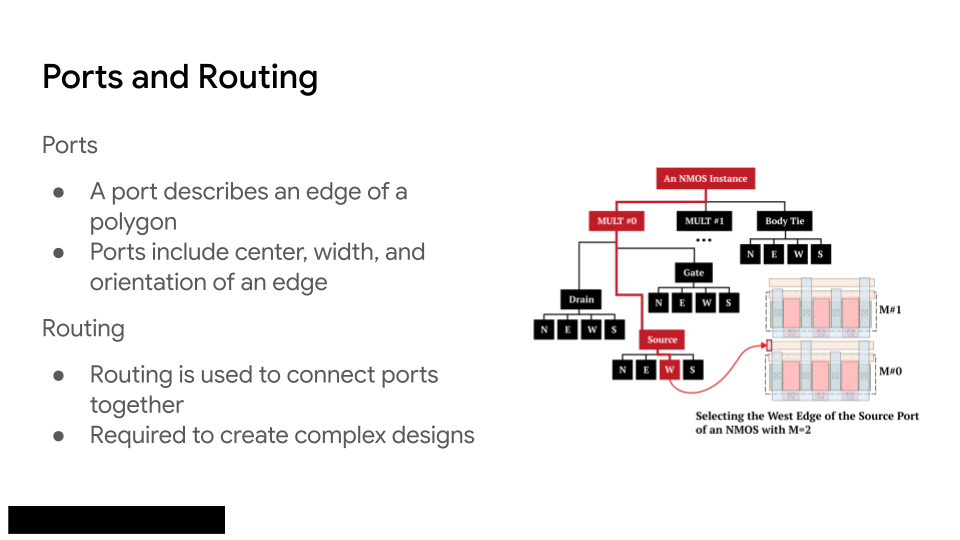


In [ ]:
viam2m3 = via_stack(pdk, "met2", "met3", centered=True) #met2 is the bottom layer. met3 is the top layer.

#we need four such vias
drain_1_via = top_level << viam2m3
source_1_via = top_level << viam2m3
gate_1_via = top_level << viam2m3

drain_2_via = top_level << viam2m3
gate_2_via = top_level << viam2m3

The move function moves the center of a specific cell to a specific co-ordinate.
The co-ordinates of the center of a port can be accesed by using cell_name.ports["port_name"].center
Using these two and other techniques previously discussed, we properly place these 4 vias.

In [ ]:
drain_1_via.move(fet_1_ref.ports["multiplier_0_drain_W"].center).movex(-0.5*evaluate_bbox(fet_1)[1])
source_1_via.move(fet_1_ref.ports["multiplier_0_source_E"].center).movex(1.5)
gate_1_via.move(fet_1_ref.ports["multiplier_0_gate_E"].center)

drain_2_via.move(fet_2_ref.ports["multiplier_0_drain_W"].center).movex(-1.5)
gate_2_via.move(fet_2_ref.ports["multiplier_0_gate_E"].center).movex(1)

# let's see where those vias are now
## To see in Klayout via Klive
#top_level.show()
display_component(top_level, scale = 3,path="../../")

Now that the vias are placed, time to make metal routing.
There are three basic types of routing available:

- `straight_route` - the ports must be straight to each other, i.e, opposite direction and same x or y coordinate.
- `L_route` - has a 90&deg; bend, ports must be perpendicular to each other.
- `c_route` -  has two 90&deg; bends(c shaped), ports must have same direction.

Each routing function has multiple parameters. See [here](https://github.com/idea-fasoc/OpenFASOC/tree/main/openfasoc/generators/glayout/glayout/flow/routing)

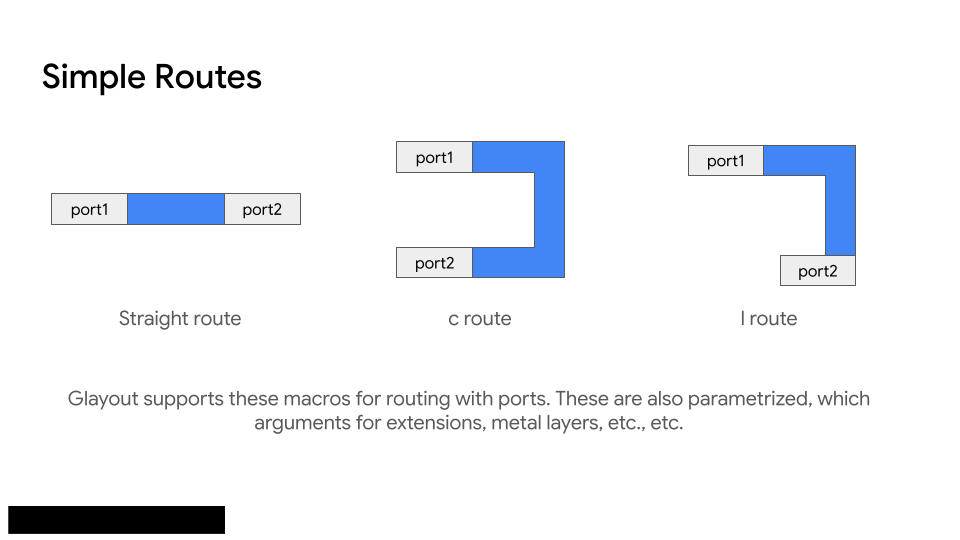

Bonus: You can see all avaliable ports by `top_level.pprint_ports()`

From the schematic, we see that we need to connect these two nodes-

1. Source of M1 and Drain of M2, we insert two intermediate vias near each of them and connect them.
2. Gate of M2 and Drain of M1, we insert two intermediate vias near each of them and connect them.

In [ ]:
top_level << straight_route(pdk, fet_1_ref.ports["multiplier_0_source_E"], source_1_via.ports["bottom_met_W"])
top_level << straight_route(pdk, fet_1_ref.ports["multiplier_0_gate_S"], gate_1_via.ports["bottom_met_N"])
top_level << straight_route(pdk, fet_2_ref.ports["multiplier_0_drain_W"], drain_2_via.ports["bottom_met_E"])
top_level << c_route(pdk, source_1_via.ports["top_met_N"], drain_2_via.ports["top_met_N"], extension=1.2*max(width[0],width[1]), width1=0.32, width2=0.32, cwidth=0.32, e1glayer="met3", e2glayer="met3", cglayer="met2")
top_level << straight_route(pdk, fet_1_ref.ports["multiplier_0_drain_W"], drain_1_via.ports["bottom_met_E"])
top_level << c_route(pdk, drain_1_via.ports["top_met_S"], gate_2_via.ports["top_met_S"], extension=1.2*max(width[0],width[1]), cglayer="met2")
top_level << straight_route(pdk, fet_2_ref.ports["multiplier_0_gate_E"], gate_2_via.ports["bottom_met_W"])
try:
    top_level << straight_route(pdk, fet_2_ref.ports["multiplier_0_source_W"], fet_2_ref.ports["tie_W_top_met_W"], glayer1=tie_layers2[1], fullbottom=True)
except:
    pass

# let's see how those vias are now routed
#top_level.show()
display_component(top_level, scale = 3,path="../../")

Notice how in the above lines, ports used in straight routing has the opposite direction, e.g. (E,W) but ports used in c_route has the same direction (N,N).

### Renaming Ports

We need to rename ports and add them to the top level component for ease of routing in hierarchial design.
Here we rename ports by adding appropriate prefix to the all ready existing port names.


In [ ]:
top_level.add_ports(fet_1_ref.get_ports_list(), prefix="A_")
top_level.add_ports(fet_2_ref.get_ports_list(), prefix="B_")
top_level.add_ports(drain_1_via.get_ports_list(), prefix="A_drain_")
top_level.add_ports(source_1_via.get_ports_list(), prefix="A_source_")
top_level.add_ports(gate_1_via.get_ports_list(), prefix="A_gate_")
top_level.add_ports(drain_2_via.get_ports_list(), prefix="B_drain_")
top_level.add_ports(gate_2_via.get_ports_list(), prefix="B_gate_")

### Add nwell

for pmos device type, we need to add nwell.
However we do not need to add pwell for nmos device type as magic does not seperately extract the pwell layer.


In [ ]:
if well == "nwell":
    top_level.add_padding(layers=(pdk.get_glayer("nwell"),),default= 1 )

## Add tapring

In [ ]:
shift_amount = -prec_center(top_level.flatten())[0];
tap_ring = tapring(pdk, enclosed_rectangle=evaluate_bbox(top_level.flatten(), padding=pdk.get_grule("nwell")['min_separation']));
tring_ref = top_level << tap_ring;
tring_ref.movex(destination=shift_amount);

In [ ]:
component = component_snap_to_grid(rename_ports_by_orientation(top_level))

# Now that our block is complete, let's see how it looks now!!
#component.show()
display_component(component, scale = 2,path="../../")
#component.show()
##fvf_gds = component.write_gds("fvf.gds")

Printing List of Ports of the Component

In [ ]:
## To see all Ports
# component.pprint_ports()

## To see selected ports
# for s in component.get_ports_list():
#     if len(s.name.split("_")) <4:
#         if set(["A","gate"]).issubset(set(s.name.split("_"))):
#             print(s.name, s.port_type , s.orientation, s.center, s.width, s.layer)

### Add Pins
We need to add i/o pins, power supply pins and bias pins to a circuit. This will be needed later to do LVS check(Layout Vs Schematic) and parasitic extraction(PEX).
Our flipped voltage follwer has four pins- VIN, VOUT, Ib, VBULK

In [ ]:
psize=(0.5,0.5)
# list that will contain all port/comp info
move_info = list()
# create labels and append to info list

In [ ]:
# gnd
gndlabel = rectangle(layer=pdk.get_glayer("met2_pin"),size=psize,centered=True).copy()
gndlabel.add_label(text="VBULK",layer=pdk.get_glayer("met2_label"))
move_info.append((gndlabel,component.ports["B_tie_N_top_met_N"],None))
#gnd_ref = top_level << gndlabel;



#currentbias
ibiaslabel = rectangle(layer=pdk.get_glayer("met3_pin"),size=psize,centered=True).copy()
ibiaslabel.add_label(text="Ib",layer=pdk.get_glayer("met3_pin"))
move_info.append((ibiaslabel,component.ports["A_drain_top_met_N"],None))
#ib_ref = top_level << ibiaslabel;


# output
outputlabel = rectangle(layer=pdk.get_glayer("met3_pin"),size=psize,centered=True).copy()
outputlabel.add_label(text="VOUT",layer=pdk.get_glayer("met3_pin"))
move_info.append((outputlabel,component.ports["A_source_top_met_N"],None))
#op_ref = top_level << outputlabel;


# input
inputlabel = rectangle(layer=pdk.get_glayer("met3_pin"),size=psize,centered=True).copy()
inputlabel.add_label(text="VIN",layer=pdk.get_glayer("met3_pin"))
move_info.append((inputlabel,component.ports["A_gate_top_met_N"], None))
#ip_ref = top_level << inputlabel;


for comp, prt, alignment in move_info:
        alignment = ('c','b') if alignment is None else alignment
        compref = align_comp_to_port(comp, prt, alignment=alignment)
        top_level.add(compref)
component = top_level.flatten()


#component.show()
display_component(top_level, scale =5,path="../../")

## Note
Now, lets construct the Pcell and export this code as a `.py` file. This is how your cell contributions should be structured. 

### Run DRC with Magic
Design Rule Check ensures that the physical layout of an integrated circuit adheres to the manufacturing constraints defined by the foundry, such as minimum spacing, width, and enclosure rules. `Magic` is the tool we use for DRC here.

In [ ]:
component.name="fvf"
drc_result = gf180.drc_magic(component, component.name)

### DRC Checking Using External Tools (KLayout)
Design Rule Check (DRC) is the process of ensuring that a particular layout does not violate the constraints or _design rules_ imposed by the PDK.

[Klayout](https://klayout.de/) is a GDSII viewer and editor that also has a DRC feature. The design rules for the PDK, in this case the GF180 PDK, are described in a `.lydrc` file.

The following cell runs DRC on the component generated in the previous cell. The number of DRC errors reported will be displayed at the end of the output.

In [ ]:
drc_result = gf180.drc(component)

***
# Part 9 — Flipped Voltage Follower · part 2: LVS + PEX + ngspice

*Source: `tutorial/glayout_tutorial_FVF_part2.ipynb`* · **Needs:** EDA tools (`magic`, `netgen`, `ngspice`). **Run Part 8 first** (it writes `FVF/my_FVF.py`, imported here). The LVS report intentionally shows a mismatch (the schematic doesn't model dummy devices).

# Tutorial 2: **Notebook** - *FVF*

> 🚧 **Under Construction**

**By 
gLayout Team**

__Content creators:__ Subham Pal, Saptarshi Ghosh

__Content reviewers:__ Mehedi Saligne

___
# Tutorial Objectives

This notebook is a tutorial on-

- **LVS (Layout Versus Schematic):**  
  You will learn how to compare your physical layout with the original schematic to ensure they are functionally identical. This process helps catch connectivity or device mismatches before fabrication.

- **Extraction and Simulation:**  
  The tutorial will guide you through extracting parasitic elements from your layout, such as capacitance and resistance, to create a more accurate circuit model. You will then simulate the extracted netlist to analyze and verify the real-world performance of your design.

## **Target** **Block** : **Flipped Voltage Follwer Cell**

A **voltage follower**—also known as a unity-gain buffer or buffer amplifier—is an electronic circuit in which the output voltage precisely follows the input voltage, providing a voltage gain of one. Typically implemented using an operational amplifier (op-amp) with negative feedback, the voltage follower features extremely high input impedance and very low output impedance. This configuration allows it to isolate circuit stages, preventing the loading of the input source and enabling the circuit to drive low-impedance loads without signal degradation.

The voltage follower is fundamental in analog circuit design, ensuring signal fidelity and stability across a wide range of electronic applications. The **Flipped Voltage Follower (FVF)** is an advanced analog circuit topology derived from the conventional source follower, optimized for low-voltage, low-power applications. Unlike the standard voltage follower, the FVF employs a feedback structure that forces the input transistor to operate at a constant drain current, independent of variations in input voltage or load current. This is achieved using shunt negative feedback and ancillary biasing circuitry, resulting in improved linearity and significantly reduced output impedance compared to traditional designs.

**Key Features:**
- **Low Output Impedance:** The FVF provides much lower output impedance than conventional voltage followers, making it highly effective as a voltage buffer in demanding analog applications[9][11].
- **High Linearity:** Maintains a consistent voltage transfer characteristic across a wide range of operating conditions[5][9].
- **Large Output Current Capability:** Able to source or sink larger currents, supporting class-AB operation and driving heavier loads[4][7][10].
- **Low-Voltage Operation:** Well-suited for modern low-supply-voltage and low-power integrated circuit designs[4][5][7][10].
- **Applications:** Commonly found in output stages, current mirrors, voltage buffers, gain-boosting circuits, OTAs, filters, and VCOs[4][5][7][10][11].

The FVF is a versatile and robust building block in analog and mixed-signal circuit design, offering superior performance for buffering, level shifting, and driving loads in advanced CMOS technologies.

(a) Conventional Voltage follower (common Drain); (b) Flipped voltage follower (FVF).

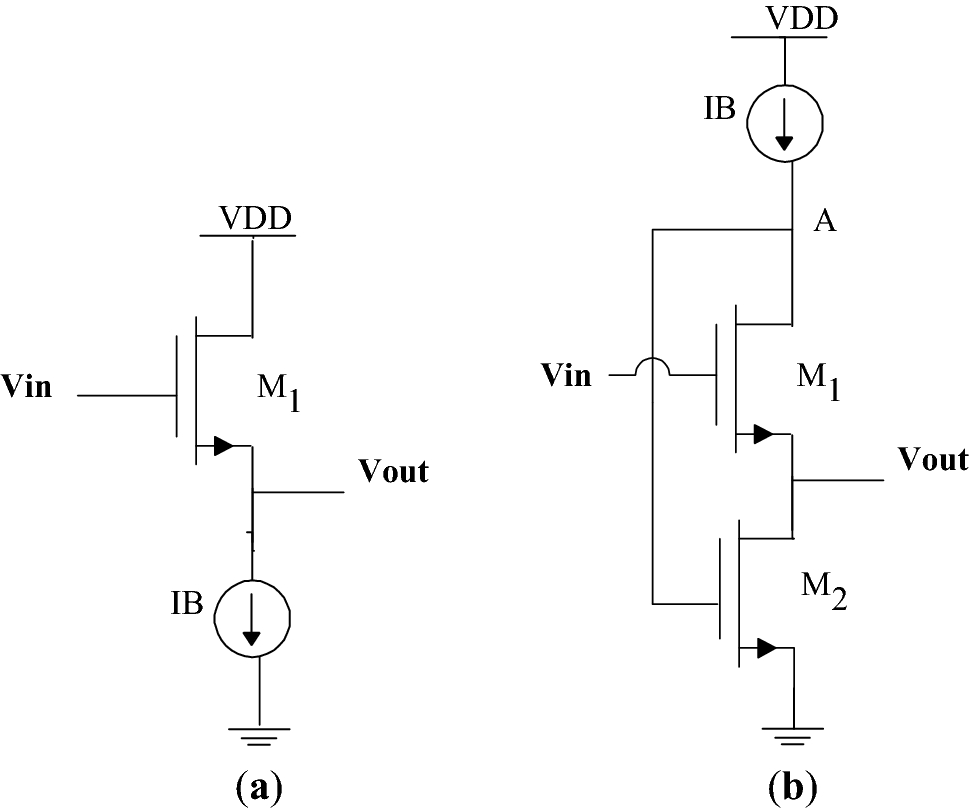

```bibtex
Domala, N., Sasikala, G. Low power flipped voltage follower current mirror with improved input output impedances. Sādhanā 46, 142 (2021). https://doi.org/10.1007/s12046-021-01665-6
```

## **NetList generation and LVS**
let's go through the step by step procedure to generate LVS and DRC clean layout of a FVF cell.

In [ ]:
from glayout import MappedPDK, sky130 , gf180
#from gdsfactory.cell import cell
from gdsfactory import Component
from gdsfactory.components import text_freetype, rectangle

In [ ]:
from glayout import nmos, pmos
from glayout import via_stack
from glayout import rename_ports_by_orientation
from glayout import tapring

In [ ]:
from glayout.util.comp_utils import evaluate_bbox, prec_center, prec_ref_center, align_comp_to_port
from glayout.util.port_utils import add_ports_perimeter,print_ports
from glayout.util.snap_to_grid import component_snap_to_grid
from glayout.spice.netlist import Netlist

In [ ]:
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route
from glayout.routing.L_route import L_route

FVF has two fets as shown in the schematic. We call M1 as input fet and M2 as feedback fet. Lets define arguments for the FETs

### 2. Basic Usage of the GLayout Framework
Each generator is a Python function that takes a `MappedPDK` object as a parameter and generates a DRC clean layout for the given PDK. The generator may also accept a set of optional layout parameters such as the width or length of a MOSFET. All parameters are normal Python function arguments.

The generator returns a `GDSFactory.Component` object that can be written to a `.gds` file and viewed using a tool such as Klayout. In this example, the `gdstk` library is used to convert the `.gds` file to an SVG image for viewing.

The pre-PEX SPICE netlist for the component can be viewed using `component.info['netlist'].generate_netlist()`.

In the following example the FET generator `glayout.primitives.fet` is imported and run with both the [Skywater 130](https://skywater-pdk.readthedocs.io/en/main/) and [GF180](https://gf180mcu-pdk.readthedocs.io/en/latest/) PDKs.

#### Demonstration of Basic Layout / Netlist Generation in SKY130 & GF180

In [ ]:
import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Used to display the results in a grid (notebook only)
left = widgets.Output()
leftSPICE = widgets.Output()
right = widgets.Output()
rightSPICE = widgets.Output()
hide = widgets.Output()

grid = widgets.GridspecLayout(1, 4)
grid[0, 0] = left
grid[0, 1] = leftSPICE
grid[0, 2] = right
grid[0, 3] = rightSPICE
display(grid)

def display_gds(gds_file, scale = 3):
  # Generate an SVG image
  top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
  top_level_cell.write_svg('out.svg')

  # Scale the image for displaying
  fig = sg.fromfile('out.svg')
  fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
  fig.save('out.svg')

  # Display the image
  IPython.display.display(IPython.display.SVG('out.svg'))

def display_component(component, scale = 3):
  # Save to a GDS file
  with hide:
    component.write_gds("out.gds")

  display_gds('out.gds', scale)

with hide:
  # Generate the sky130 component
  component_sky130 = nmos(pdk = sky130, fingers=5)
  # Generate the gf180 component
  component_gf180 = nmos(pdk = gf180, fingers=5,with_dnwell=False)

# Display the components' GDS and SPICE netlists
with left:
  print('Skywater 130nm N-MOSFET (fingers = 5)')
  display_component(component_sky130, scale=2)
with leftSPICE:
  print('Skywater 130nm SPICE Netlist')
  print(component_sky130.info['netlist'].generate_netlist())

with right:
  print('GF 180nm N-MOSFET (fingers = 5)')
  display_component(component_gf180, scale=2)
with rightSPICE:
  print('GF 180nm SPICE Netlist')
  print(component_gf180.info['netlist'].generate_netlist())

### This part is just to import the file you created from Tutorial 1

In [ ]:
import sys
import os
from pathlib import Path
sys.path.append(os.path.abspath("./FVF"))

from my_FVF import flipped_voltage_follower,add_fvf_labels

### Creating A Netlist

In [ ]:
# This is a different way of creating netlist compared to what we already have in the repo.
# Instead of giving the low level components as input, you append them to the top_level.info in component function.
# Then you can access them as showed here.

def fvf_netlist(fvf_in: Component) -> Netlist:

    fet_1 = fvf_in.info["fet_1"]  
    fet_2 = fvf_in.info["fet_2"]
    
    netlist = Netlist(circuit_name='FLIPPED_VOLTAGE_FOLLOWER', nodes=['VIN', 'VBULK', 'VOUT', 'Ib'])
    
    netlist.connect_netlist(fet_1.info['netlist'], [('D', 'Ib'), ('G', 'VIN'), ('S', 'VOUT'), ('B', 'VBULK')])
    netlist.connect_netlist(fet_2.info['netlist'], [('D', 'VOUT'), ('G', 'Ib'), ('S', 'VBULK'), ('B', 'VBULK')])
    
    fvf_in.info['netlist'] = netlist
    
    return fvf_in

my_fvf = fvf_netlist(flipped_voltage_follower(gf180, width=(4,2.75), length=(2,1)))
my_fvf  = add_fvf_labels(my_fvf, gf180)
my_fvf .name = "FVF"
#my_fvf.write_gds('out_FVF.gds')
my_fvf.show()
print(my_fvf.info['netlist'].generate_netlist())

### Run LVS
 LVS(Layout Versus Schematic) is an automated process that compares the extracted netlist of the physical layout (how the transistors and wires are actually drawn on the silicon) against the original, intended netlist from the schematic (the circuit's functional design). Its primary goal is to ensure that the layout precisely matches the schematic, catching any discrepancies like shorts, opens, missing components, or incorrect connections. `Netgen` is the tool we use for LVS here.

In [ ]:
fvf = fvf_netlist(add_fvf_labels(flipped_voltage_follower(gf180,width=(4,2.75),length=(2,1)),gf180))
fvf.name = "fvf"
fvf_gds = fvf.write_gds("fvf.gds")
#display_gds(fvf_gds)
fvf.show()
netgen_lvs_result = gf180.lvs_netgen(fvf, fvf.name)

## Extraction

In [ ]:
#At first, we need to properly set PDKPATH and PDK_ROOT 

print("Making sure your environment varriables are still correctly set")
print(" I am using PDK in: ",os.environ['PDK_ROOT'],"\n PDK name: ",os.environ['PDK'],"\n The PDK files are at: ",os.environ['PDKPATH'])

In [ ]:
import tempfile
magicrc_file = Path(os.environ['PDKPATH']) / "libs.tech" / "magic" / f"{os.environ['PDK']}.magicrc"
magicrc_file

In [ ]:
design_name=fvf.name
path_to_dir = Path("./FVF").resolve() / "ext" / design_name
if not path_to_dir.exists():
    path_to_dir.mkdir(parents=True, exist_ok=False)

pex_path = path_to_dir / f"{design_name}_pex.spice"
gds_path = path_to_dir / f"{design_name}.gds"


fvf.write_gds(str(gds_path))
    
magic_script_content = f"""
drc off            
gds flatglob *\\$\\$*
gds read {gds_path}

flatten {design_name}
load {design_name}
select top cell
extract do local
extract all
ext2sim labels on
ext2sim
extresist tolerance 10
extresist
ext2spice lvs
ext2spice cthresh 0
ext2spice extresist on
ext2spice -o {str(pex_path)}
exit
"""

with tempfile.NamedTemporaryFile(mode='w', delete=False) as magic_script_file:
    magic_script_file.write(magic_script_content)
    magic_script_path = magic_script_file.name
    
magic_cmd = f"bash -c 'magic -rcfile {magicrc_file} -noconsole -dnull < {magic_script_path}'",
magic_subproc = subprocess.run(
    magic_cmd, 
    shell=True,
    check=True,
    capture_output=True
)

magic_subproc_code = magic_subproc.returncode
magic_subproc_out = magic_subproc.stdout.decode('utf-8')
print(magic_subproc_out)

#You might want to remove the gds file for size concerns
# or keep it for testing
# os.remove(magic_script_path)
# for file in os.listdir(path_to_dir):
#         if file.endswith(".gds"):
#              os.remove(file)

In [ ]:
import glob
extensions = [
            "els"
            "*.gds",
            "*.ext",
            "*.res.ext",
            "*.lvs.rpt",
            "*_lvs.rpt",
            "*.nodes",
            "*.sim",
            "*.pex.spice",
            "*_pex.spice"
            ]
files_to_delete = []
for ext in extensions:
    files_to_delete.extend(glob.glob(ext))
    
# Delete the files
for file_path in files_to_delete:
    try:
        os.remove(file_path)
        print(f"Deleted: {file_path}")
    except OSError as e:
        print(f"Error deleting {file_path}: {e}")

### Post-PEX simulation
We do `.op` analysis and `.ac` anaysis on our fvf block.

#### `.op` analysis - find out the DC voltage at output node

In [ ]:
designs_file=str(Path(os.environ['PDKPATH']) / "libs.tech" / "ngspice" / "design.ngspice")
models_file = str(Path(os.environ['PDKPATH']) / "libs.tech" / "ngspice" / "sm141064.ngspice")

pex_file = str(pex_path).split("/")[-1]

fvf_op_tb_string=f"""* FVF Output Impedance Testbench
.temp 25
.param vcm = 1.3
.param ib = 10u

************* Power Supplies *************
Vsupply VDD GND 1.8
V0 vb GND 0

************* Input Bias (DC bias at IN) *************
VIN vin GND {{vcm}}  ; Mid-supply bias (renamed from 'IN' to 'VIN' to avoid conflict if 'IN' is a global node or subckt port)
Ibias VDD ib {{ib}}

************* DUT: FVF Subcircuit *************
**Import GF180 lib
.include {designs_file}
.lib {models_file} typical

** Import fvf subcircuit
.include {pex_file}
* Adjust node order if needed based on your fvf_pex.spice subcircuit definition.
* Assuming fvf subcircuit takes (vb, output_node, input_node, ibias_node)
XDUT vb vin FVF_OUT ib fvf

************* Analysis *************
* Operating point (for sanity check)
.op ; Uncomment this to run DC operating point analysis and check node voltages

.GLOBAL VDD 
.GLOBAL GND

.end
"""

tb1_path = path_to_dir / f"{design_name}_op_tb.sp"
tb1_path.write_text(fvf_op_tb_string, encoding="utf-8")

In [ ]:
tb1_file = "./FVF/ext/fvf/"+str(tb1_path).split("/")[-1]

try:
    ngspice_subproc = subprocess.run(
        ['ngspice', '-b', str(tb1_file)],
        check=True,
        capture_output=True
    )
    print(ngspice_subproc.stdout.decode('utf-8'))
except subprocess.CalledProcessError as e:
    print("STDOUT:\n", e.stdout.decode())
    print("STDERR:\n", e.stderr.decode())

If you did not do any changes in testbench, the voltage at output node FVF_OUT should be around 0.45V

#### `.ac` analysis - find out the output impedance

In [ ]:
designs_file=str(Path(os.environ['PDKPATH']) / "libs.tech" / "ngspice" / "design.ngspice")
models_file = str(Path(os.environ['PDKPATH']) / "libs.tech" / "ngspice" / "sm141064.ngspice")

pex_file = str(pex_path).split("/")[-1]

fvf_zo_tb_string=f"""* FVF Output Impedance Testbench
.temp 25
.param vcm = 1.3
.param ib = 10u

************* Power Supplies *************
Vsupply VDD GND 1.8
V0 vb GND 0

************* Input Bias (DC bias at IN) *************
VIN vin GND {{vcm}}  ; Mid-supply bias (renamed from 'IN' to 'VIN' to avoid conflict if 'IN' is a global node or subckt port)
Ibias VDD ib {{ib}}

************* AC Test Source for Output Impedance Measurement *************
*Insert an AC current source at the output

I_TEST GND FVF_OUT AC 1u ; AC 1 magnitude, 0 DC offset, in series with FVF output

************* DUT: FVF Subcircuit *************
**Import GF180 lib
.include {designs_file}
.lib {models_file} typical

** Import fvf subcircuit
.include {pex_file}
* Adjust node order if needed based on your fvf_pex.spice subcircuit definition.
* Assuming fvf subcircuit takes (vb, output_node, input_node, ibias_node)
XDUT vb vin FVF_OUT ib fvf

************* AC analysis **************
* AC sweep to compute output impedance magnitude and phase
.ac dec 10 10 10G
************* Control Output *************
* Calculate Output impedance: Zout = V(FVF_OUT) / 1u
.plot AC MAG(V(FVF_OUT))/1e-6 ; Plots the magnitude of the calculated output impedance

.GLOBAL VDD 
.GLOBAL GND

.end
"""
tb2_path = path_to_dir / f"{design_name}_zo_tb.sp"
tb2_path.write_text(fvf_zo_tb_string, encoding="utf-8")


In [ ]:
tb2_file = "./FVF/ext/fvf/"+str(tb2_path).split("/")[-1]

try:
    ngspice_subproc = subprocess.run(
        ['ngspice', '-b', str(tb2_file)],
        check=True,
        capture_output=True
    )
    print(ngspice_subproc.stdout.decode('utf-8'))
except subprocess.CalledProcessError as e:
    print("STDOUT:\n", e.stdout.decode())
    print("STDERR:\n", e.stderr.decode())

In [ ]:
# # You can also run ngspice in batch mode
# !ngspice -b fvf_zo_tb.sp

***
# Part 10 — CMOS Inverter · part 1: layout + DRC

*Source: `tutorial/glayout_tutorial_INV_part1.ipynb`* · **Needs:** EDA tools (`klayout`, `magic`) for the DRC cells.

# Tutorial 1: **Notebook** - *INV*

**By 
gLayout Team**

__Content creators:__ Subham Pal, Saptarshi Ghosh

__Content reviewers:__ Mehedi Saligne

___
# Tutorial Objectives

This notebook is a tutorial on-

- **Importing** and **Placement** of FETs and other macros/Pcells with relative coordinates + Placing (and connecting) Via_stack on the ports of the FETs + encircling them with padrings.
- **Routing** between the placed *Vias* with *C_*, *L_*, *Straight_* and *smart* Routes and explaining the differences between these strategies. Particularly explaning the East/West/North/South angles, (For Example, why C has to parallel but L has to be perpendicular sides) and *Placing and connecting PINs for future LVS runs

## **Target** **Block** : **Inverter Cell**

The CMOS inverter is a fundamental digital circuit building block, widely used due to its low static power consumption, high noise immunity, and fast switching characteristics. It consists of a complementary pair of MOSFETs: one PMOS and one NMOS transistor, with their gates and drains connected together. The source of the PMOS is connected to the supply voltage (VDD), while the source of the NMOS is connected to ground (VSS).

### **Operation Principle**
- **Input Low (Logic 0):** The PMOS transistor turns ON and the NMOS turns OFF. This connects the output (VOUT) to VDD, producing a logic high (1) at the output.
- **Input High (Logic 1):** The NMOS transistor turns ON and the PMOS turns OFF. This connects the output to ground, producing a logic low (0) at the output.

This complementary switching action ensures that the output is always the logical inverse of the input, making the CMOS inverter a true logic inverter.

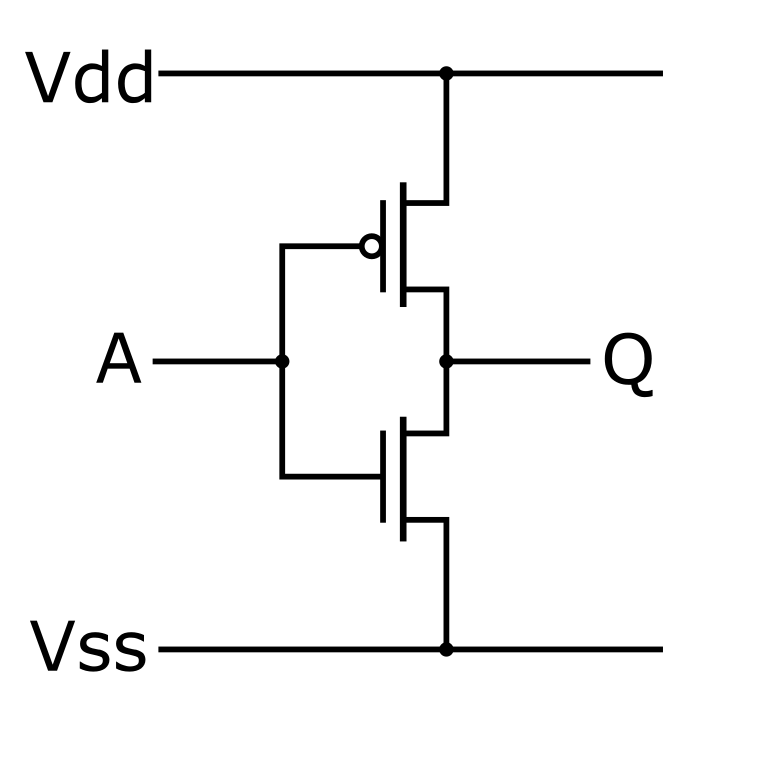

```bibtex
Wikimedia Commons contributors. (2010). CMOS Inverter Schematic [Diagram]. Wikimedia Commons. https://commons.wikimedia.org/wiki/File:CMOS_Inverter.svg
```


## **Layout generation**
let's go through the step by step procedure to generate LVS and DRC clean layout of a INV cell.


### *Creating environment for live GDSII viewer*
You can see the generated GDSII file immediately inside this notebook. You can also view it in Klayout for better understanding. Code for viewing it in Klayout is added but commented out.

In [ ]:
## Activate if necessary to install following packages

# !pip install svgutils
# !pip install ipywidgets

This cell only required for [IIC-OSIC Docker](https://github.com/iic-jku/IIC-OSIC-TOOLS). It imports all neceaasry environment varriable to current session

In [ ]:
import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Redirect all outputs here
hide = widgets.Output()

def display_gds(gds_file, path,scale = 3):
  
  # Generate an SVG image
  top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
  top_level_cell.write_svg(os.path.join(path,'out.svg'))
    
  # Scale the image for displaying
  fig = sg.fromfile(os.path.join(path,'out.svg'))
  fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
  fig.save(os.path.join(path,'out.svg'))

  # Display the image
  IPython.display.display(IPython.display.SVG(os.path.join(path,'out.svg')))
  os.remove(os.path.join(path,'out.gds'))

def display_component(component,path,scale = 3):
  # Save to a GDS file
  with hide:
    component.write_gds(os.path.join(path,'out.gds'))
  display_gds(os.path.join(path,'out.gds'),path,scale)

In [ ]:
from glayout import MappedPDK, sky130 , gf180
#from gdsfactory.cell import cell
from gdsfactory import Component
from gdsfactory.components import text_freetype, rectangle

In [ ]:
from glayout import nmos, pmos
from glayout import via_stack
from glayout import rename_ports_by_orientation
from glayout import tapring

In [ ]:
from glayout.util.comp_utils import evaluate_bbox, prec_center, prec_ref_center, align_comp_to_port
from glayout.util.port_utils import add_ports_perimeter,print_ports
from glayout.util.snap_to_grid import component_snap_to_grid
from glayout.spice.netlist import Netlist

In [ ]:
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route
from glayout.routing.L_route import L_route

INV has two complimentary fets as shown in the schematic. One is PMOS and another is NMOS. Their operations in INV are explained above. Lets define arguments for the FETs

In [ ]:
nmos_kwargs = {
    "with_tie": True,
    "with_dnwell": True,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2","met1"),
    "dummy_routes": True
}

pmos_kwargs = {
    "with_tie": True,
    "dnwell": False,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2","met1"),
    "dummy_routes": True
}

There is no need to manually define the kwargs for your code. This is only done for this notebook implementation.


Now, Let's create a list for parameters which we need for our function-

* pdk: pdk to use
* placement: either "horizontal" or "vertical"
* width: (input fet, feedback fet)
* length: (input fet, feedback fet)
* fingers: (input fet, feedback fet)
* multipliers: (input fet, feedback fet)
* dummy_1: dummy for input fet
* dummy_2: dummy for feedback fet


In [ ]:
inverter_config={
        "pdk": gf180, # pdk to use
        "placement" : "horizontal", # the two fets can be placed either vertically or horizontally
        "width": (3,3), # width of the input fet and feedback fet respectively.
        "length": (None,None), # length of the input fet and feedback fet respectively. None refers to the min length in the pdk.
        "fingers": (1,1), # no. of fingers of the input fet and feedback fet respectively.
        "multipliers": (1,1), #no. of multipliers of the input fet and feedback fet respectively.
        "dummy_1": (True,True), # dummy pattern for input fet (left,right)
        "dummy_2": (True,True), # dummy pattern for the feedback fet (left,right)
        "tie_layers1": ("met2","met1"), #tapring metal layers 
        "tie_layers2": ("met2","met1"), #tapring metal layers 
        "sd_rmult":1, # thickness of the sd metal layer.
}

### First: We create a top level component and add a name

In [ ]:
top_level = Component(name="inverter")

### Two fets

For our INV block, we do not want deep nwell. However nmos and pmos primitives have different parameter name for deepnwell.
For pmos it is set to false by default.We need to set it to false if the device type is given as nmos.
We could've just set it properly in our nmos_kwargs,
but since you will probably not code the layout for a notebook, we show a general way of solving this issue.


In [ ]:
pdk=inverter_config["pdk"]
pdk.activate()

In [ ]:
width=inverter_config["width"]
length=inverter_config["length"]
fingers=inverter_config["fingers"]
multipliers=inverter_config["multipliers"]

dummy_1=inverter_config["dummy_1"]
dummy_2=inverter_config["dummy_2"]
tie_layers1=inverter_config["tie_layers1"]
tie_layers2=inverter_config["tie_layers2"]
sd_rmult=inverter_config["sd_rmult"]

In [ ]:
#fet_1 is the input fet
fet_P = pmos(pdk, width=width[0], fingers=fingers[0], multipliers=multipliers[0], with_dummy=dummy_1, with_substrate_tap=False, length=length[0], tie_layers=tie_layers1, sd_rmult=sd_rmult, **pmos_kwargs )
#fet_2 is the feedback fet
nmos_kwargs["with_dnwell"] = False
fet_N = nmos(pdk, width=width[1], fingers=fingers[1], multipliers=multipliers[1], with_dummy=dummy_2, with_substrate_tap=False, length=length[1], tie_layers=tie_layers2, sd_rmult=sd_rmult, **nmos_kwargs)

Adding the references of the FETs to the top level component

In [ ]:
fet_P_ref = top_level << fet_P
fet_N_ref = top_level << fet_N

fet_P_ref.name = "fet_P"
fet_N_ref.name = "fet_N"

#let's take a look at our current state of layout
## To see in Klayout via Klive
#top_level.show()
display_component(top_level, scale = 5,path="../../")
## If you want to save the gds file at this stage
#primary_gds = top_level.write_gds("before_placement.gds")

### Placement

When a cell is referenced to the top level, the center of the cell is aligned to the (0,0) co-ordinate.
As of now, both of our fets are centered at (0,0). We need place them properly depending on the placement parameter.

In [ ]:
placement=inverter_config["placement"]
ref_dimensions = evaluate_bbox(fet_N)


evaluate_bbox returns maximum width and maximum height of the block as a tuple(width,height).

So here we have `ref_dimensions=(x-dimension of fet_2, y-dimension of fet_2)`

For horizontal placement , we need to move the fet_2 in rightward direction.
We use the movex function, which moves the center of the block in x-directon upto a certain distance. We need to find out this distance.
Remember that both fet_1 and fet_2 are centered at (0,0) co-ordinate right now.
At first we move the center of fet_2 to rightmost point of fet_1 using the xmax function, i.e, (fet_1_ref.xmax,0).
Now we will find that left half of fet_2 is overlapping with fet_1, so we need to move it at rightward direction again.We move it by ref_dimensionsp[0]/2 distance.
Now we see that the rightmost point of fet_1 and leftmost point of fet_2 have no seperation between them.
This will cause a drc error. So we move it again by max seperation needed between two metal layers for drc free layout.
We move it by 1um again for leaving some routing space for future use.

Vertical placement can be done in similar way by using movey function.

In [ ]:
if placement == "horizontal":
    fet_N_ref.movex(fet_P_ref.xmax)
    display_component(top_level, scale = 2,path="../../")
    fet_N_ref.movex(ref_dimensions[0]/2)
    display_component(top_level, scale = 2,path="../../")
    fet_N_ref.movex(pdk.util_max_metal_seperation()+1)
elif placement == "vertical":
    display_component(top_level, scale = 2,path="../../")
    fet_N_ref.movey(fet_P_ref.ymin - ref_dimensions[1]/2 - pdk.util_max_metal_seperation()-1)
else:
        raise ValueError("Placement must be either 'horizontal' or 'vertical'.")
    
# let's see how our block looks after placement
display_component(top_level, scale = 2,path="../../")
## To see in Klayout via Klive
#top_level.show()

 ### Routing

Now that our fets are properly placed, we need to make proper connections between ports (i.e. Gates, Sources and Drains of the FETs).
Each port has four directions- East,North,West,South which means 0,90,180,270 degrees respectively.
You can connect directly to a fet port. For better felxibility in routing, we choose add some intermediate vias here.

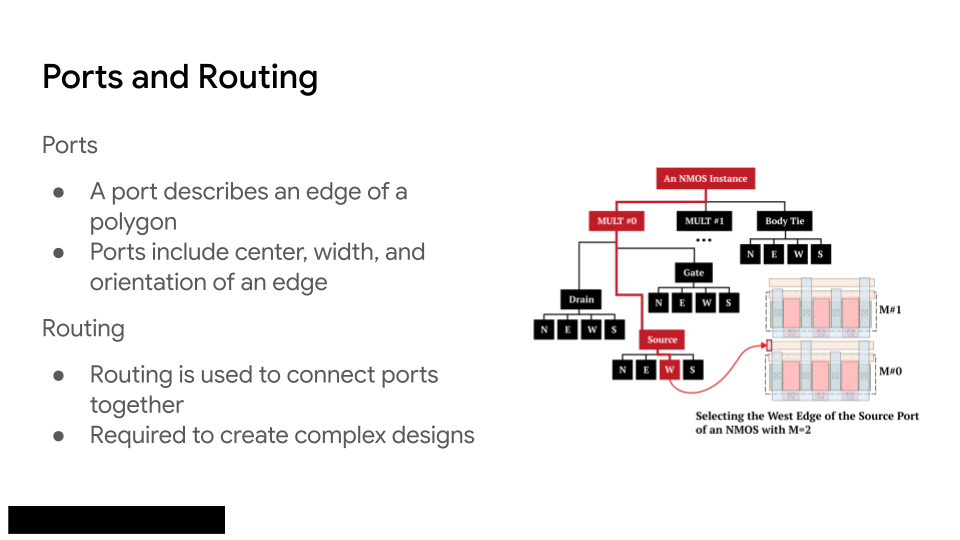


In [ ]:
viam2m3 = via_stack(pdk, "met2", "met3", centered=True) #met2 is the bottom layer. met3 is the top layer.

#we need four such vias
drain_P_via = top_level << viam2m3
source_P_via = top_level << viam2m3
gate_P_via = top_level << viam2m3

drain_N_via = top_level << viam2m3
gate_N_via = top_level << viam2m3

The move function moves the center of a specific cell to a specific co-ordinate.
The co-ordinates of the center of a port can be accesed by using cell_name.ports["port_name"].center
Using these two and other techniques previously discussed, we properly place these 4 vias.

In [ ]:
drain_P_via.move(fet_P_ref.ports["multiplier_0_drain_W"].center).movex(-1.5)
drain_N_via.move(fet_N_ref.ports["multiplier_0_drain_W"].center).movex(-1.5)

source_P_via.move(fet_P_ref.ports["multiplier_0_source_E"].center).movex(1.5)

gate_P_via.move(fet_P_ref.ports["multiplier_0_gate_E"].center).movex(1)
gate_N_via.move(fet_N_ref.ports["multiplier_0_gate_E"].center).movex(1)

# let's see where those vias are now
## To see in Klayout via Klive
#top_level.show()
display_component(top_level, scale = 3,path="../../")

Now that the vias are placed, time to make metal routing.
There are three basic types of routing available:

- `straight_route` - the ports must be straight to each other, i.e, opposite direction and same x or y coordinate.
- `L_route` - has a 90&deg; bend, ports must be perpendicular to each other.
- `c_route` -  has two 90&deg; bends(c shaped), ports must have same direction.

Each routing function has multiple parameters. See [here](https://github.com/idea-fasoc/OpenFASOC/tree/main/openfasoc/generators/glayout/glayout/flow/routing)

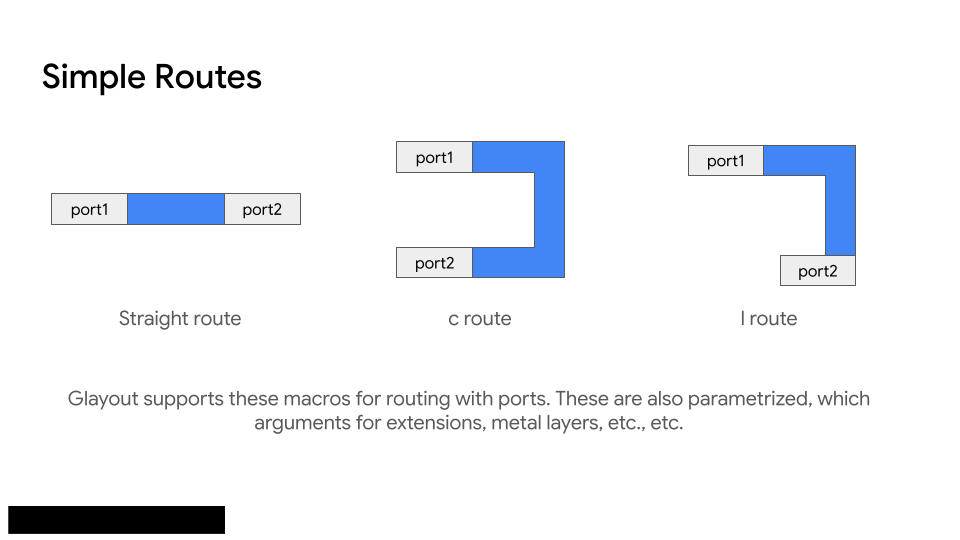

Bonus: You can see all avaliable ports by `top_level.pprint_ports()`

From the schematic, we see that we need to connect these two nodes-

1. **Connect the Source of M1 (PMOS) to VDD:**  
   Insert an intermediate via near the source of M1 and connect it to the VDD rail using a metal trace.

2. **Connect the Source of M2 (NMOS) to GND:**  
   Insert an intermediate via near the source of M2 and connect it to the GND rail using a metal trace.

3. **Connect the Drains of M1 and M2 Together (Output Node):**  
   Insert intermediate vias near the drain of M1 (PMOS) and the drain of M2 (NMOS), then connect them together with a metal trace. This node forms the inverter output.

4. **Connect the Gates of M1 and M2 Together (Input Node):**  
   Insert intermediate vias near the gate of M1 (PMOS) and the gate of M2 (NMOS), then connect them together with a metal trace. This node forms the inverter input.

In [ ]:
top_level << straight_route(pdk, fet_P_ref.ports["multiplier_0_gate_E"], gate_P_via.ports["bottom_met_N"])
top_level << straight_route(pdk, fet_N_ref.ports["multiplier_0_gate_E"], gate_N_via.ports["bottom_met_W"])
top_level << straight_route(pdk, fet_P_ref.ports["multiplier_0_source_E"], source_P_via.ports["bottom_met_W"])
top_level << straight_route(pdk, fet_P_ref.ports["multiplier_0_drain_W"], drain_P_via.ports["bottom_met_E"])
top_level << straight_route(pdk, fet_N_ref.ports["multiplier_0_drain_W"], drain_N_via.ports["bottom_met_E"])

if placement == "horizontal":
    top_level << c_route(pdk, gate_P_via.ports["top_met_S"], gate_N_via.ports["top_met_S"],extension=1.2*max(width[0],width[1]), width1=0.32, width2=0.32, cwidth=0.32, e1glayer="met3", e2glayer="met3", cglayer="met2")
    top_level << c_route(pdk, drain_P_via.ports["top_met_N"], drain_N_via.ports["top_met_N"],extension=1.2*max(width[0],width[1]), width1=0.32, width2=0.32, cwidth=0.32, e1glayer="met3", e2glayer="met3", cglayer="met2")
elif placement == "vertical":
    top_level << straight_route(pdk, gate_P_via.ports["top_met_S"], gate_N_via.ports["top_met_S"])
    top_level << straight_route(pdk, drain_P_via.ports["top_met_N"], drain_N_via.ports["top_met_N"])
else:
        raise ValueError("Placement must be either 'horizontal' or 'vertical'.")
    
try:
    top_level << straight_route(pdk, fet_N_ref.ports["multiplier_0_source_W"], fet_N_ref.ports["tie_W_top_met_W"], glayer1=tie_layers2[1], fullbottom=True)
except:
    pass

# let's see how those vias are now routed
#top_level.show()
display_component(top_level, scale = 3,path="../../")

Notice how in the above lines, ports used in straight routing has the opposite direction, e.g. (E,W) but ports used in c_route has the same direction (N,N).

### Renaming Ports

We need to rename ports and add them to the top level component for ease of routing in hierarchial design.
Here we rename ports by adding appropriate prefix to the all ready existing port names.


In [ ]:
top_level.add_ports(fet_P_ref.get_ports_list(), prefix="P_")
top_level.add_ports(fet_N_ref.get_ports_list(), prefix="N_")
top_level.add_ports(drain_P_via.get_ports_list(), prefix="P_drain_")
top_level.add_ports(source_P_via.get_ports_list(), prefix="P_source_")
top_level.add_ports(gate_P_via.get_ports_list(), prefix="P_gate_")
top_level.add_ports(drain_N_via.get_ports_list(), prefix="N_drain_")
top_level.add_ports(gate_N_via.get_ports_list(), prefix="N_gate_")

In [ ]:
component = component_snap_to_grid(rename_ports_by_orientation(top_level))
    
# Now that our block is complete, let's see how it looks now!!
#component.show()
display_component(component, scale = 2,path="../../")
#component.show()
##inv_gds = component.write_gds("inv.gds")

Printing List of Ports of the Component

In [ ]:
## To see all Ports
# component.pprint_ports()

## To see selected ports
# for s in component.get_ports_list():
#     if len(s.name.split("_")) <4:
#         if set(["P","gate"]).issubset(set(s.name.split("_"))):
#             print(s.name, s.port_type , s.orientation, s.center, s.width, s.layer)

### Add Pins
We need to add i/o pins, power supply pins and bias pins to a circuit. This will be needed later to do LVS check(Layout Vs Schematic) and parasitic extraction(PEX).
Our inverter has four pins (Nodes) - VIN, VOUT, VDD, VBULK

In [ ]:
psize=(0.5,0.5)
# list that will contain all port/comp info
move_info = list()
# create labels and append to info list

In [ ]:
# gnd
gndlabel = rectangle(layer=pdk.get_glayer("met3_pin"),size=psize,centered=True).copy()
gndlabel.add_label(text="VBULK",layer=pdk.get_glayer("met3_label"))
move_info.append((gndlabel,component.ports["N_tie_N_top_met_N"],None))
#gnd_ref = top_level << gndlabel;



#suply
suplabel = rectangle(layer=pdk.get_glayer("met3_pin"),size=psize,centered=True).copy()
suplabel.add_label(text="VDD",layer=pdk.get_glayer("met3_pin"))
move_info.append((suplabel,component.ports["P_source_top_met_N"],None))
#sup_ref = top_level << suplabel;


# output
outputlabel = rectangle(layer=pdk.get_glayer("met3_pin"),size=psize,centered=True).copy()
outputlabel.add_label(text="VOUT",layer=pdk.get_glayer("met3_pin"))
move_info.append((outputlabel,component.ports["P_drain_top_met_N"],None))
#op_ref = top_level << outputlabel;


# input
inputlabel = rectangle(layer=pdk.get_glayer("met3_pin"),size=psize,centered=True).copy()
inputlabel.add_label(text="VIN",layer=pdk.get_glayer("met3_pin"))
move_info.append((inputlabel,component.ports["P_gate_top_met_N"], None))
#ip_ref = top_level << inputlabel;


for comp, prt, alignment in move_info:
        alignment = ('c','b') if alignment is None else alignment
        compref = align_comp_to_port(comp, prt, alignment=alignment)
        top_level.add(compref)
component = top_level.flatten()


component.show()
display_component(top_level, scale =5,path="../../")

## Note
Now, lets construct the Pcell and export this code as a `.py` file. This is how your cell contributions should be structured. 

### Run DRC with Magic
Design Rule Check ensures that the physical layout of an integrated circuit adheres to the manufacturing constraints defined by the foundry, such as minimum spacing, width, and enclosure rules. `Magic` is the tool we use for DRC here.

In [ ]:
component.name="inv"
drc_result = gf180.drc_magic(component, component.name)

### DRC Checking Using External Tools (KLayout)
Design Rule Check (DRC) is the process of ensuring that a particular layout does not violate the constraints or _design rules_ imposed by the PDK.

[Klayout](https://klayout.de/) is a GDSII viewer and editor that also has a DRC feature. The design rules for the PDK, in this case the GF180 PDK, are described in a `.lydrc` file.

The following cell runs DRC on the component generated in the previous cell. The number of DRC errors reported will be displayed at the end of the output.

In [ ]:
drc_result = gf180.drc(component)

***
# Part 11 — CMOS Inverter · part 2: LVS + PEX

*Source: `tutorial/glayout_tutorial_INV_part2.ipynb`* · **Needs:** EDA tools (`magic`, `netgen`). **Run Part 10 first** (it writes `INV/my_INV.py`, imported here).

# Tutorial 2: **Notebook** - *FVF*

> 🚧 **Under Construction**

**By 
gLayout Team**

__Content creators:__ Subham Pal, Saptarshi Ghosh

__Content reviewers:__ Mehedi Saligne

___
# Tutorial Objectives

This notebook is a tutorial on-

- **LVS (Layout Versus Schematic):**  
  You will learn how to compare your physical layout with the original schematic to ensure they are functionally identical. This process helps catch connectivity or device mismatches before fabrication.

- **Extraction and Simulation:**  
  The tutorial will guide you through extracting parasitic elements from your layout, such as capacitance and resistance, to create a more accurate circuit model. You will then simulate the extracted netlist to analyze and verify the real-world performance of your design.

## **Target** **Block** : **Inverter Cell**

The CMOS inverter is a fundamental digital circuit building block, widely used due to its low static power consumption, high noise immunity, and fast switching characteristics. It consists of a complementary pair of MOSFETs: one PMOS and one NMOS transistor, with their gates and drains connected together. The source of the PMOS is connected to the supply voltage (VDD), while the source of the NMOS is connected to ground (VSS).

### **Operation Principle**
- **Input Low (Logic 0):** The PMOS transistor turns ON and the NMOS turns OFF. This connects the output (VOUT) to VDD, producing a logic high (1) at the output.
- **Input High (Logic 1):** The NMOS transistor turns ON and the PMOS turns OFF. This connects the output to ground, producing a logic low (0) at the output.

This complementary switching action ensures that the output is always the logical inverse of the input, making the CMOS inverter a true logic inverter.

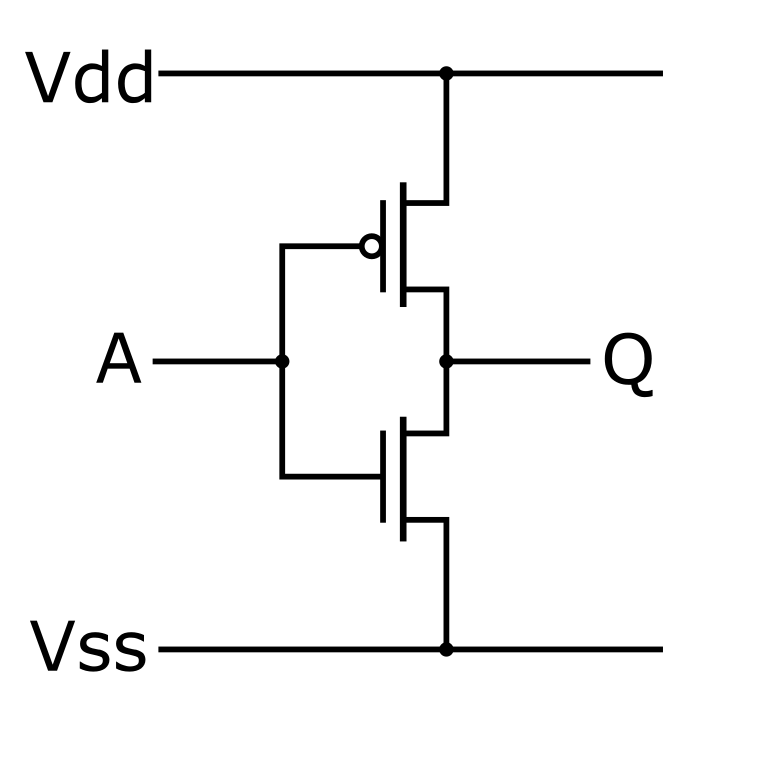

```bibtex
Wikimedia Commons contributors. (2010). CMOS Inverter Schematic [Diagram]. Wikimedia Commons. https://commons.wikimedia.org/wiki/File:CMOS_Inverter.svg
```


## **NetList generation and LVS**
let's go through the step by step procedure to generate LVS and DRC clean layout of a FVF cell.

In [ ]:
from glayout import MappedPDK, sky130 , gf180
from gdsfactory import Component
from gdsfactory.components import text_freetype, rectangle

import gdsfactory as gf
gf.clear_cache()

In [ ]:
from glayout import nmos, pmos
from glayout import via_stack
from glayout import rename_ports_by_orientation
from glayout import tapring

In [ ]:
from glayout.util.comp_utils import evaluate_bbox, prec_center, prec_ref_center, align_comp_to_port
from glayout.util.port_utils import add_ports_perimeter,print_ports
from glayout.util.snap_to_grid import component_snap_to_grid
from glayout.spice.netlist import Netlist

In [ ]:
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route
from glayout.routing.L_route import L_route

FVF has two fets as shown in the schematic. We call M1 as input fet and M2 as feedback fet. Lets define arguments for the FETs

### 2. Basic Usage of the GLayout Framework
Each generator is a Python function that takes a `MappedPDK` object as a parameter and generates a DRC clean layout for the given PDK. The generator may also accept a set of optional layout parameters such as the width or length of a MOSFET. All parameters are normal Python function arguments.

The generator returns a `GDSFactory.Component` object that can be written to a `.gds` file and viewed using a tool such as Klayout. In this example, the `gdstk` library is used to convert the `.gds` file to an SVG image for viewing.

The pre-PEX SPICE netlist for the component can be viewed using `component.info['netlist'].generate_netlist()`.

In the following example the FET generator `glayout.primitives.fet` is imported and run with both the [Skywater 130](https://skywater-pdk.readthedocs.io/en/main/) and [GF180](https://gf180mcu-pdk.readthedocs.io/en/latest/) PDKs.

#### Demonstration of Basic Layout / Netlist Generation in SKY130 & GF180

In [ ]:
# from glayout import nmos,sky130,gf180

# import gdstk
# import svgutils.transform as sg
# import IPython.display
# from IPython.display import clear_output
# import ipywidgets as widgets

# # Used to display the results in a grid (notebook only)
# left = widgets.Output()
# leftSPICE = widgets.Output()
# right = widgets.Output()
# rightSPICE = widgets.Output()
# hide = widgets.Output()

# grid = widgets.GridspecLayout(1, 4)
# grid[0, 0] = left
# grid[0, 1] = leftSPICE
# grid[0, 2] = right
# grid[0, 3] = rightSPICE
# display(grid)

# def display_gds(gds_file, scale = 3):
#   # Generate an SVG image
#   top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
#   top_level_cell.write_svg('out.svg')

#   # Scale the image for displaying
#   fig = sg.fromfile('out.svg')
#   fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
#   fig.save('out.svg')

#   # Display the image
#   IPython.display.display(IPython.display.SVG('out.svg'))

# def display_component(component, scale = 3):
#   # Save to a GDS file
#   with hide:
#     component.write_gds("out.gds")

#   display_gds('out.gds', scale)

# with hide:
#   # Generate the sky130 component
#   component_sky130 = nmos(pdk = sky130, fingers=5)
#   # Generate the gf180 component
#   component_gf180 = nmos(pdk = gf180, fingers=5)

# # Display the components' GDS and SPICE netlists
# with left:
#   print('Skywater 130nm N-MOSFET (fingers = 5)')
#   display_component(component_sky130, scale=2)
# with leftSPICE:
#   print('Skywater 130nm SPICE Netlist')
#   print(component_sky130.info['netlist'].generate_netlist())

# with right:
#   print('GF 180nm N-MOSFET (fingers = 5)')
#   display_component(component_gf180, scale=2)
# with rightSPICE:
#   print('GF 180nm SPICE Netlist')
#   print(component_gf180.info['netlist'].generate_netlist())

In [ ]:
import sys
import os
sys.path.append(os.path.abspath("./INV"))

from my_INV import inverter,add_inv_labels

In [ ]:
comp = inverter(gf180)
for s in comp.references:
    print(s.name)  # This will show 'fet_P', 'fet_N', etc.

In [ ]:
import tempfile
from pathlib import Path

magicrc_file = Path(os.environ['PDKPATH']) / "libs.tech" / "magic" / f"{os.environ['PDK']}.magicrc"

design_name = comp.name
path_to_dir = Path("./INV").resolve() / "ext" / design_name
path_to_dir.mkdir(parents=True, exist_ok=True)

pex_path = path_to_dir / f"{design_name}_pex.spice"
gds_path = path_to_dir / f"{design_name}.gds"
comp.write_gds(str(gds_path))

magic_script = f"""
drc off
gds flatglob *\\$\\$*
gds read {gds_path}
flatten {design_name}
load {design_name}
select top cell
extract do local
extract all
ext2sim labels on
ext2sim
extresist tolerance 10
extresist
ext2spice lvs
ext2spice cthresh 0
ext2spice extresist on
ext2spice -o {pex_path}
exit
"""
with tempfile.NamedTemporaryFile(mode='w', delete=False, suffix='.tcl') as f:
    f.write(magic_script)
    magic_script_path = f.name

magic_cmd = f"magic -rcfile {magicrc_file} -noconsole -dnull < {magic_script_path}"
res = subprocess.run(magic_cmd, shell=True, capture_output=True, text=True)
print(res.stdout[-800:])
if res.returncode != 0:
    print("STDERR:", res.stderr[-800:])
print("Wrote:", pex_path if pex_path.exists() else '(extraction did not produce a .spice file)')


In [ ]:
comp = add_inv_labels(comp, gf180)
comp.name = "INV"
#comp.write_gds('out_INV.gds')
comp.show()
#print("...Running DRC...")
drc_result = gf180.drc_magic(comp, "INV")

In [ ]:
# Build a SPICE netlist for the inverter using the fet references that
# my_INV.inverter() stashed on top_level.info (the same pattern FVF uses).
def inv_netlist(inv_in: Component) -> Component:
    fet_p = inv_in.info["fet_P"]
    fet_n = inv_in.info["fet_N"]
    netlist = Netlist(circuit_name='INVERTER', nodes=['VIN', 'VBULK', 'VOUT', 'VDD'])
    netlist.connect_netlist(fet_p.info['netlist'],
                            [('D', 'VOUT'), ('G', 'VIN'), ('S', 'VDD'), ('B', 'VBULK')])
    netlist.connect_netlist(fet_n.info['netlist'],
                            [('D', 'VOUT'), ('G', 'VIN'), ('S', 'VBULK'), ('B', 'VBULK')])
    inv_in.info['netlist'] = netlist
    return inv_in

comp = inv_netlist(comp)
print(comp.info['netlist'].generate_netlist())


In [ ]:
print('Inverter component:', comp.name)
print('ports:', list(comp.ports)[:8], '...')


### Run LVS
Design Rule Check ensures that the physical layout of an integrated circuit adheres to the manufacturing constraints defined by the foundry, such as minimum spacing, width, and enclosure rules. `Magic` is the tool we use for DRC here.

In [ ]:
# Run netgen LVS against the labeled inverter layout.
netgen_lvs_result = gf180.lvs_netgen(comp, comp.name)


## Extraction and Post-Pex Simulation

In [ ]:
import tempfile
from pathlib import Path

magicrc_file = Path(os.environ['PDKPATH']) / "libs.tech" / "magic" / f"{os.environ['PDK']}.magicrc"

design_name = comp.name
path_to_dir = Path("./INV").resolve() / "ext" / design_name
path_to_dir.mkdir(parents=True, exist_ok=True)

pex_path = path_to_dir / f"{design_name}_pex.spice"
gds_path = path_to_dir / f"{design_name}.gds"
comp.write_gds(str(gds_path))

magic_script = f"""
drc off
gds flatglob *\\$\\$*
gds read {gds_path}
flatten {design_name}
load {design_name}
select top cell
extract do local
extract all
ext2sim labels on
ext2sim
extresist tolerance 10
extresist
ext2spice lvs
ext2spice cthresh 0
ext2spice extresist on
ext2spice -o {pex_path}
exit
"""
with tempfile.NamedTemporaryFile(mode='w', delete=False, suffix='.tcl') as f:
    f.write(magic_script)
    magic_script_path = f.name

magic_cmd = f"magic -rcfile {magicrc_file} -noconsole -dnull < {magic_script_path}"
res = subprocess.run(magic_cmd, shell=True, capture_output=True, text=True)
print(res.stdout[-800:])
if res.returncode != 0:
    print("STDERR:", res.stderr[-800:])
print("Wrote:", pex_path if pex_path.exists() else '(extraction did not produce a .spice file)')


***
# Part 12 — BJT with gLayout

*Source: `tutorial/BJT_tutorials/test_bjt_glayout.ipynb`* · **Needs:** EDA tools (`magic`) for the extraction cells.

## Using the BJT models from glayout

In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
from glayout.primitives.bjt import draw_bjt
from glayout import MappedPDK, sky130 , gf180

In [ ]:
pdk=gf180
pdk.activate()

In [ ]:
bjt=draw_bjt(pdk,(5,5),"pnp")

In [ ]:
bjt.show()

In [ ]:
bjt.ports

In [ ]:
from glayout.primitives.bjt import multiplier, __mult_array_macro

In [ ]:
bjt=__mult_array_macro(pdk=pdk,active_area=(5,5),bjt_type="pnp",bc_rmult=2,multipliers=5)

In [ ]:
bjt.show()

In [ ]:
bjt.center

In [ ]:
bjt.pprint_ports()

In [ ]:
from glayout.primitives.bjt import pnp, npn

In [ ]:
bjt_pnp=pnp(pdk=pdk,active_area=(5,5),bc_rmult=2,multipliers=5)

In [ ]:
bjt_pnp.show()

In [ ]:
bjt_npn=npn(pdk=pdk,active_area=(5,5),bc_rmult=2,multipliers=5, with_dummy=(False,False))

In [ ]:
bjt_npn.show()

In [ ]:
from pathlib import Path
import os
import subprocess
import tempfile
magicrc_file = Path(os.environ['PDKPATH']) / "libs.tech" / "magic" / f"{os.environ['PDK']}.magicrc"
magicrc_file

In [ ]:
def extract_pex(design, path_to_dir):
    design_name=design.name
    if not path_to_dir.exists():
        path_to_dir.mkdir(parents=True, exist_ok=False)
    
    pex_path = path_to_dir / f"{design_name}_pex.spice"
    gds_path = path_to_dir / f"{design_name}.gds"
    
    design.write_gds(str(gds_path))
        
    magic_script_content = f"""
    drc off            
    gds flatglob *\\$\\$*
    gds read {gds_path}
    
    flatten {design_name}
    load {design_name}
    select top cell
    extract do local
    extract all
    ext2sim labels on
    ext2sim
    extresist tolerance 10
    extresist
    ext2spice lvs
    ext2spice cthresh 0
    ext2spice extresist on
    ext2spice -o {str(pex_path)}
    exit
    """
    
    with tempfile.NamedTemporaryFile(mode='w', delete=False) as magic_script_file:
        magic_script_file.write(magic_script_content)
        magic_script_path = magic_script_file.name
        
    magic_cmd = f"bash -c 'magic -rcfile {magicrc_file} -noconsole -dnull < {magic_script_path}'",
    magic_subproc = subprocess.run(
        magic_cmd, 
        shell=True,
        check=True,
        capture_output=True
    )
    
    magic_subproc_code = magic_subproc.returncode
    magic_subproc_out = magic_subproc.stdout.decode('utf-8')
    print(magic_subproc_out)

In [ ]:
import pathlib
path_to_dir = pathlib.Path.cwd().resolve() / "ext" / bjt_pnp.name
extract_pex(bjt_pnp, path_to_dir)

In [ ]:
import pathlib
path_to_dir = pathlib.Path.cwd().resolve() / "ext" / bjt_npn.name
extract_pex(bjt_npn, path_to_dir)

***
# Part 13 — BJT custom-pattern routing

*Source: `tutorial/BJT_tutorials/test_bjt_custom_pattern.ipynb`* · **Needs:** base setup only (layout-only).

# Custom patter for routing in BJTs

In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
from glayout.primitives.bjt import draw_bjt
from glayout import MappedPDK, sky130 , gf180

In [ ]:
pdk=gf180
pdk.activate()

In [ ]:
from glayout.primitives.bjt import multiplier, __mult_array_macro

In [ ]:
bjt=__mult_array_macro(pdk=pdk,active_area=(5,5),bjt_type="pnp",bc_rmult=2,
                       multipliers=3,
                       pattern=["A","B","B"], is_bc_shared=True)

In [ ]:
bjt.show()

In [ ]:
bjt.pprint_ports()

In [ ]:
from glayout.primitives.bjt import pnp, npn

In [ ]:
bjt_pnp=pnp(pdk=pdk,active_area=(5,5),bc_rmult=1,multipliers=4, pattern=["A","B","C","D"],is_bc_short=True)

In [ ]:
bjt_pnp.show()

In [ ]:
pattern=[["a","b","c"],["a","b","c"]]

In [ ]:
from glayout.util.pattern import check_pattern_level, transpose_pattern

In [ ]:
check_pattern_level(pattern)

In [ ]:
transpose_pattern(pattern)

In [ ]:
from glayout.primitives.bjt import multiplier, __mult_array_macro, __mult_2dim_array_macro

In [ ]:
bjt_2dim_array= __mult_2dim_array_macro(pdk=pdk,active_area=(5,5),bjt_type="pnp",bc_rmult=1,
                       multipliers=(3,3),
                       pattern=[["A","C","B"],["B","A","A"],["A","C","B"]], is_bc_shared=True)

In [ ]:
bjt_2dim_array.show()

In [ ]:
pattern= [["A","C","B"],["B","A","A"],["A","C","B"]]

In [ ]:
from glayout.util.pattern import get_cols_positions

In [ ]:
get_cols_positions(pattern)

In [ ]:
get_cols_positions(pattern).keys()

In [ ]:
bjt_2dim_array.pprint_ports()

In [ ]:
from glayout.primitives.bjt import pnp, npn

In [ ]:
from glayout.util.pattern import check_pattern_level, transpose_pattern

In [ ]:
pattern =[ ["D", "E", "D", "D"],
["D", "D", "C", "D"],
["D", "B", "A",	"D"],
["D", "A", "B",	"D"],
["D", "C", "D",	"D"],
["D", "D", "E",	"D"]]

In [ ]:
bjt_pnp=pnp(pdk=pdk,active_area=(5,5),bc_rmult=1,
                       multipliers=(6,4),
                       pattern=transpose_pattern(pattern),is_bc_shared=True)

In [ ]:
bjt_pnp.show()

The next code is specific for the AutoMOS project. In case of reuse, make sure the path is pointing to the right folder

In [ ]:
from pathlib import Path
import os

In [ ]:
import pathlib
designs_path=pathlib.Path.cwd() / "out"
library = designs_path / "libs" / "core_bandgap"
cell_name = "bandgap_bjt"
cell_path = library / cell_name

try:
    os.makedirs(cell_path, exist_ok=True)
    print(f"Directory '{cell_path}' ensured to exist.")
except OSError as e:
    print(f"Error creating directory '{cell_path}': {e}")

In [ ]:
bjt_pnp.write_gds(cell_path / "bandgap_bjt.gds")

***
# Part 14 — BJT with raw gdsfactory

*Source: `tutorial/BJT_tutorials/test_bjt_gdsfactory.ipynb`* · **Needs:** EDA tools (`magic`) for the extraction cells.

## Generating BJT using pure GDSfactory

In [ ]:
from glayout import MappedPDK, sky130 , gf180
#from gdsfactory.cell import cell
from gdsfactory import Component
from gdsfactory.geometry import boolean
from gdsfactory.components import text_freetype, rectangle, array, rectangular_ring

In [ ]:
top_level=Component(name="BJT")
pdk=gf180
pdk.activate()

In [ ]:
pdk.__dict__

In [ ]:
cdims=(8.28, 8.28)
bdims=(6.8,6.8)
edims=(5.32,5.32)
bjt_layers=("p+s/d","n+s/d","p+s/d")
bjt_dims=(edims,bdims,cdims)

In [ ]:
e_diff= rectangle(size=bjt_dims[0],layer=pdk.get_glayer(bjt_layers[0]),centered=True)
bt_diff= rectangle(size=bjt_dims[1],layer=pdk.get_glayer(bjt_layers[1]),centered=True)
ct_diff= rectangle(size=bjt_dims[2],layer=pdk.get_glayer(bjt_layers[2]),centered=True)
b_diff= boolean(A=bt_diff, B=e_diff, operation="not", 
                layer=pdk.get_glayer(bjt_layers[1]))
c_diff= boolean(A=ct_diff, B=bt_diff, operation="not",
                layer=pdk.get_glayer(bjt_layers[2]))
top_level.add_ref(e_diff)
top_level.add_ref(b_diff)
top_level.add_ref(c_diff)

In [ ]:
## Adding nwell
nw = rectangle(size=bjt_dims[1],layer=pdk.get_glayer("nwell"),centered=True)
top_level.add_ref(nw)

In [ ]:
comp_min_sep=0.16
contact_dims=(0.22, 0.22)
contact_inner_sep=0.25
contact_comp_sep=0.1

In [ ]:
import numpy as np

In [ ]:
## Adding comp
comp_layer_name="active_diff"
comp_e= rectangle(size=tuple(np.asarray(bjt_dims[0])-2*comp_min_sep),
                  layer=pdk.get_glayer(comp_layer_name),centered=True)
comp_out_b= rectangle(size=tuple(np.asarray(bjt_dims[1])-2*comp_min_sep),
                      layer=pdk.get_glayer(comp_layer_name),centered=True)
comp_inn_b= rectangle(size=tuple(np.asarray(bjt_dims[0])+2*comp_min_sep),
                      layer=pdk.get_glayer(comp_layer_name),centered=True)
comp_out_c= rectangle(size=tuple(np.asarray(bjt_dims[2])-2*comp_min_sep),
                      layer=pdk.get_glayer(comp_layer_name),centered=True)
comp_inn_c= rectangle(size=tuple(np.asarray(bjt_dims[1])+2*comp_min_sep),
                      layer=pdk.get_glayer(comp_layer_name),centered=True)

comp_b= boolean(A=comp_out_b, B=comp_inn_b, operation="not", 
                layer=pdk.get_glayer(comp_layer_name))
comp_c= boolean(A=comp_out_c, B=comp_inn_c, operation="not",
                layer=pdk.get_glayer(comp_layer_name))
top_level.add_ref(comp_e)
top_level.add_ref(comp_b)
top_level.add_ref(comp_c)

In [ ]:
#top_level.show()

In [ ]:
# Adding contacts
comp_min_sep=0.16
contact_dims=(0.22, 0.22)
contact_inner_sep=0.25
contact_array_sep=0.28
contact_comp_sep=0.1

contact_layer_name="mcon"
contact= rectangle(size=contact_dims,
                  layer=pdk.get_glayer(contact_layer_name),centered=True)

n_contacts_e=np.floor((np.asarray(edims)-
              2*comp_min_sep-
              2*contact_comp_sep-
              np.asarray(contact_dims)
             )/(np.asarray(contact_dims)+contact_array_sep)+
                      np.asarray((1,1)))

In [ ]:
n_contacts_b=np.floor((np.asarray(bdims)-
              2*comp_min_sep-
              2*contact_comp_sep-
              np.asarray(contact_dims)-
              np.asarray((1,0))*(np.asarray(bdims)-np.asarray(edims)-2*comp_min_sep)
             )/(np.asarray(contact_dims)+contact_inner_sep)+
                      np.asarray((1,1)))

n_contacts_c=np.floor((np.asarray(cdims)-
              2*comp_min_sep-
              2*contact_comp_sep-
              np.asarray(contact_dims)-
              np.asarray((1,0))*(np.asarray(cdims)-np.asarray(bdims)-2*comp_min_sep)
             )/(np.asarray(contact_dims)+contact_inner_sep)+
                      np.asarray((1,1)))

In [ ]:
from decimal import Decimal, ROUND_HALF_UP
def round(x):
    return float(Decimal(x).quantize(Decimal("0.001"), 
                                 rounding=ROUND_HALF_UP)) 

def get_half_contact_array_size_m1(n_contacts,contact_inner_sep,contact_dims):
    return (n_contacts-1)*(contact_inner_sep +np.asarray(contact_dims))/2

def get_mid_ring(adims, bdims):
    return (np.asarray(adims)+np.asarray(bdims))/2 

def get_shift(position, n_contacts,contact_inner_sep, contact_dims, mid_ring):
    half_array_contact_size =  get_half_contact_array_size_m1(n_contacts,contact_inner_sep,contact_dims)
    
    if position=="top":
        hshift=(-1,0)*half_array_contact_size
        vshift=(0,1)*mid_ring/2
    elif position=="left":
        hshift=(-1,0)*mid_ring/2
        vshift=(0,-1)*half_array_contact_size
    elif position=="right":
        hshift=(1, 0)*mid_ring/2
        vshift=(0,-1)*half_array_contact_size
    elif position=="bottom":
        hshift=(-1, 0)*half_array_contact_size
        vshift=(0,-1)*mid_ring/2
    else:
        raise ValueError(f"Not a valid position: {position}")
    return hshift+vshift


In [ ]:
mid_ring_b_e=get_mid_ring(edims, bdims)
mid_ring_c_b=get_mid_ring(bdims, cdims)
get_shift("bottom", n_contacts_b,contact_inner_sep, contact_dims, mid_ring_b_e)

In [ ]:
def add_ring_contacts(parent, reference,n_contacts, mid_ring, contact_inner_sep,contact_dims):
    positions=["top", "bottom", "left", "right"]
    columns=[int(n_contacts[0]),int(n_contacts[0]),1,1]
    rows=[1, 1, int(n_contacts[1]),int(n_contacts[1])]
    
    refs=[]
    for position,n_column,n_row in list(zip(positions,columns,rows)):
    
        cref=parent.add_ref(reference, 
                         columns=n_column, 
                         rows=n_row, 
                         spacing=tuple(contact_inner_sep +np.asarray(contact_dims))
                        )
        cref.move(tuple([round(x)
               for x in get_shift(position, n_contacts,contact_inner_sep, contact_dims, mid_ring)]))
        refs.append(cref)
    return refs

def add_fill_contacts(parent, reference,n_contacts, contact_array_sep,contact_dims):

    ref=parent.add_ref(reference, 
                     columns=int(n_contacts[0]), 
                     rows=int(n_contacts[1]), 
                     spacing=tuple(contact_array_sep +np.asarray(contact_dims))
                    )
    ref.move(tuple(np.asarray((-1,-1))*(n_contacts-1)*(contact_array_sep +np.asarray(contact_dims))/2))
    return ref

In [ ]:
ccontacts=Component()
refs_e=add_fill_contacts(ccontacts,contact,n_contacts_e,contact_array_sep,contact_dims)
refs_b=add_ring_contacts(ccontacts,contact,n_contacts_b,mid_ring_b_e,contact_inner_sep,contact_dims)
refs_c=add_ring_contacts(ccontacts,contact,n_contacts_c,mid_ring_c_b,contact_inner_sep,contact_dims)


In [ ]:
ccontacts.show()

In [ ]:
top_level.add_ref(ccontacts)

In [ ]:
top_level.show()

In [ ]:
import gdsfactory as gf

In [ ]:
rd=gf.components.rectangular_ring(enclosed_size=edims,layer=pdk.get_glayer(contact_layer_name), width=0.74, centered=True)

In [ ]:
## Adding metal connection
metal_layer_name="met1"
metal_contacts=Component()
m1_e= rectangle(size=tuple(np.asarray(bjt_dims[0])-2*comp_min_sep),
                  layer=pdk.get_glayer(metal_layer_name),centered=True)

m1_b=rectangular_ring(enclosed_size=tuple(np.asarray(bjt_dims[0])+2*comp_min_sep),
                      layer=pdk.get_glayer(metal_layer_name), 
                      width=round((np.asarray(bjt_dims[1][0])-np.asarray(bjt_dims[0][0])-4*comp_min_sep)/2), 
                      centered=True)
m1_c=rectangular_ring(enclosed_size=tuple(np.asarray(bjt_dims[1])+2*comp_min_sep),
                      layer=pdk.get_glayer(metal_layer_name), 
                      width=round((np.asarray(bjt_dims[2][0])-np.asarray(bjt_dims[1][0])-4*comp_min_sep)/2), 
                      centered=True)
metal_contacts.add_ref(m1_e)
metal_contacts.add_ref(m1_b)
metal_contacts.add_ref(m1_c)

In [ ]:
metal_contacts.show()

In [ ]:
metal_contacts.add_label("E", position=(0,0),layer=pdk.get_glayer(metal_layer_name))

directions=((1,0),(0,1),(-1,0),(0,-1))
for direction in directions:
    metal_contacts.add_label("B", position=tuple(np.asarray(direction)*get_mid_ring(bdims,edims)/2),
                        layer=pdk.get_glayer(metal_layer_name))
    metal_contacts.add_label("C", position=tuple(np.asarray(direction)*get_mid_ring(cdims,bdims)/2),
                        layer=pdk.get_glayer(metal_layer_name))


In [ ]:
metal_contacts.show()

In [ ]:
top_level.add_ref(metal_contacts)

In [ ]:
top_level.show()

In [ ]:
drc_bjt= rectangle(size=tuple(np.asarray(bjt_dims[2])),
                  layer=(127,5),centered=True)
lvs_bjt= rectangle(size=tuple(np.asarray(bjt_dims[0])-2*comp_min_sep),
                  layer=(118,5),centered=True)

In [ ]:
drc_bjt.show()

In [ ]:
lvs_bjt.show()

In [ ]:
top_level.add_ref(drc_bjt)
top_level.add_ref(lvs_bjt)

In [ ]:
top_level.show()

In [ ]:
top_level.pprint_ports()

In [ ]:
bjt=top_level.flatten()

In [ ]:
bjt.show()

In [ ]:
bjt.pprint_ports()

In [ ]:
from pathlib import Path
import os
import subprocess
import tempfile
magicrc_file = Path(os.environ['PDKPATH']) / "libs.tech" / "magic" / f"{os.environ['PDK']}.magicrc"
magicrc_file

In [ ]:
def extract_pex(design, path_to_dir):
    design_name=design.name
    if not path_to_dir.exists():
        path_to_dir.mkdir(parents=True, exist_ok=False)
    
    pex_path = path_to_dir / f"{design_name}_pex.spice"
    gds_path = path_to_dir / f"{design_name}.gds"
    
    design.write_gds(str(gds_path))
        
    magic_script_content = f"""
    drc off            
    gds flatglob *\\$\\$*
    gds read {gds_path}
    
    flatten {design_name}
    load {design_name}
    select top cell
    extract do local
    extract all
    ext2sim labels on
    ext2sim
    extresist tolerance 10
    extresist
    ext2spice lvs
    ext2spice cthresh 0
    ext2spice extresist on
    ext2spice -o {str(pex_path)}
    exit
    """
    
    with tempfile.NamedTemporaryFile(mode='w', delete=False) as magic_script_file:
        magic_script_file.write(magic_script_content)
        magic_script_path = magic_script_file.name
        
    magic_cmd = f"bash -c 'magic -rcfile {magicrc_file} -noconsole -dnull < {magic_script_path}'",
    magic_subproc = subprocess.run(
        magic_cmd, 
        shell=True,
        check=True,
        capture_output=True
    )
    
    magic_subproc_code = magic_subproc.returncode
    magic_subproc_out = magic_subproc.stdout.decode('utf-8')
    print(magic_subproc_out)

In [ ]:
import pathlib
path_to_dir = pathlib.Path.cwd().resolve() / "ext" / bjt.name
extract_pex(bjt, path_to_dir)

***
# Part 15 — Dataset Generation (dataset_total)

*Source: `notebook/dataset_total.ipynb`* · **Needs:** base setup only (layout-only).

In [ ]:
pdk = gf180  # dataset_total uses `pdk` before defining it — set a default here (switch to sky130 if you prefer)

In [ ]:
import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Import dari GLayout
from glayout import gf180, sky130
from glayout.primitives.fet import nmos, pmos
from glayout.primitives.mimcap import mimcap
from glayout.primitives.guardring import tapring
from glayout.cells.elementary.diff_pair.diff_pair import diff_pair
from glayout.cells.composite.differential_to_single_ended_converter.differential_to_single_ended_converter import differential_to_single_ended_converter
from glayout.cells.composite.opamp.opamp import opamp
from glayout.util.comp_utils import evaluate_bbox
from glayout.primitives.via_gen import via_stack
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route
from glayout.routing.L_route import L_route
from gdsfactory import Component
from gdsfactory.components import rectangle
from glayout.util.comp_utils import evaluate_bbox, prec_center, prec_ref_center, align_comp_to_port
from gdsfactory import Port
import numpy as np

# Fungsi display
hide = widgets.Output()


def display_gds(gds_file, scale=3):
    top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
    top_level_cell.write_svg('out.svg')
    fig = sg.fromfile('out.svg')
    fig.set_size((str(float(fig.width) * scale),
                 str(float(fig.height) * scale)))
    fig.save('out.svg')
    IPython.display.display(IPython.display.SVG('out.svg'))


def display_component(component, scale=3):
    with hide:
        component.write_gds("out.gds")
    display_gds('out.gds', scale)


# Aktifkan PDK (gf180)
pdk = gf180

In [ ]:
via_example = via_stack(pdk, glayer1='met1', glayer2='met2')
display_component(via_example, scale=20)

In [ ]:
nmos_inst = nmos(pdk, width=2, length=0.5, fingers=4, with_dnwell=False, with_substrate_tap=False)
display_component(nmos_inst, scale=3)

pmos_inst = pmos(pdk, width=2, length=0.5, fingers=4)
display_component(pmos_inst, scale=3)

In [ ]:
nmos_inst = nmos(pdk, width=2, length=0.5, fingers=4,
                 with_dnwell=False, with_substrate_tap=False, with_tie=False)
display_component(nmos_inst, scale=3)

In [ ]:
nmos_inst = nmos(pdk, width=2, length=0.5, fingers=4,
                 with_dnwell=False, with_substrate_tap=False, with_tie=False, with_dummy=False)
display_component(nmos_inst, scale=3)

In [ ]:
cap = mimcap(pdk, size=[10.0, 5.0])
display_component(cap, scale=3)

In [ ]:
def capacitor_array(pdk, rows=2, cols=2, cap_size=[5.0, 5.0], spacing=1.0):
    comp = Component(name="cap_array")
    for r in range(rows):
        for c in range(cols):
            cap_inst = comp << mimcap(pdk, size=cap_size)
            cap_inst.move((c*(cap_size[0]+spacing), r*(cap_size[1]+spacing)))
    return comp


cap_array = capacitor_array(pdk, rows=3, cols=3)
display_component(cap_array, scale=3)

In [ ]:
guard = tapring(pdk, enclosed_rectangle=[10.0, 5.0])
display_component(guard, scale=3)

In [ ]:
def resistor(pdk, length=10.0, width=1.0, layer='poly'):
    """Membuat resistor dengan panjang dan lebar tertentu."""
    glayer = pdk.get_glayer(layer)  # misal 'poly' atau 'diff'
    comp = Component(name="resistor")
    # Asumsikan resistor berupa persegi panjang
    comp << rectangle(size=(length, width), layer=glayer)
    # Tambahkan port di ujung-ujungnya (opsional)
    return comp

res = resistor(pdk, length=10, width=2)
display_component(res, scale=5)

In [ ]:
dp_cc = diff_pair(pdk, width=4, length=0.5, fingers=6,
                  n_or_p_fet=True)  # True untuk NMOS
display_component(dp_cc, scale=3)

In [ ]:
d2s = differential_to_single_ended_converter(
    pdk, rmult=1, half_pload=[2, 0.5, 1], via_xlocation=0)
display_component(d2s, scale=3)

In [ ]:
def resistor(pdk, length=10.0, width=1.0, layer='poly'):
    """Resistor dengan port di kiri dan kanan."""
    comp = Component(name="resistor")
    glayer = pdk.get_glayer(layer)
    rect = comp << rectangle(size=(length, width), layer=glayer)
    # Tambahkan port (pusat di ujung kiri/kanan) - Port harus memiliki name
    port_e = Port(name='E', center=(0, width/2),
                  width=width, orientation=180, layer=glayer)
    port_w = Port(name='W', center=(length, width/2),
                  width=width, orientation=0, layer=glayer)
    comp.add_port(name='E', port=port_e)
    comp.add_port(name='W', port=port_w)
    return comp


res = resistor(pdk, length=10, width=2)
display_component(res, scale=5)

In [ ]:
def simple_current_mirror(pdk):
    comp = Component(name="simple_cmirror")
    # Transistor referensi (NMOS)
    ref = nmos(pdk, width=4, length=0.5, fingers=3, with_dnwell=False, with_substrate_tap=False, with_tie=False, with_dummy=(True, False))
    # Transistor mirror (NMOS)
    mir = nmos(pdk, width=4, length=0.5, fingers=3, with_dnwell=False, with_substrate_tap=False, with_tie=False, with_dummy=(False, True))

    ref_inst = comp << ref
    mir_inst = comp << mir
    # Tempatkan mirror di kanan ref dengan spacing
    spacing = pdk.util_max_metal_seperation()
    mir_inst.movex(evaluate_bbox(ref)[0] + 2*spacing)

    # Hubungkan gate keduanya (straight route)
    route_gate = straight_route(
        pdk, ref_inst.ports["gate_E"], mir_inst.ports["gate_E"])
    comp << route_gate

    # Hubungkan drain ref ke gate (diode-connected) menggunakan c_route
    route_diode = c_route(
        pdk, ref_inst.ports["drain_E"], ref_inst.ports["gate_E"])
    comp << route_diode

    tap_ring = tapring(pdk, enclosed_rectangle=evaluate_bbox(
    comp.flatten(),
    padding=pdk.get_grule("nwell", "active_diff")["min_enclosure"]))
    shift_amount = -prec_center(comp.flatten())[0]
    tring_ref = comp << tap_ring
    tring_ref.movex(destination=shift_amount)

    # Route dummy to tapring (We have to route it manually since we generated the tapring manually)
    comp << straight_route(pdk, ref_inst.ports["multiplier_0_dummy_L_gsdcon_top_met_E"],
                              tring_ref.ports["W_top_met_W"])
    comp << straight_route(pdk, mir_inst.ports["multiplier_0_dummy_R_gsdcon_top_met_W"],
                              tring_ref.ports["E_top_met_E"])

    return comp


cm = simple_current_mirror(pdk)
display_component(cm, scale=5)

In [ ]:
def capacitor_array(pdk, rows=2, cols=2, cap_size=[5.0, 5.0], spacing=1.0):
    comp = Component(name="cap_array")
    cap_unit = mimcap(pdk, size=cap_size)
    instances = []
    for r in range(rows):
        for c in range(cols):
            inst = comp << cap_unit
            inst.move((c*(cap_size[0]+spacing), r*(cap_size[1]+spacing)))
            instances.append(inst)
    # Routing paralel: hubungkan semua kapasitor secara paralel dengan metal
    # Ambil port dari kapasitor pertama
    if instances and 'p1' in instances[0].ports:
        # Buat bus metal untuk menghubungkan semua kapasitor
        # Ini hanya contoh, kita tambahkan via dan routing sederhana
        # Kita gunakan straight_route untuk menghubungkan p1 ke p1, n1 ke n1
        for i in range(1, len(instances)):
            route_p = straight_route(
                pdk, instances[0].ports['p1'], instances[i].ports['p1'])
            comp << route_p
            route_n = straight_route(
                pdk, instances[0].ports['n1'], instances[i].ports['n1'])
            comp << route_n
        # Ekspos port dari kapasitor pertama sebagai port array
        comp.add_port(name='pos', port=instances[0].ports['p1'])
        comp.add_port(name='neg', port=instances[0].ports['n1'])
    return comp


cap_array = capacitor_array(pdk, rows=2, cols=2)
display_component(cap_array, scale=3)

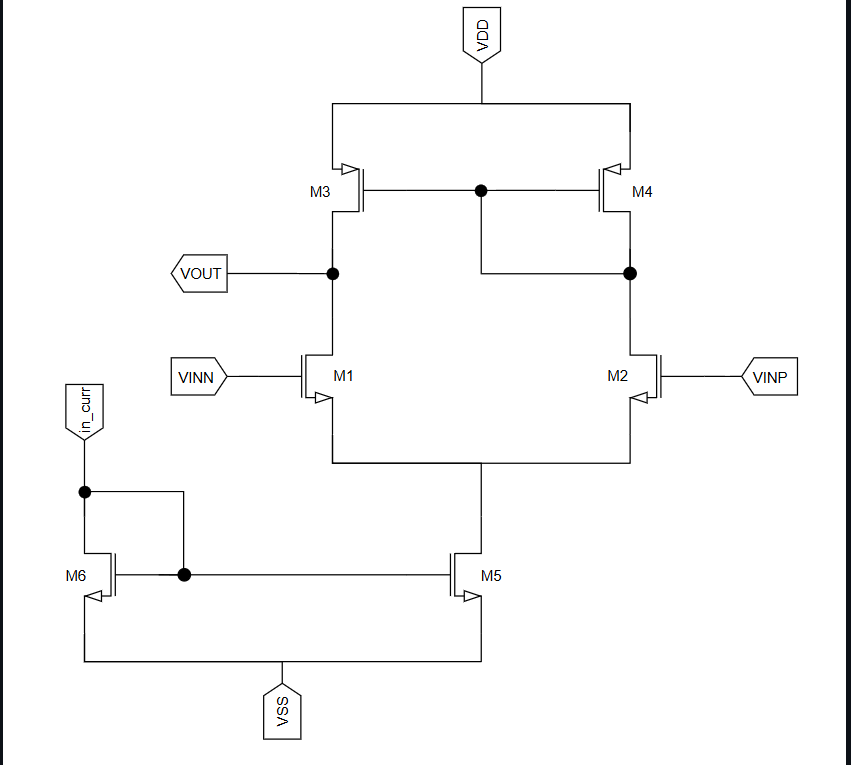

In [ ]:
nmos_kwargs = {
    "with_tie": False,                        # add tie layer for bulk connection
    "with_dnwell": False,                     # deep n-well for substrate isolation
    # top metal layer for source/drain routing
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",              # top metal layer for gate routing
    "sd_route_left": True,                    # route source/drain to the left
    # metal width multiplier for source/drain (None = default)
    "rmult": None,
    "gate_rmult": 1,                          # metal width multiplier for gate
    "interfinger_rmult": 1,                   # metal width multiplier between fingers
    "substrate_tap_layers": ("met2", "met1"),  # layers for substrate tap
    "dummy_routes": True                      # add routing to dummy fets
}

pmos_kwargs = {
    "with_tie": False,
    "dnwell": False,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2", "met1"),
    "dummy_routes": True
}

config = {
    "pdk": gf180,

    # Differential Input Pair (M1, M2) — NMOS
    "input_pair": {
        "width": 5.75,
        "length": 0.4,
        "fingers": 2,
        "multipliers": 1,
        "device_type": "nmos",
    },

    # Current Mirror Load (M3, M4) — PMOS
    "current_mirror": {
        "width": 8.45,
        "length": 0.4,
        "fingers": 5,
        "multipliers": 1,
        "device_type": "pmos",
    },

    # Tail Current Source (M5) — NMOS
    "tail_source": {
        "width": 9.55,
        "length": 0.7,
        "fingers": 5,
        "multipliers": 1,
        "device_type": "nmos",
    },

    # Layout and routing rules
    "layout_rules": {
        "spacing": 2.0,
        "routing_metal": "met2",
        "dummy_devices": True,
        "tie_layers": ("met2", "met1"),   # tapring metal layers
        "sd_rmult": 1,                    # source/drain metal width multiplier
    }
}


def current_mirror(pdk, config):
    cm_comp = Component(name="current_mirror")

    # Extract parameters from config
    width = config["current_mirror"]["width"]
    length = config["current_mirror"]["length"]
    fingers = config["current_mirror"]["fingers"]
    multipliers = config["current_mirror"]["multipliers"]
    tie_layers = config["layout_rules"]["tie_layers"]
    sd_rmult = config["layout_rules"]["sd_rmult"]

    # Instantiate two PMOS transistors
    pfet_m4 = pmos(pdk, width=width, length=length, fingers=fingers,
                   multipliers=multipliers,
                   with_substrate_tap=False,
                   with_dummy=(False, True),
                   tie_layers=tie_layers,
                   sd_rmult=sd_rmult,
                   **pmos_kwargs)

    pfet_m3 = pmos(pdk, width=width, length=length, fingers=fingers,
                   multipliers=multipliers,
                   with_substrate_tap=False,
                   with_dummy=(True, False),
                   tie_layers=tie_layers,
                   sd_rmult=sd_rmult,
                   **pmos_kwargs)

    cm4_ref = cm_comp << pfet_m4
    cm3_ref = cm_comp << pfet_m3
    cm4_ref.name = "pfet_m4"
    cm3_ref.name = "pfet_m3"

    # Placement: move pfet_m4 to the right of pfet_m3
    cm4_ref.movex(evaluate_bbox(pfet_m3)[0] + pdk.util_max_metal_seperation())

    # Tapring enclosure
    tap_ring = tapring(pdk,
                       enclosed_rectangle=evaluate_bbox(
                           cm_comp.flatten(),
                           padding=pdk.get_grule("nwell", "active_diff")["min_enclosure"]),
                       sdlayer="n+s/d",
                       horizontal_glayer=tie_layers[0],
                       vertical_glayer=tie_layers[1])
    shift_amount = -prec_center(cm_comp.flatten())[0]
    tring_ref = cm_comp << tap_ring
    tring_ref.movex(destination=shift_amount)

    # nwell padding to merge the two separate nwell regions
    cm_comp.add_padding(layers=(pdk.get_glayer("nwell"),), default=1)

    # Internal routing
    cm_comp << straight_route(pdk, cm4_ref.ports["multiplier_0_source_E"],
                              cm3_ref.ports["multiplier_0_source_E"])
    cm_comp << straight_route(pdk, cm4_ref.ports["multiplier_0_gate_E"],
                              cm3_ref.ports["multiplier_0_gate_E"])
    cm_comp << c_route(pdk, cm4_ref.ports["multiplier_0_gate_E"], 
                       cm4_ref.ports["multiplier_0_drain_E"])

    # Route dummy to tapring (We have to route it manually since we generated the tapring manually)
    cm_comp << straight_route(pdk, cm3_ref.ports["multiplier_0_dummy_L_gsdcon_top_met_E"],
                              tring_ref.ports["W_top_met_W"])
    cm_comp << straight_route(pdk, cm4_ref.ports["multiplier_0_dummy_R_gsdcon_top_met_W"],
                              tring_ref.ports["E_top_met_E"])

    # Expose ports
    cm_comp.add_ports(cm4_ref.get_ports_list(), prefix="M4_")
    cm_comp.add_ports(cm3_ref.get_ports_list(), prefix="M3_")
    cm_comp.add_ports(tring_ref.get_ports_list(), prefix="TRING_")

    return cm_comp

In [ ]:
top_level = Component(name="current_mirror")
pdk = config["pdk"]

cm = current_mirror(pdk, config)
cm_ref = top_level << cm
cm_ref.name = "current_mirror"

display_component(top_level, scale=3)
# top_level.show()

In [ ]:
def diff_pair(pdk, config):
    dp_comp = Component(name="diff_pair")

    # Extract parameters from config
    width = config["input_pair"]["width"]
    length = config["input_pair"]["length"]
    fingers = config["input_pair"]["fingers"]
    multipliers = config["input_pair"]["multipliers"]
    tie_layers = config["layout_rules"]["tie_layers"]
    sd_rmult = config["layout_rules"]["sd_rmult"]

    # Instantiate two NMOS transistors
    m1 = nmos(pdk, width=width, length=length, fingers=fingers,
              multipliers=multipliers,
              with_substrate_tap=False,
              with_dummy=(True, False),
              tie_layers=tie_layers,
              sd_rmult=sd_rmult,
              **nmos_kwargs)
    m2 = nmos(pdk, width=width, length=length, fingers=fingers,
              multipliers=multipliers,
              with_substrate_tap=False,
              with_dummy=(False, True),
              tie_layers=tie_layers,
              sd_rmult=sd_rmult,
              **nmos_kwargs)

    m1_ref = dp_comp << m1
    m2_ref = dp_comp << m2
    m1_ref.name = "M1"  # negative input
    m2_ref.name = "M2"  # positive input

    # Placement
    ref_dimensions = evaluate_bbox(m1)
    m2_ref.movex(m1_ref.xmax)
    m2_ref.movex(ref_dimensions[0] / 2)
    m2_ref.movex(pdk.util_max_metal_seperation())

    # Connect sources together
    dp_comp << straight_route(pdk,
                              m1_ref.ports["multiplier_0_source_E"],
                              m2_ref.ports["multiplier_0_source_W"])

    # Tapring enclosure
    tap_ring = tapring(pdk, enclosed_rectangle=evaluate_bbox(
        dp_comp.flatten(),
        padding=pdk.get_grule("nwell", "active_diff")["min_enclosure"]))
    shift_amount = -prec_center(dp_comp.flatten())[0]
    tring_ref = dp_comp << tap_ring
    tring_ref.movex(destination=shift_amount)

    # Route dummy to tapring (We have to route it manually since we generated the tapring manually)
    dp_comp << straight_route(pdk, m1_ref.ports["multiplier_0_dummy_L_gsdcon_top_met_E"],
                              tring_ref.ports["W_top_met_W"])
    dp_comp << straight_route(pdk, m2_ref.ports["multiplier_0_dummy_R_gsdcon_top_met_W"],
                              tring_ref.ports["E_top_met_E"])

    # Expose ports
    dp_comp.add_ports(m1_ref.get_ports_list(), prefix="M1_")
    dp_comp.add_ports(m2_ref.get_ports_list(), prefix="M2_")
    dp_comp.add_ports(tring_ref.get_ports_list(), prefix="TRING_")

    return dp_comp


dp = diff_pair(pdk, config)
dp_ref = top_level << dp
dp_ref.name = "diff_pair_2"

display_component(top_level, scale=3)

In [ ]:
def tail_current(pdk, config):
    tail_comp = Component(name="tail_current")

    # Extract parameters from config
    width = config["tail_source"]["width"]
    length = config["tail_source"]["length"]
    fingers = config["tail_source"]["fingers"]
    multipliers = config["tail_source"]["multipliers"]
    tie_layers = config["layout_rules"]["tie_layers"]
    sd_rmult = config["layout_rules"]["sd_rmult"]

    # Instantiate two NMOS transistors
    nfet_m6 = nmos(pdk, width=width, length=length, fingers=fingers,
                   multipliers=multipliers,
                   with_substrate_tap=False,
                   with_dummy=(False, True),
                   tie_layers=tie_layers,
                   sd_rmult=sd_rmult,
                   **nmos_kwargs)

    nfet_m5 = nmos(pdk, width=width, length=length, fingers=fingers,
                   multipliers=multipliers,
                   with_substrate_tap=False,
                   with_dummy=(True, False),
                   tie_layers=tie_layers,
                   sd_rmult=sd_rmult,
                   **nmos_kwargs)

    m6 = tail_comp << nfet_m6
    m5 = tail_comp << nfet_m5
    m6.name = "nfet_m6"
    m5.name = "nfet_m5"

    # Placement
    m6.movex(evaluate_bbox(nfet_m5)[0] + pdk.util_max_metal_seperation())

    # Tapring enclosure
    tap_ring = tapring(pdk, enclosed_rectangle=evaluate_bbox(
        tail_comp.flatten(),
        padding=pdk.get_grule("nwell", "active_diff")["min_enclosure"]))
    shift_amount = -prec_center(tail_comp.flatten())[0]
    tring_ref = tail_comp << tap_ring
    tring_ref.movex(destination=shift_amount)

    # Internal routing
    tail_comp << straight_route(pdk, m6.ports["multiplier_0_source_E"],
                                m5.ports["multiplier_0_source_E"])
    tail_comp << straight_route(pdk, m6.ports["multiplier_0_gate_E"],
                                m5.ports["multiplier_0_gate_E"])
    tail_comp << c_route(pdk, m6.ports["multiplier_0_gate_E"],
                         m6.ports["multiplier_0_drain_E"])

    # Route dummy to tapring (We have to route it manually since we generated the tapring manually)
    tail_comp << straight_route(pdk, m5.ports["multiplier_0_dummy_L_gsdcon_top_met_E"],
                                tring_ref.ports["W_top_met_W"])
    tail_comp << straight_route(pdk, m6.ports["multiplier_0_dummy_R_gsdcon_top_met_W"],
                                tring_ref.ports["E_top_met_E"])

    # Expose ports
    tail_comp.add_ports(m6.get_ports_list(), prefix="M6_")
    tail_comp.add_ports(m5.get_ports_list(), prefix="M5_")
    tail_comp.add_ports(tring_ref.get_ports_list(), prefix="TRING_")
    return tail_comp


tail = tail_current(pdk, config)
tail_ref = top_level << tail
tail_ref.name = "tail_current"

display_component(top_level, scale=3)

In [ ]:
dp_dimensions = evaluate_bbox(dp)
tail_dimensions = evaluate_bbox(tail)
cm_dimensions = evaluate_bbox(cm)

# Place diff_pair below current_mirror
dp_ref.movey(cm_ref.ymin - dp_dimensions[1] /
             2 - pdk.util_max_metal_seperation())

display_component(top_level, scale=3)

In [ ]:
# Place tail_current right of current_mirror
tail_ref.movex(
    cm_ref.xmax + tail_dimensions[0]/2 + pdk.util_max_metal_seperation())

display_component(top_level, scale=2)